# Heat and running performance: modeling equal-effort pace

**Machine Learning & Deep Learning**

The summer of 2026 gave the link between weather and athletic performance a particular topicality. June 2026 was the hottest June ever recorded in France (+3.8 °C above normal). July then broke the all-time monthly heat record since measurements began, with a national average of 24.9 °C (Météo-France). These conditions did not prevent elite athletes from performing, at the cost of adjustments. For the first time in its history, the Tour de France shortened a stage because of the heat (Malemort-Ussel, July 12). At the Paris Diamond League meeting on June 28, only the professional events were held, and they produced world-class times: 1:53.80 for Audrey Werro over 800 m, the third best performance in history, and 3:28.00 for Cameron Myers over 1,500 m. Amateur athletes, on the other hand, suffered a great deal. They have neither medical support nor adjusted schedules, and had to keep up their training sessions through several weeks of heatwave.

At the same time, heat training has become popular. The World Athletics Championships in Tokyo, in September 2025, were held in temperatures above 30 °C and humidity above 80%. Federations prepared their athletes in climatic chambers, at training camps in hot climates and with cooling protocols. World Athletics launched a study on the acclimatization of its marathon runners and race walkers. It builds on the Doha championships (2019): 63% of the athletes surveyed there had followed a specific heat preparation, and those athletes had generally performed better.

Amateurs obviously have no access to climatic chambers or to the physiological monitoring of professional athletes. Yet the benefits of acclimatization are well established. The expert consensus of Racinais et al. (2015) identifies it as the most effective intervention to reduce physiological strain and preserve performance in hot environments: repeated exposures to exercise in the heat over one to two weeks. Lorenzo et al. (2010) even observed, in trained cyclists, a performance gain of about 7% after ten days of acclimatization, including in cool conditions. Rønnestad et al. (2022) showed that five weeks of training in a heat suit increase the hemoglobin mass of elite cross-country skiers, by about 30 g more than in the control group. The benefits of heat training are therefore well and truly established.

Beyond any deliberate preparation, one does not choose the weather. A runner regularly has to complete a planned session in strong heat or high humidity, and the same pace no longer corresponds to the same effort. Running at the planned pace then amounts to a harder session than intended, with a risk of drifting from the initial training plan, or even for health. Sensations remain the safest guide for training in difficult conditions: listening to one's body and slowing down when the effort becomes too costly protects better than any target pace. A more delicate question remains: by how much do weather conditions actually slow a runner down at equal effort? Answering it would make it possible to adjust one's pace in advance rather than by feel, to interpret fairly a time achieved in strong heat, or to compare two sessions run in different conditions. It is this impact that this project seeks to quantify.

Several studies have addressed this question. Ely et al. (2007) analyzed seven major marathons. Among the best men, the gap to the course record rises from 1.7% for a WBGT of 5 to 10 °C to 4.5% between 20 and 25 °C, and slower runners are affected even more. Mantzios et al. (2022) extended the analysis to 1,258 endurance races (from the 3,000 m steeplechase to the marathon, 1936-2019, 42 countries). They place the best performances between 7.5 and 15 °C of WBGT, with a decline of 0.3 to 0.4% per degree beyond. The reference indicator in these studies is the WBGT (Wet Bulb Globe Temperature). It combines air temperature, humidity, wind and solar radiation into a single measure of heat stress (WBGT = 0.7 T<sub>natural wet bulb</sub> + 0.2 T<sub>globe</sub> + 0.1 T<sub>air</sub>). It is used by the ACSM and World Athletics to set their risk thresholds. These studies, however, describe winners' performances, aggregated by race. They do not directly tell a runner what pace to run today to produce the same effort as in ideal conditions.

This is the purpose of this project. We built a data set of about 21,000 performances, from the 800 m to the marathon, achieved between 2023 and 2026 in 100 cities across 36 countries. Each performance is expressed relative to the athlete's personal best before the race. For each one, we reconstructed the weather at the time and place of the race from hourly reanalysis data (ERA5), and computed the WBGT averaged over the race duration with the physical model of Liljegren et al. (2008). On this basis, we compare several models of increasing complexity: penalized linear regressions, a mixed model, gradient boosting and a neural network. They are evaluated on cities never seen during training. The model retained feeds a pace conversion tool: for a target speed in reference conditions and given weather, it provides the equivalent speed at equal effort, with its confidence interval.

## Part 0 — Introduction

### 0.1 The question

> *For a given temperature $T$ and relative humidity $RH$ (and, when known, wind, solar
> radiation and altitude), at what actual speed $X$ should I run to produce the same
> effort as at speed $Y$ in reference conditions?*

To answer this question, we analyze several thousand actual race performances
(800 m to marathon, on the track and on the road, in about a hundred cities across 36 countries, 2023-2026). Since
effort is not measured, the approach is indirect: we first learn **by how much conditions
slow an athlete down relative to their own level**, then we **invert** this model to
convert a reference speed into an "equal-effort" speed (part 0.4).

### 0.2 Physiological background: thermoregulation during exercise

The runner's heat balance reads (in W):

$$S = M - W_{\text{mech}} \pm R \pm C - E,$$

* $S$ is the heat **stored** by the body: if $S > 0$ persistently, core temperature rises;
* $M$ is the **metabolic** energy production of the muscles;
* $W_{\text{mech}}$ is the **mechanical work** performed. Since muscular efficiency is only 20 to 25%,
  about three quarters of $M$ end up as heat;
* $R$ and $C$ are the exchanges by **radiation** (sun, ground, surroundings) and by **convection**
  (contact with moving air); they can cool the runner or heat them, hence the $\pm$ sign;
* $E$ is the loss through **evaporation** of sweat.

In running, the energy cost is about $4\ \text{J kg}^{-1}\text{m}^{-1}$. At $5.5$ m/s (the pace
of a 2:08 marathon), a 60 kg athlete therefore expends $4 \times 60 \times 5.5 \approx 1{,}300$ W:
with an efficiency of 20 to 25%, more than 1,000 W of heat must be dissipated continuously,
the equivalent of an electric heater.

* When air temperature approaches skin temperature (~33-35 °C), $C$ and $R$ become
  small, or even negative: only **evaporation** remains.

* Evaporation depends on the water vapor pressure difference between skin and air: it is hindered
  by **humidity**. Hot, saturated air is the most unfavorable case.

* **Solar radiation** adds a load of several hundred W/m²; **wind**, on the
  contrary, increases convective and evaporative exchanges.

If heat is not dissipated, core temperature rises. Skin blood flow, needed to
carry heat to the skin, then competes with muscle blood flow: the heart cannot
supply both at their maximum. The effective $\dot V O_2\max$ drops and the athlete slows down, often
**in anticipation**: they regulate their pace so as not to reach a critical temperature, before even
getting there. The effect **grows with the duration** of the effort, because the stored heat $S$ accumulates over
time. It is small over 800 m (about two minutes), where core temperature does not have time to
rise and where warm, less dense air may even help by reducing aerodynamic drag; it
becomes large in the marathon (two to three hours). In international championships, Mantzios *et al.* (2022)
find an optimum WBGT between 7.5 and 15 °C and a degradation of about 0.3 to
0.4% per °C beyond. Ely *et al.* (2007) observe in the marathon a
progressive slowdown from 5 to 25 °C of WBGT, more pronounced among slower runners.

**Altitude.** Atmospheric pressure, and with it the partial pressure of oxygen, decreases by about
11% per 1,000 m of altitude. The blood carries less oxygen, and $\dot V O_2\max$ drops by about
6 to 8% per 1,000 m above ~500-1,000 m. Endurance events, limited by oxygen supply,
suffer from it, whereas short events benefit from the lower air density. The data set
contains races in Mexico City (~2,200 m), Bogotá (~2,600 m), Kigali, Boulder, Guadalajara or
Lanzhou (~1,500 m).

### 0.3 The WBGT (*Wet Bulb Globe Temperature*)

The WBGT combines into a single index, expressed in °C, the four factors of the heat balance (temperature,
humidity, wind, radiation):

$$\text{WBGT} = 0.7\,T_{nwb} + 0.2\,T_{g} + 0.1\,T_{a},$$

* $T_{nwb}$: temperature of a **natural wet-bulb** thermometer, surrounded by a wet wick, not
  artificially ventilated and exposed to the sun. The evaporating water cools the bulb, all the more so as
  the air is dry and windy: $T_{nwb}$ measures the capacity of the environment to remove heat by
  evaporation, as sweat does. In saturated air, evaporation stops and $T_{nwb}$ joins $T_a$;
* $T_{g}$: temperature of a hollow **black globe**, which absorbs radiation (sun, ground)
  and is cooled by the wind: it measures the radiative load;
* $T_{a}$: air temperature in the shade.

The weights reflect the dominant role of evaporation in thermoregulation during exercise: with 70%
of the weight on $T_{nwb}$, humidity strongly increases the WBGT at equal temperature, and the WBGT is not
a mere temperature (part 1.2).

Since these quantities are not measured on the courses, they were **computed** with the physical model of
Liljegren *et al.* (2008), the reference method for estimating the WBGT from standard
meteorological measurements. The model writes the energy balance of the wet wick and that of the globe
(direct and diffuse solar radiation, thermal radiation, convection, evaporation) and solves them
numerically from temperature, humidity, wind speed, global solar radiation, pressure and the
position of the sun, computed from the date, the time and the coordinates of the site. The implementation
used (`wbgt_liljegren.py`) reproduces the original Argonne C code to within 0.01 °C. The WBGT was
computed **every 5 minutes, from the start to the finish of each athlete**, then averaged. A 2:50
marathon runner thus experiences the rise in temperature at the end of the morning, unlike a 2:05 winner;
part 1.2 shows that this drift reaches a median of 3.7 °C in the marathon.

Guidelines of the American College of Sports Medicine (Armstrong *et al.*, 2007) for races:

| WBGT | < 10 °C | 10-18 °C | 18-23 °C | 23-28 °C | > 28 °C |
|---|---|---|---|---|---|
| Flag | white (risk of hypothermia) | green | yellow | red | black (cancellation) |

### 0.4 Problem formulation: what do we predict?

The approach is purely "data-driven": no physiological measurement (heart rate, lactate,
perceived exertion) is available. We therefore approximate effort by **race
performance**, assuming that an athlete in a race produces a **maximal effort**: if they run more
slowly than usual in strong heat, it is because heat costs them speed at equal effort.
This assumption has its limits (some athletes "play it safe" in strong heat), discussed in part 11.
Each performance must then be compared with a **reference specific to the athlete**, to neutralize their
level, sex and event.

**The target.** For performance $i$, with time $t_i$, by an athlete whose **personal best before the
race** is $t_i^{\text{PB}}$:

$$\boxed{\,y_i = 100\,\ln\frac{t_i}{t_i^{\text{PB}}}\,}$$

**Why a logarithm?**

* **A reading as a percentage.** For small $x$, $\ln(1 + x) \approx x$. If $t = 1.02\,t^{\text{PB}}$,
  then $y = 100 \ln 1.02 \approx 1.98$. $y_i$ is therefore expressed in "logarithmic percent":
  $y = 2$ means about 2% slower than one's personal best.
* **Symmetry.** $\ln(t/t^\star) = -\ln(t^\star/t)$: being 2 points above or below one's
  best is treated in the same way, which is not the case for the ratio $t/t^\star - 1$.
* **Time or speed, it is the same.** Over a fixed distance $d$, $v = d/t$, hence
  $\ln(t/t^\star) = \ln(v^\star/v)$: $y$ is also a relative **speed** gap, which will make it possible to
  convert the result directly into a pace.
* **Additivity.** Multiplicative effects on time become additive on $y$: if heat
  multiplies the time by $e^{\delta_1/100}$ and altitude by $e^{\delta_2/100}$, $y$ increases by $\delta_1 + \delta_2$. This is the form
  suited to linear models.

$y < 0$ corresponds to a new personal best. This is the case for 41% of the 14,823 valid performances, but for
only 32% of the analysis sample retained below: the difference comes from the truncation of the
lists (part 1.5).

**Why the pre-race personal best?** It is published **before** the race and was set
**elsewhere**, in other conditions: it measures the athlete's level independently of the day's
weather. A reference that included the race itself would create an artifact: with the season's best
race included, a race run in excellent conditions would become
its own reference, and we would have $y \geq 0$ by construction. The pre-race personal best is moreover
available for 71% of performances, against 36% for the pre-race season's best (SB),
which serves as a **form** variable (part 1.1).

**The truncation pitfall (key point).** Result lists are **truncated by time**.
Major marathons only list men under 2:37 and women under 3:05, and small
races only their first finishers. Let $T^{\max}_c$ denote the time of the last runner listed in race
$c$. An athlete appears only if $t_i \le T^{\max}_c$, that is, if $y_i \leq m_i = 100 \ln \frac{T_c^{\max}}{t_i^{\text{PB}}}$, which biases the effect of heat toward $0$; we will come back to this.

In strong heat, an athlete whose best is close to the threshold and who slows down **disappears from the data**: we only see
those who ran well relative to their level. The observed mean of $y$ is then pulled
down, and the effect of heat **underestimated**. To remedy this, we only keep athletes whose
margin exceeds $M$%. For them, any slowdown up to $M$% remains observable. Part 1.5 gives
an illustration, a formal proof and an empirical measurement.

**Confounding factors.** A **confounding** factor is a variable $Z$ that influences both
the exposure studied (here the WBGT, denoted $W$) and performance $y$. If it is omitted, its effect is
wrongly attributed to the WBGT. Suppose that the true model is $y = \beta_0 + \beta_W W + \beta_Z Z + \varepsilon$, with $\varepsilon$ uncorrelated with $W$ and $Z$,
and that $y$ is regressed on $W$ alone. The estimated slope tends to

$$\frac{\text{Cov}(W, y)}{\text{Var}(W)} = \frac{\beta_W\,\text{Var}(W) + \beta_Z\,\text{Cov}(W, Z)}{\text{Var}(W)}
= \beta_W + \beta_Z\,\frac{\text{Cov}(W, Z)}{\text{Var}(W)} .$$

This is the **omitted-variable bias**. Its sign is that of the product $\beta_Z \times \text{Cov}(W, Z)$: to
predict in which direction a factor biases the effect of heat, one must know both its effect on
$y$ and its link with the WBGT (part 1.4). Of course, many confounding factors have to be controlled.
We chose to exclude championship races, too prone to race tactics.
Among the unavoidable confounding factors, we pay particular attention to the athlete's profile
(level, age, sex), to the event considered, to the course and to the schedule (which generally corresponds
to the start of the meeting).

**Using the model both ways.** If $f$ predicts $y$, the degradation due to conditions $\mathcal{C}$
relative to reference conditions $\mathcal{C}_{\text{ref}}$ (WBGT of `WBGT_REF` °C, light breeze, sea
level, no rain) is

$$\Delta(\mathcal{C}) = f(\mathcal{C}, x) - f(\mathcal{C}_{\text{ref}}, x)\quad\text{(in points of } y\text{)}.$$

Suppose the athlete runs at speed $Y$ (time $t_Y$) in reference conditions and at speed
$X$ (time $t_X$) in conditions $\mathcal{C}$, for the same effort. The difference in target between the two
situations is

$$\Delta = 100\ln\frac{t_X}{t^{\text{PB}}} - 100\ln\frac{t_Y}{t^{\text{PB}}} = 100\ln\frac{t_X}{t_Y} = 100\ln\frac{Y}{X},$$

and the "equal-effort" speed is therefore

$$X = Y\,\exp\!\left(-\frac{\Delta(\mathcal{C})}{100}\right) \qquad \Big(\text{that is, } X \approx Y\,(1 - \Delta/100) \text{ to first order}\Big).$$

$\Delta$ depends on the athlete's level and race duration, hence on $Y$. The inverse operation
("I ran at $X$ at 30 °C, what is it worth in reference conditions?") therefore requires
solving $Y\,e^{-\Delta(\mathcal{C};Y)/100} = X$ numerically (part 10).

**The choice of the reference conditions.** The reference WBGT is 15 °C, the upper end of the "neutral" range
of 10 to 15 °C in the literature. A cooler reference would fall outside the track data, which
never go below 13.5 °C (part 1.2): the model could not be evaluated there without extrapolating. The
reference wind is a light breeze (2 m/s at 10 m), the reference altitude below 500 m.

### 0.5 Notation

Notation is introduced as the document goes along, and each symbol keeps the same meaning from one part to the next. The
following table gathers it, in order of appearance. Summation indices and the constants of an
isolated computation are defined locally, where they are used.

| symbol | meaning | introduced in |
|---|---|---|
| $i = 1, \dots, n$ | index of a performance (observation); $n$: number of performances | 0.4 |
| $t_i$, $t_i^{\text{PB}}$ | time of performance $i$, athlete's personal best before the race | 0.4 |
| $y_i = 100\ln(t_i/t_i^{\text{PB}})$ | target: logarithmic gap to the personal best, in points (≈ %) | 0.4 |
| $W$, $W_{\text{ref}}$ | race-averaged WBGT, reference WBGT (15 °C) | 0.3, 0.4 |
| $c$, $T^{\max}_c$ | index of a race, time of the last runner listed in race $c$ | 0.4 |
| $m_i$, $M$ | truncation margin of performance $i$, minimum margin required | 0.4 |
| $\mathcal{C}$, $\mathcal{C}_{\text{ref}}$ | weather conditions of the day, reference conditions | 0.4 |
| $\Delta(\mathcal{C})$, $\Delta(W)$ | degradation due to the conditions (or to the WBGT alone), in points of $y$ | 0.4, 8.2 |
| $X$, $Y$ | (parts 0.4 and 10) speed in the conditions of the day, reference speed | 0.4 |
| $x_i \in \mathbb{R}^d$, $f_\theta$, $\hat y$ | explanatory variables, predictor with parameters $\theta$, prediction | 0.5 |
| $\ell$, $\hat{\mathcal{R}}$ | loss, empirical risk $\frac1n\sum_i \ell(f_\theta(x_i), y_i)$ | 0.5 |
| $\beta_0$, $\beta_W$, $\beta_Z$ | intercept, effect of the WBGT, effect of a confounding factor $Z$ | 0.4 |
| $\text{skew}$, $\text{kurt}$ | skewness, excess kurtosis | 1.2 |
| $e$, $\pi_{e \mid b}$ | index of an event group, share of group $e$ in class $b$ | 1.3 |
| $\beta_1$, $\varepsilon$, $\sigma^2$ | slope of a simple regression, random error, variance of the error | 1.5 |
| $\nu$ | additional degrees of freedom removed (`ddl_perdus`) | 1.5 |
| $\varphi$, $\Phi$, $\Lambda$ | density and cumulative distribution function of $\mathcal N(0, 1)$, inverse Mills ratio $\varphi/\Phi$ | 1.5 |
| $g$, $j$, $n_g$, $G$, $N$ | index of a group (race, course or venue), index of an athlete in the group, group size, number of groups, total number of observations | 1.6 |
| $u_g$, $\tau^2$ | random effect of group $g$, its variance | 1.6, 4.1 |
| $k$, $K$, $\mathcal{A}_k$, $\mathcal{V}_k$ | index of a fold, number of folds, training and validation sets of fold $k$ | 2.1 |
| $\bar W_g$ | mean WBGT of course $g$ (Mundlak term) | 2.3 |
| $X \in \mathbb{R}^{n \times (p+1)}$, $\beta$ or $w$ | design matrix, coefficients of a linear model | 3.2 |
| $\lambda$ | regularization coefficient (ridge, leaf weights, *weight decay*) | 3.2 |
| $\psi(W)$, $D$ | polynomial basis of the WBGT, degree | 3.3 |
| $V_g$, $\gamma = \tau^2/\sigma^2$, $\omega_g$ | covariance of group $g$, variance ratio, quasi-demeaning fraction | 4.1 |
| $G_i$, $H_i$, $w_l$, $F$, $\kappa$ | gradient and Hessian of the loss, value of leaf $l$, number of leaves, minimum gain of a split | 5.1 |
| $\eta$, $n_{\text{trees}}$ | learning rate (boosting, network), number of trees | 5.1 |
| $h_k$, $W_k$, $b_k$, $L$, $\sigma(\cdot)$ | layer $k$ of a network, its weights and biases, number of hidden layers, activation | 6.1 |
| $d_e$, $n_{\text{batch}}$, $n_{\text{mod}}$ | dimension of an *embedding*, mini-batch size, number of networks in an ensemble | 6.2 to 6.5 |
| $B$ | number of bootstrap replicates | 7.2 |
| $\phi_j$ | Shapley value of variable $j$ | 8.1 |
| $\text{PD}_v$ | partial dependence on variable $v$ | 8.2 |
| $\alpha$, $\hat q$, $\rho_\alpha$, $s_i$, $\hat I(x)$ | error level, conformal quantile, *pinball* loss, nonconformity score, prediction interval | 9 |

By convention, two symbols keep two distant meanings: $X$ denotes a speed in parts 0.4 and 10, and the
design matrix elsewhere; $\sigma$ denotes a standard deviation, except in part 6 where it denotes an activation
function.

### 0.6 Setup

All experiments use a single random seed (`SEED = 0`), so as to be exactly reproducible. The
common constants are the target (`y_pct`), the reference WBGT (15 °C) and the five event groups (part 1.1).
The module `wbgt_liljegren.py` must be in the same folder as the notebook (part 10). The event groups keep their
French labels in the data (`"demi-fond piste"`, `"fond piste"`, `"route courte"`, `"semi-marathon"`, `"marathon"`);
the dictionary `NOMS_EN` gives their English names for tables and figures (track middle distance, track long distance,
short road, half marathon, marathon). Likewise, the column names of the data set and the names of the functions remain in
French.

In [1]:
import os, sys, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 0                       # single seed: all random draws depend on it
CHEMIN_DONNEES = "dataset_ml.csv"
CIBLE = "y_pct"
WBGT_REF = 15.0        # reference conditions (°C): upper end of the "neutral" 10-15 °C range, covered by all groups
GROUPES = ["demi-fond piste", "fond piste", "route courte", "semi-marathon", "marathon"]
# English display names of the event groups (the values in the data stay in French)
NOMS_EN = {"demi-fond piste": "track middle distance", "fond piste": "track long distance",
           "route courte": "short road", "semi-marathon": "half marathon", "marathon": "marathon"}
t0_notebook = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 2.2.3


### 0.7 Execution environment: making LightGBM and PyTorch coexist

This subsection is technical: it does not concern modeling, but the possibility of running the notebook
from start to finish. It can be read when PyTorch appears (part 6).

#### The problem encountered

Run in one go on macOS, the notebook **crashes** (segmentation fault, the Python kernel stops) or **hangs**
indefinitely as soon as PyTorch performs a computation after LightGBM has been used in the same kernel, that is, from
part 6 onward. Each of the two libraries works perfectly on its own; it is their presence **in the same process**
that causes the problem. In an Anaconda environment, a second conflict of the same kind appears: PyTorch also crashes
when it computes after scipy and statsmodels have been used.

#### The diagnosis: two OpenMP engines in the same process

To speed up their computations, LightGBM and PyTorch spread the work over several processor cores thanks to
**OpenMP**, a parallel computing library. The OpenMP engine (the *runtime*, here `libomp`) creates and manages a
set of **threads** that work in parallel. Yet each of the two libraries, installed
with `pip`, ships **its own copy** of this engine: LightGBM loads an external `libomp`, PyTorch loads the one it
provides in its own folder. The two copies end up loaded in the same process, each with its internal state
and its threads, and they step on each other: the behavior is undefined, hence the crashes and
hangs.

#### Processes and threads

A **process** is a running program, with its own memory space: the Jupyter kernel that runs
this notebook is one. A **thread** is a unit of work **inside** a process:
all the threads of a process share the same memory and the same loaded libraries. This distinction explains
why fixes acting on threads fail. We tried:

| attempt | principle | result |
|---|---|---|
| `torch.set_num_threads(1)` | a single computation thread for PyTorch | crash |
| `OMP_NUM_THREADS=1` | a single thread for all of OpenMP | hang |
| `KMP_DUPLICATE_LIB_OK=TRUE` | tolerate two copies of OpenMP | crash |
| `DYLD_LIBRARY_PATH` toward PyTorch's copy | force a single copy | crash |
| import PyTorch first | loading order | fixes the conflict with statsmodels, not the one with LightGBM |

Reducing the number of threads does not remove the problem: both engines remain **loaded and initialized** in the same
process. Only a separation at the level of **processes**, which each have their own memory and their own
libraries, truly isolates the two engines.

#### The solution: a process dedicated to PyTorch

The notebook is spread over two processes:

| | main process (the notebook kernel) | PyTorch process |
|---|---|---|
| libraries | numpy, pandas, scikit-learn, statsmodels, LightGBM, SHAP | PyTorch, imported first, and numpy |
| PyTorch | **never imported** | trains the networks and computes their predictions |
| LightGBM | used | **never loaded** |
| start | that of the notebook | at the first call, then reused |

Data preprocessing (imputation, standardization, category coding) stays in the main process.
It sends **numpy arrays** (variables, target, hyperparameters) to the PyTorch process and receives
numpy arrays in return: the **weights** of the trained networks and their **predictions**. PyTorch objects never
cross the boundary between the two processes, which avoids loading PyTorch in the main process.

A few technical choices deserve to be justified:

* **The `spawn` method.** A process can be created by **duplicating** the current process (`fork`) or by starting
  a **new Python interpreter** (`spawn`). A duplication would copy the kernel's memory, including LightGBM's already
  initialized OpenMP engine, which is a known source of hangs. With `spawn`, the PyTorch process starts from a clean
  state and only loads what it needs.
* **Modules rather than notebook functions.** A process started with `spawn` does not see the functions
  defined in the notebook cells: it only knows the Python modules it can import. The PyTorch code is
  therefore written in two files, next to the notebook: `processus_torch.py` (the calling mechanism, below) and
  `reseau_torch.py`, which the cells of part 6 fill in with the `%%writefile` command. Their content thus remains
  visible in the notebook, in its place.
* **A reused process.** The PyTorch process is started at the first call, then reused for all the following ones,
  since starting an interpreter and importing PyTorch takes a few seconds. It is restarted automatically if one of the
  two modules has been rewritten, so that it loads the new version.
* **Interruptions.** Jupyter's "Interrupt" button sends an interruption signal (Ctrl-C) to all the
  processes of the kernel. The PyTorch process ignores this signal, so as not to die when it is idle; if the interruption
  occurs during a computation, the main process stops the PyTorch process, which will be restarted at the next call. When
  the kernel shuts down, the PyTorch process is stopped cleanly.

Data travel from one process to the other through **serialization** (*pickle*): a few megabytes at most, which
is negligible compared with training time. Since the computations are identical (same code, same seeds, same number
of threads), the results are exactly those of an execution in a single process.

**Prerequisites.** LightGBM and SHAP must be installed in the kernel's environment (`pip install lightgbm shap`), and the
module `wbgt_liljegren.py` must be in the notebook's folder (part 10). The notebook writes the two modules
`processus_torch.py` and `reseau_torch.py` in this same folder.

The first cell below writes the module `processus_torch.py`. It does not load PyTorch when it is imported:
its "PyTorch process" functions import PyTorch inside their body, and are only executed in the
dedicated process. The second cell imports, in the main process, the two calling functions.

In [2]:
%%writefile processus_torch.py
"""Running PyTorch in a separate process (part 0.7).

The main process of the notebook never imports PyTorch. Everything related to PyTorch runs in a dedicated
process, started with the "spawn" method, which has never loaded LightGBM. The two processes only exchange
numpy arrays. This module imports neither PyTorch nor numpy when loaded: the functions run in the PyTorch
process import them in their body (PyTorch first).
"""
import atexit
import os
import signal
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool

# ------------------------------------------------------------------ main process side
_ETAT = {"pool": None, "versions": None}
_MODULES = ("reseau_torch.py", "processus_torch.py")


def _versions():
    return tuple(os.path.getmtime(f) if os.path.exists(f) else None for f in _MODULES)


def _ignorer_interruptions():
    """Run when the PyTorch process starts: it ignores Ctrl-C (Jupyter's "Interrupt" button)."""
    signal.signal(signal.SIGINT, signal.SIG_IGN)


def arreter(immediatement=False):
    """Stops the PyTorch process (cleanly, or immediately by abandoning the running computation)."""
    pool = _ETAT["pool"]
    if pool is None:
        return
    if immediatement:
        for processus in list(getattr(pool, "_processes", {}).values()):
            processus.terminate()
    pool.shutdown(wait=not immediatement, cancel_futures=True)
    _ETAT["pool"], _ETAT["versions"] = None, None


atexit.register(arreter)


def executer(nom, *args, **kwargs):
    """Runs the function `nom` of this module in the PyTorch process and returns its result.

    The process is started at the first call (spawn method), then reused; it is restarted if one of the two
    modules has been rewritten since, so that it loads the new version. An interruption during a computation
    stops the PyTorch process, which will be restarted at the next call.
    """
    versions = _versions()
    if _ETAT["pool"] is None or _ETAT["versions"] != versions:
        arreter()
        _ETAT["pool"] = ProcessPoolExecutor(max_workers=1, mp_context=mp.get_context("spawn"),
                                            initializer=_ignorer_interruptions)
        _ETAT["versions"] = versions
    try:
        return _ETAT["pool"].submit(_appeler, nom, args, kwargs).result()
    except (KeyboardInterrupt, BrokenProcessPool):
        arreter(immediatement=True)
        raise


def tester(code):
    """Runs a block of code (a test cell) in the PyTorch process and prints its output."""
    print(executer("executer_code", code), end="")


# ------------------------------------------------------------------ PyTorch process side
def _appeler(nom, args, kwargs):
    return globals()[nom](*args, **kwargs)


def executer_code(code):
    """Runs `code` in the namespace of the reseau_torch module and returns what it prints."""
    import contextlib
    import io
    import reseau_torch
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        exec(code, vars(reseau_torch))
    return tampon.getvalue()


def entrainer_ensemble(Xn, Xc, y, Xn_val, Xc_val, y_val, cardinalites, hp, lr, weight_decay, epochs,
                       batch_size, patience, n_modeles, seed):
    """Trains n_modeles ReseauPerf networks. Returns their weights (dicts of numpy arrays) and histories."""
    import torch
    from reseau_torch import ReseauPerf, entrainer_reseau

    def tenseur(a, type_):
        return None if a is None else torch.tensor(a, dtype=type_)

    Xn, Xc, y = tenseur(Xn, torch.float32), tenseur(Xc, torch.long), tenseur(y, torch.float32)
    ev = (tenseur(Xn_val, torch.float32), tenseur(Xc_val, torch.long), tenseur(y_val, torch.float32))
    poids, historiques = [], []
    for k in range(n_modeles):
        torch.manual_seed(seed + k)
        r = ReseauPerf(Xn.shape[1], cardinalites, **hp)
        h = entrainer_reseau(r, Xn, Xc, y, *ev, lr=lr, weight_decay=weight_decay, epochs=epochs,
                             batch_size=batch_size, patience=patience, seed=seed + k)
        r.eval()
        poids.append({nom: t.detach().cpu().numpy().copy() for nom, t in r.state_dict().items()})
        historiques.append(h)
    return poids, historiques


def predire_ensemble(poids, Xn, Xc, cardinalites, hp):
    """Mean prediction (standardized scale) of the networks whose weights are given."""
    import torch
    import numpy as np
    from reseau_torch import ReseauPerf
    Xn, Xc = torch.tensor(Xn, dtype=torch.float32), torch.tensor(Xc, dtype=torch.long)
    predictions = []
    with torch.no_grad():
        for etat in poids:
            r = ReseauPerf(Xn.shape[1], cardinalites, **hp)
            r.load_state_dict({nom: torch.from_numpy(t) for nom, t in etat.items()})
            r.eval()
            predictions.append(r(Xn, Xc).numpy())
    return np.mean(predictions, axis=0)

Overwriting processus_torch.py


In [3]:
# Main process: only the calling mechanism is imported; PyTorch is never imported here.
from processus_torch import executer, tester

## Part 1 — Exploratory analysis geared toward modeling

Exploratory analysis is not an end in itself: it serves to identify what will condition the
modeling, that is, the ranges of conditions covered, the missing combinations, the confounding
factors and the dependence structure between observations.

### 1.1 The data

**Origin and preparation.** The file `dataset_ml.csv` results from a preparation carried out beforehand
(script `preparation_donnees.py`):

1. results of international track and road competitions, from 2023 to 2026: one row per
   performance, with sex, year of birth, event, meeting, city, date, local
   time, time, season's best and personal best published **before** the
   race;
2. geocoding of the cities (coordinates, time zone, altitude);
3. hourly Open-Meteo weather (ERA5 and ERA5-Land reanalyses, IFS model), interpolated at 5-minute steps.
   A **reanalysis** reconstructs past weather on a regular grid (from about 9 to 30 km) by
   assimilating the available observations into a numerical weather prediction model: it is an estimate
   of local weather, not a measurement on the course;
4. Liljegren WBGT every 5 minutes, averaged over each athlete's race (part 0.3);
5. computation of the target and of the context variables, then exclusions.

**The event groups.** The 15 events are grouped into five groups, according to the surface (track or
road) and the duration of the effort, which conditions the expected effect of heat (part 0.2):

| group | events | typical duration |
|---|---|---|
| track middle distance (`demi-fond piste`) | 800 m, 1,000 m, 1,500 m, mile | 2 to 4 min |
| track long distance (`fond piste`) | 2,000 m and 3,000 m steeplechase, 3,000 m, 5,000 m, 10,000 m | 5 to 35 min |
| short road (`route courte`) | road mile, 5 km and 10 km | 4 to 35 min |
| half marathon (`semi-marathon`) | half marathon | 1 h to 1 h 30 |
| marathon (`marathon`) | marathon | 2 h to 3 h |

**The grouping levels.** Four identifiers describe the structure of the data:

| identifier | definition |
|---|---|
| race (`id_course`) | meeting × city × date × event × sex |
| meeting (`id_meeting`) | meeting × city × date: a gathering, which comprises several races |
| course (`id_parcours`) | city × event, all editions together |
| venue (`id_lieu`) | city |

These levels are nested: a race belongs to a meeting and to a course, which themselves
belong to a venue.

**The context variables.**

| variable | definition and role |
|---|---|
| `age` | season year minus year of birth |
| `niveau_pct` (level) | $100\ln(t^{\text{PB}}/t^{\text{PB}}_{\text{med}})$, where $t^{\text{PB}}_{\text{med}}$ is the median personal best for the sex and event: $< 0$ for an athlete faster than the median |
| `forme_pct` (form) | $100\ln(\text{SB}/t^{\text{PB}})$: gap between the pre-race season's best and the personal best ($\geq 0$); missing when there is no SB |
| `duree_ref_min` | $t^{\text{PB}}/60$: expected race duration, in minutes |
| `heure_dec` | local start time (on the track, start time of the meeting) |
| `marge_troncature_pct` | $100\ln(T^{\max}_c/t^{\text{PB}})$: largest slowdown that remains observable (part 1.5) |

**Exclusions and analysis sample.** Of the 21,126 rows of the file, 6,222 have no
pre-race personal best (no reference) and 81 have an aberrant $y$ (outside $[-15, 30]$ %): they are
excluded. This leaves 14,823 valid performances, all with weather. The **analysis sample** keeps
only those whose truncation margin is at least 5% (part 1.5). The data are then sorted
by date then by race, and reindexed from $0$ to $n - 1$: cross-validation will handle row
*positions*, which must coincide with the index.

In [4]:
def charger_donnees(chemin, seulement_analyse=True):
    '''Loads the prepared data set.

    Inputs
        chemin : str, path of dataset_ml.csv
        seulement_analyse : bool, if True keeps only the rows with inclus_analyse == 1
    Output
        pd.DataFrame of the valid rows with weather, sorted by (datetime_utc, id_course), index 0..n-1,
        columns date_course and datetime_utc of type datetime64.
    '''
    df = pd.read_csv(chemin, parse_dates=["date_course", "datetime_utc"], low_memory=False)
    df = df[df["motif_exclusion"].isna() & df["wbgt"].notna()]
    if seulement_analyse:
        df = df[df["inclus_analyse"] == 1]
    return df.sort_values(["datetime_utc", "id_course"]).reset_index(drop=True)

#test
df_complet = charger_donnees(CHEMIN_DONNEES, seulement_analyse=False)
df = charger_donnees(CHEMIN_DONNEES)
assert pd.api.types.is_datetime64_any_dtype(df["date_course"])
assert (df["inclus_analyse"] == 1).all() and df["motif_exclusion"].isna().all() and df["wbgt"].notna().all()
assert df[CIBLE].between(-15, 30).all() and (df["marge_troncature_pct"] >= 5).all()
assert df.index.equals(pd.RangeIndex(len(df))) and df["datetime_utc"].is_monotonic_increasing
assert len(df_complet) > len(df)
print(f"{len(df_complet)} valid performances with weather, of which {len(df)} in the analysis sample")
print(f"{df['id_course'].nunique()} races, {df['id_meeting'].nunique()} meetings, {df['id_parcours'].nunique()} courses, "
      f"{df['id_lieu'].nunique()} venues in {df['pays'].nunique()} countries")

print(df.groupby("groupe_epreuve").agg(performances=(CIBLE, "size"), races=("id_course", "nunique"),
                                       venues=("id_lieu", "nunique"), mean_y=(CIBLE, "mean")).reindex(GROUPES)
      .rename(index=NOMS_EN).round(2))
print(pd.crosstab(df["groupe_epreuve"], df["sexe"], margins=True).rename(index=NOMS_EN))
df[["date_course", "ville", "epreuve_norm", "sexe", "temps_s", "rp_s", CIBLE, "marge_troncature_pct", "t_air", "hr",
    "vent_10m", "rayonnement_global", "wbgt", "altitude_m"]].sample(6, random_state=SEED)

14823 valid performances with weather, of which 10398 in the analysis sample
396 races, 135 meetings, 172 courses, 100 venues in 36 countries
                       performances  races  venues  mean_y
groupe_epreuve                                            
track middle distance          2498     95      21    1.19
track long distance            1019     64      14    0.90
short road                     1890     87      30    1.44
half marathon                  1134     56      28    1.58
marathon                       3857     94      41    2.18
sexe                      F     M    All
groupe_epreuve                          
track middle distance   981  1517   2498
track long distance     315   704   1019
marathon               1575  2282   3857
short road              438  1452   1890
half marathon           392   742   1134
All                    3701  6697  10398


**Analysis.** The analysis sample contains **10,398 performances** (out of 14,823 valid ones), spread over
396 races, 135 meetings, 172 courses and 100 venues in 36 countries.

| event group | performances | races | venues | $\bar y$ (%) | women | men |
|---|---|---|---|---|---|---|
| track middle distance | 2,498 | 95 | 21 | 1.19 | 981 | 1,517 |
| track long distance | 1,019 | 64 | 14 | 0.90 | 315 | 704 |
| short road | 1,890 | 87 | 30 | 1.44 | 438 | 1,452 |
| half marathon | 1,134 | 56 | 28 | 1.58 | 392 | 742 |
| marathon | 3,857 | 94 | 41 | 2.18 | 1,575 | 2,282 |

The marathon is the most represented group (37% of performances), track long distance the least (10%).
Men account for 64% of performances, with a marked imbalance in short road races (three men
for every woman). The mean $y$ is positive in all groups and increases from track long distance (0.90%) to the
marathon (2.18%); part 1.2 explains why. Track events are concentrated in few
venues (21 and 14): their weather conditions rest on few distinct situations.

### 1.2 Distributions of the target and of the conditions

We first describe the distribution of the target, overall and by event group, then the range
of weather conditions covered. Two shape indicators complement the mean and the
standard deviation $s$ (up to a bias correction for small samples):

* the **skewness** $\text{skew}(y) = \frac1n\sum_i\big(\frac{y_i - \bar y}{s}\big)^3$ is 0 for
  a symmetric distribution; it is positive when the right tail (large values) is longer
  than the left one;
* the **excess kurtosis** $\text{kurt}(y) = \frac1n\sum_i\big(\frac{y_i - \bar y}{s}\big)^4 - 3$ is 0 for
  a normal distribution; it is positive when extreme values are more frequent than for a normal
  distribution ("heavy tails").

Since weather conditions are shared by all runners of a race, their correlations are
computed on **one row per race** (396 rows): otherwise, a race of 293 runners would count 293
times. The Pearson correlation coefficient between two variables $u$ and $v$,

$$r = \frac{\sum_c (u_c - \bar u)(v_c - \bar v)}{\sqrt{\sum_c (u_c - \bar u)^2}\,\sqrt{\sum_c (v_c - \bar v)^2}} \in [-1, 1],$$

measures the strength of a **linear** relationship: $r = 0$ does not rule out a nonlinear relationship.

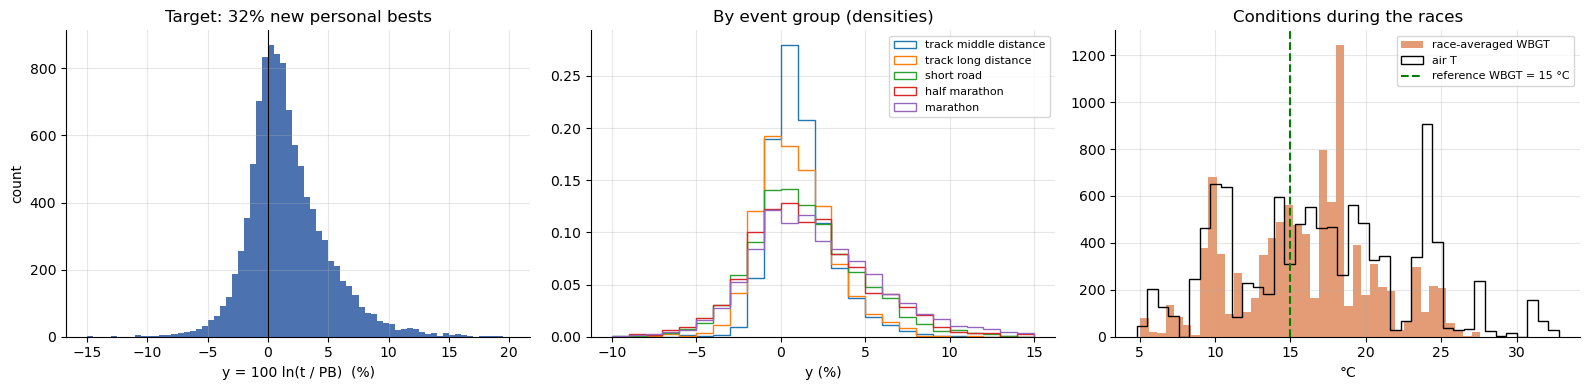

                      count     mean     std     min      5%      50%      95%      max
t_air               10398.0    17.01    5.96    4.80    8.76    16.76    27.35    32.80
hr                  10398.0    61.82   19.06   21.77   34.55    63.25    95.41   100.00
t_rosee             10398.0     8.83    5.19   -6.31   -0.88     9.56    17.10    24.46
vent_10m            10398.0     2.93    1.43    0.30    0.71     2.69     5.50     6.30
rayonnement_global  10398.0   289.06  202.30    0.00   15.30   246.90   700.50   820.89
precipitation_mm_h  10398.0     0.04    0.20    0.00    0.00     0.00     0.15     1.70
nebulosite          10398.0    53.60   41.90    0.00    0.00    60.88   100.00   100.00
pression_hpa        10398.0  1008.60   26.75  758.15  988.00  1014.43  1024.72  1033.06
altitude_m          10398.0    86.02  241.17    3.00    7.00    26.00   216.00  2582.00
t_globe             10398.0    23.14    6.79    7.40   11.99    22.96    35.14    45.72
t_nwb               10398.0    1

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df[CIBLE], bins=np.arange(-15, 20.5, 0.5), color="#4C72B0")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("y = 100 ln(t / PB)  (%)"); axes[0].set_ylabel("count")
axes[0].set_title(f"Target: {100 * (df[CIBLE] < 0).mean():.0f}% new personal bests")
for g in GROUPES:
    sous = df[df["groupe_epreuve"] == g]
    axes[1].hist(sous[CIBLE], bins=np.arange(-10, 16, 1.0), histtype="step", density=True, label=NOMS_EN[g], lw=1.5)
axes[1].legend(fontsize=8); axes[1].set_xlabel("y (%)"); axes[1].set_title("By event group (densities)")
axes[2].hist(df["wbgt"], bins=40, color="#DD8452", alpha=0.8, label="race-averaged WBGT")
axes[2].hist(df["t_air"], bins=40, histtype="step", color="k", label="air T")
axes[2].axvline(WBGT_REF, color="g", ls="--", label=f"reference WBGT = {WBGT_REF:g} °C")
axes[2].set_xlabel("°C"); axes[2].legend(fontsize=8); axes[2].set_title("Conditions during the races")
plt.tight_layout(); plt.show()

meteo = ["t_air", "hr", "t_rosee", "vent_10m", "rayonnement_global", "precipitation_mm_h", "nebulosite",
         "pression_hpa", "altitude_m", "t_globe", "t_nwb", "wbgt", "wbgt_depart", "wbgt_max_course"]
print(df[meteo].describe(percentiles=[0.05, 0.5, 0.95]).T.round(2))
print("\nRace-averaged WBGT by event group:")
print(df.groupby("groupe_epreuve")["wbgt"].describe(percentiles=[0.05, 0.5, 0.95]).reindex(GROUPES).rename(index=NOMS_EN).round(1))

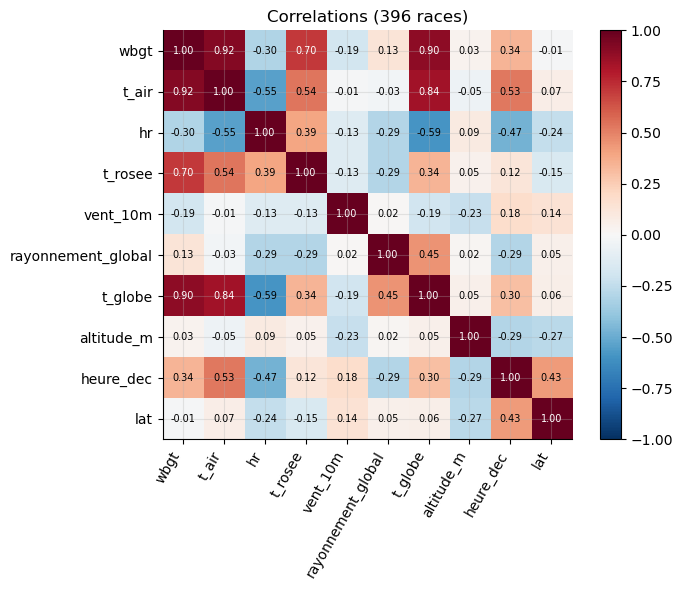

ville
Houston, TX            5.9
Pittsburgh, PA         6.8
Buenos Aires           6.9
Dessau                25.6
Guiyang               25.8
Cape Elizabeth, ME    26.5
Name: wbgt, dtype: float64


In [6]:
# Conditions are shared by all runners of a race: one row per race
par_course = df.drop_duplicates("id_course")
corr = par_course[["wbgt", "t_air", "hr", "t_rosee", "vent_10m", "rayonnement_global", "t_globe", "altitude_m",
                   "heure_dec", "lat"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im); ax.set_title(f"Correlations ({len(par_course)} races)"); plt.tight_layout(); plt.show()
print(par_course.groupby("ville")["wbgt"].mean().sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(1))

In [7]:
# Additional figures for the analysis: shape of the target, weight of the races, composition of the WBGT
print(f"y: skewness {df[CIBLE].skew():.2f}, excess kurtosis {df[CIBLE].kurt():.2f}, "
      f"{100 * (df[CIBLE] > 5).mean():.1f}% above +5%, {100 * (df[CIBLE] < -5).mean():.1f}% below -5%")
print(df.groupby("groupe_epreuve")[CIBLE].agg(mean="mean", median="median", sd="std", skewness="skew",
                                               share_pb=lambda s: (s < 0).mean(),
                                               share_above_5=lambda s: (s > 5).mean()).reindex(GROUPES)
      .rename(index=NOMS_EN).round(2))

n_par_course = df.groupby("id_course").size().sort_values(ascending=False)
print(f"\nPerformances per race: median {n_par_course.median():.0f}, max {n_par_course.max()}; "
      f"the 20 largest races account for {100 * n_par_course.head(20).sum() / len(df):.0f}% of the rows")
bandes = pd.cut(df["wbgt"], [0, 10, 18, 23, 28, 40], labels=["<10", "10-18", "18-23", "23-28", ">28"])
print(pd.DataFrame({"% performances": (100 * bandes.value_counts(normalize=True)).round(1),
                    "% races": (100 * bandes[par_course.index].value_counts(normalize=True)).round(1)}).sort_index().T)
print(pd.crosstab(bandes[par_course.index], par_course["groupe_epreuve"]).reindex(columns=GROUPES).rename(columns=NOMS_EN))

print("\nMedian conditions by group:")
print(df.groupby("groupe_epreuve")[["heure_dec", "t_air", "hr", "rayonnement_global", "vent_10m"]].median()
      .reindex(GROUPES).rename(index=NOMS_EN).round(1))
ecart_intra = df.groupby("id_course")["wbgt"].agg(lambda s: s.max() - s.min())
derive = df["wbgt_max_course"] - df["wbgt_depart"]
print(pd.DataFrame({"WBGT rise start->max (median)": derive.groupby(df["groupe_epreuve"]).median(),
                    "WBGT gap between runners of a race (median)":
                        ecart_intra.groupby(par_course.set_index("id_course")["groupe_epreuve"]).median()})
      .reindex(GROUPES).rename(index=NOMS_EN).round(2))
print(f"WBGT gap between runners of the same race: max {ecart_intra.max():.2f} °C")
print(f"Rain (> 0.1 mm/h): {(par_course['precipitation_mm_h'] > 0.1).sum()} races; "
      f"altitude > 1,000 m: {(par_course['altitude_m'] > 1000).sum()} races, "
      f"{(df['altitude_m'] > 1000).sum()} performances")

y: skewness 0.87, excess kurtosis 2.50, 13.5% above +5%, 1.2% below -5%
                       mean  median    sd  skewness  share_pb  share_above_5
groupe_epreuve                                                              
track middle distance  1.19    0.84  1.92      1.52      0.26           0.04
track long distance    0.90    0.65  2.25      0.42      0.38           0.05
short road             1.44    1.06  3.29      0.55      0.35           0.14
half marathon          1.58    1.21  3.56      0.47      0.35           0.16
marathon               2.18    1.62  3.98      0.67      0.32           0.21

Performances per race: median 14, max 293; the 20 largest races account for 32% of the rows
wbgt             <10  10-18  18-23  23-28  >28
% performances  11.9   52.6   26.4    9.0  0.0
% races          8.1   43.2   29.8   18.9  0.0
groupe_epreuve  track middle distance  track long distance  short road  half marathon  marathon
wbgt                                                       

**Analysis.**

**Shape of the target.** Of 10,398 performances, 32% are **faster than the pre-race personal best** ($y < 0$:
new personal best). The median is 1.1%, the mean 1.6%. The 5th and 95th percentiles are at −2.8% and
+7.5%. The distribution is **right-skewed** (skewness 0.87) and **heavy-tailed**
(excess kurtosis 2.5): 13.5% of performances are more than 5% above the personal best, against 1.2% more than
5% below. One can run much slower than one's best (a bad day, a tactical race, an injury, an
aging runner), but rarely much faster.

That $y$ is positive on average is expected and owes nothing to the weather: the personal best is the **minimum**
of past performances. Any given race is therefore on average slower than this minimum, and the gap is
all the larger as an athlete's performances are dispersed. This is what we observe: the mean
grows with dispersion, from 0.9-1.2% on the track to 2.2% in the marathon. The 32% of personal bests come mostly
from progressing athletes (young, old personal best or one set over few races).

**Heteroscedasticity.** Dispersion grows with distance: a standard deviation of 1.9 points in middle distance,
2.2 in track long distance, 3.3 to 3.6 on the road and 4.0 in the marathon, that is, a **variance four times larger**
in the marathon than in middle distance. Middle distance is also the group most concentrated around 0 (peak of the
density between 0 and 1%) and the most skewed (1.52): 800-1,500 m runners race often, their
personal best is recent and close to their current level, and only bad days (tactical races,
fatigue) take them away from it. Conversely, 21% of marathon runners finish more than 5% above their best. Two
consequences for what follows:

* a quadratic loss will be **dominated by errors on the road and in the marathon**; the metrics will have to
  be read by event group, and not only overall;
* heavy tails make the RMSE sensitive to a few extreme poor performances; the MAE, or a
  robust loss (Huber), is a useful complement.

The gap between sexes is small (mean 1.7% for women, 1.6% for men, standard deviations 3.5 and
3.2) and is partly explained by the distribution across events.

**Conditions.** The race-averaged WBGT ranges from 5 to 27.6 °C (median 16.4 °C): 12% of performances
below 10 °C, 53% between 10 and 18 °C, 26% between 18 and 23 °C, 9% between 23 and 28 °C, **none above
28 °C**. The ranges differ greatly by group. Track middle and long distance (summer
evening meetings, around 8 p.m.) never go below 13.5 °C, with a median of 18.3 °C in
middle distance. The half marathon and the marathon (starts at 8:30 - 10 a.m., intermediate seasons) range from
5 to 22 °C and from 6 to 26 °C, with medians of 10.3 and 14.2 °C.

**A row is not an observation independent of the weather.** The WBGT varies very little between the runners
of the same race: the gap between the first and the last listed runner never exceeds 1.2 °C (median 0.24 °C
in the marathon). This is explained by truncation: the lists only keep fast runners, who finish
a few minutes apart. Weather is therefore in practice a **race-level variable**, and the information
available on its effect rests on **396 races**, not on 10,398 rows. These races have very
unequal sizes: a median of 14 performances, a maximum of 293 (Lille 10 km), and the 20 largest races
account for 32% of the rows. Yet these large races (the Valencia, Tokyo and Berlin marathons, the
Boulogne half marathon) are run in cool conditions. Hot races are smaller: 19% of races are above
23 °C, against 9% of performances. An ordinary regression, which weights each row equally,
would therefore give much weight to a few cool marathons and little to hot races. This is what
justifies a cross-validation grouped by venue (part 2) and random race effects (part 4).

**The WBGT does not have the same composition across groups.** On the track, evening meetings combine warm
air (median 23.8 °C in middle distance), dry air (RH 52%) and a low sun (190 W/m²). Morning marathons
combine cooler air (13.2 °C), more humid air (64%) and strong radiation (430 W/m²). Two extreme
examples give the same WBGT by opposite routes: the 2026 Dessau meeting (31.5 °C, RH 38%, 200 W/m²,
WBGT 26.0 °C) and the 2026 Guiyang marathon (only 21.2 °C, but RH 73% and 540 W/m², WBGT 25.8 °C).
The WBGT is therefore not a mere temperature, and a model that only saw $T_{air}$ would rank these
two races poorly. Conversely, it is not obvious that the same WBGT has the same physiological effect whatever
its composition; part 5.4 compares the WBGT alone with the raw weather variables.

The **drift during the race** is large over long distances: from the start to the maximum, the WBGT
rises by a median of 2.4 °C in the half marathon and 3.7 °C in the marathon (zero on the track). The WBGT at the
start, the only value often published, therefore underestimates the stress endured. This justifies using the
WBGT averaged over the race duration.

**Correlations between weather variables** (one row per race). The WBGT is highly correlated with air
temperature (0.92) and with globe temperature (0.90), more moderately with dew point (0.70). It is weakly linked to
global radiation taken alone (0.13), because the hottest races are evening meetings, without sun.
Relative humidity is **anticorrelated** with temperature (−0.55): this is the diurnal cycle, in which relative
humidity drops as the air warms up. "Hot and humid" combinations are therefore rare in
the sample, and it will be **difficult to separate the effects of $T$ and $RH$** from the data alone.
This is one of the merits of the WBGT: it combines them through a physical model instead of asking the model
to learn this combination. Start time is linked to temperature (0.53) and to latitude (0.43):
it mainly encodes the **type of meeting** (track in the evening in Northern Europe, road in the morning) and will be a
confounding factor to control together with the event group. Altitude is almost uncorrelated with the WBGT
(0.03), which in principle allows its effect to be estimated separately. Pressure, almost determined by
altitude, adds nothing more.

The extreme cities illustrate the season more than the climate: Houston (January marathon and half marathon, 5.9 °C),
Buenos Aires (August half marathon, in the austral winter, 6.9 °C), Cape Elizabeth (August 10 km, 26.5 °C). With one or
two races per city, these averages do not characterize the local climate.

**Poorly represented combinations.** The track in cool conditions (below 16 °C); the half marathon in the heat (no race
above 22 °C); the very hot marathon (only 8 races above 23 °C, 102 performances); any
extreme condition (WBGT ≥ 28 °C, ACSM black flag). The crossing of event and heat is
**unfavorable**: half of the races above 23 °C are middle-distance races, where
the expected effect of heat is the weakest (§ 0.2). For long distances, where the effect is the
strongest, information on heat is scarce. The effect in the marathon in strong heat will therefore rest on few
races, and its confidence interval will be wide.

Other factors vary little. **Rain** concerns only 37 races (> 0.1 mm/h) and its effect will be
poorly estimated. **Wind** at 10 m never exceeds 6.3 m/s: no windy race. **Altitude** is
observed only on the road, in 18 races (168 performances, 1.6% of the data) and 8 venues above
1,000 m, some of which are also hot (Guiyang, Kigali, Lanzhou): its effect will be confounded with that of
heat and of the field. Any conclusion about these combinations will be extrapolation.

**Consequences for modeling.**

1. The event group (or the race duration) must enter the model, **in interaction with the WBGT**:
   the WBGT ranges, the mean level of $y$ and its dispersion all differ by group.
2. Weather is a race-level variable: the unit of information is the race, which calls for a grouped
   cross-validation and a structure of race or course effects.
3. The domain of validity of the final tool is a WBGT of 5 to 27 °C, without marked altitude or heavy rain;
   beyond it, the extrapolation will have to be flagged to the user.

### 1.3 Raw relationship between performance and WBGT

To get a first idea of the impact of the WBGT on performance, one can plot the mean of $y$
by WBGT class. This analysis is all the more interesting when the data are split by type
of event.

**Class mean and standard error.** The WBGT is cut into classes $(a, b]$ of 3 °C. In class
$b$, which contains $n_b$ performances, we compute the mean $\bar y_b$ and its **standard error**

$$\text{se}(\bar y_b) = \frac{s_b}{\sqrt{n_b}}, \qquad s_b^2 = \frac{1}{n_b - 1}\sum_{i \in b}(y_i - \bar y_b)^2 .$$

The standard error is the standard deviation of the *estimator* $\bar y_b$, that is, its variability from one sample
to another, not to be confused with the standard deviation $s_b$ of the *observations*. The divisor $n_b - 1$ makes $s_b^2$
unbiased, since the mean was estimated on the same data. By the central limit theorem,
$\bar y_b$ is approximately normal, hence the 95% confidence interval
$\bar y_b \pm 1.96\,\text{se}(\bar y_b)$, where 1.96 is the 97.5% quantile of the standard normal distribution.
By event group, only classes with at least 25 performances are shown.

These error bars rest on a hidden assumption: the formula $\text{Var}(\bar y_b) = \sigma^2/n_b$
assumes **independent** observations. Yet runners of the same race share the weather and the
course of the race; the bars are therefore too narrow (part 1.6).

**Simpson's paradox.** The mean over all events in class $b$ is a weighted mean
of the means of each event group $e$:

$$\bar y_b = \sum_e \pi_{e \mid b}\,\bar y_{e, b}, \qquad \pi_{e \mid b} = \text{share of group } e \text{ in class } b .$$

If the composition $\pi_{e \mid b}$ changes from one class to another, for example a lot of middle distance in
the hot classes and many marathons in the cool classes, the overall curve can rise,
fall or flatten even if each group has a clear relationship. An aggregate trend can thus
differ from, or even reverse, the trends of each subgroup: this is **Simpson's
paradox**. Hence the value of reading the curves by event group.

moyenne_par_classes : OK


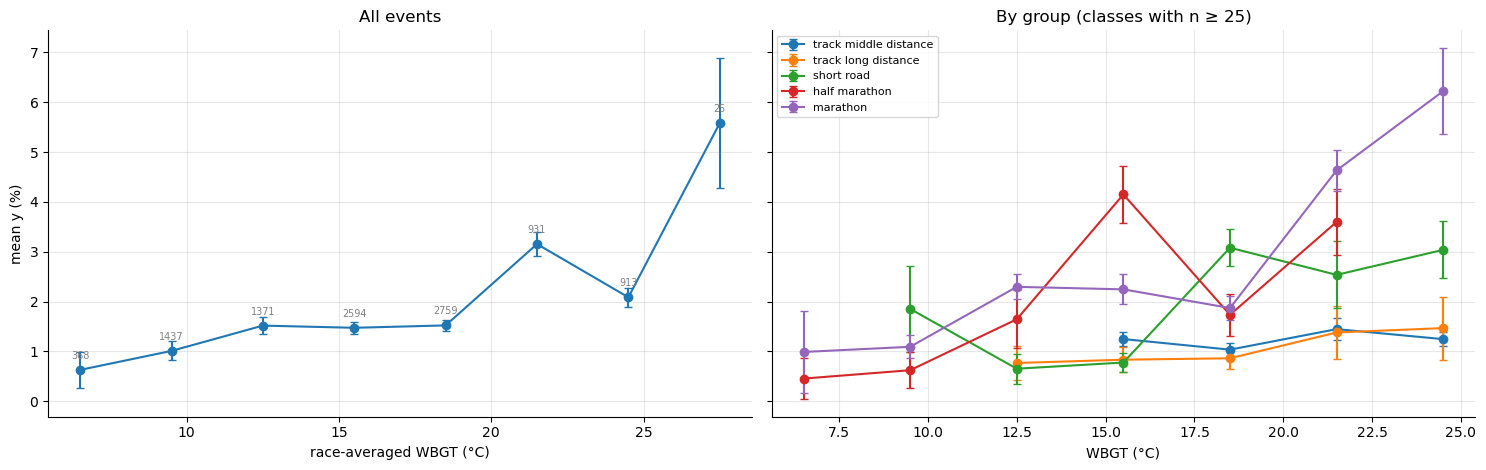

In [8]:
def moyenne_par_classes(x, y, bornes):
    '''Mean of y by class of x.

    Inputs
        x, y : array-like (n,)
        bornes : array-like (B+1,) increasing class boundaries (a, b]
    Output
        DataFrame (one row per non-empty class) with columns
        centre, n, moyenne, erreur_type
    '''
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    classes = pd.cut(x, bornes)
    tab = pd.DataFrame({"classe": classes, "y": y}).groupby("classe", observed=True)["y"]
    res = tab.agg(n="size", moyenne="mean", ecart_type="std")
    res["erreur_type"] = res["ecart_type"] / np.sqrt(res["n"])
    res["centre"] = [(iv.left + iv.right) / 2 for iv in res.index]
    return res.reset_index(drop=True)[["centre", "n", "moyenne", "erreur_type"]]

#test
_t = moyenne_par_classes([1, 2, 3, 4, 11], [0, 2, 4, 6, 100], [0, 5, 10, 15])
assert list(_t["n"]) == [4, 1] and np.allclose(_t["moyenne"], [3, 100])
assert np.isclose(_t["erreur_type"].iloc[0], np.std([0, 2, 4, 6], ddof=1) / 2) and np.isnan(_t["erreur_type"].iloc[1])
assert np.allclose(_t["centre"], [2.5, 12.5])
print("moyenne_par_classes : OK")

#display
bornes = np.arange(np.floor(df["wbgt"].min()), np.ceil(df["wbgt"].max()) + 3, 3.0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
tab = moyenne_par_classes(df["wbgt"], df[CIBLE], bornes)
axes[0].errorbar(tab["centre"], tab["moyenne"], yerr=1.96 * tab["erreur_type"], fmt="o-", capsize=3)
for _, r in tab.iterrows():
    axes[0].annotate(int(r["n"]), (r["centre"], r["moyenne"]), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=7, color="gray")
axes[0].set_xlabel("race-averaged WBGT (°C)"); axes[0].set_ylabel("mean y (%)"); axes[0].set_title("All events")
for g in GROUPES:
    sous = df[df["groupe_epreuve"] == g]
    t = moyenne_par_classes(sous["wbgt"], sous[CIBLE], bornes)
    t = t[t["n"] >= 25]
    axes[1].errorbar(t["centre"], t["moyenne"], yerr=1.96 * t["erreur_type"], fmt="o-", capsize=3, label=NOMS_EN[g])
axes[1].legend(fontsize=8); axes[1].set_xlabel("WBGT (°C)"); axes[1].set_title("By group (classes with n ≥ 25)")
plt.tight_layout(); plt.show()

**Analysis.** All events together, $\bar y$ rises from 0.6% (WBGT 5-8 °C) to 1.0% (8-11 °C), stays around 1.5%
between 11 and 20 °C, then moves to 3.2% between 20 and 23 °C. It **falls back** to 2.1% between 23 and 26 °C,
a class made up of 69% track middle distance, then reaches 5.6% above 26 °C (only 25
performances). By group, the contrast is clear:

* **marathon**: about 1% up to 11 °C, 1.9 to 2.3% between 11 and 20 °C, then 4.6% (20-23 °C) and
  6.2% (23-26 °C). The slowdown is strong and convex, consistent with Ely *et al.* (2007);
* **track middle and long distance**: almost flat (0.8 to 1.5%) over their whole range, 12-26 °C;
* **short road and half marathon**: irregular profiles, such as the half-marathon peak between 14 and 17 °C
  (4.2%). Each class gathers only a handful of races (2 to 20): these means mix the effect
  of heat and that of the venue (course, field, age of the runners).

The overall mean is misleading: its shape depends mostly on **which event group** dominates each
class (Simpson's paradox). The error bars, computed as if the performances were
independent, are too narrow (part 1.6).

### 1.4 Confounding factors

The WBGT is not randomly distributed. Hot races take place in certain countries (Southeast Asia,
West Africa, the Gulf) and in certain seasons, with different fields: level, age, share
of athletes setting a personal best. Altitude is concentrated in a few cities.

A confounding factor is only dangerous if it is **linked to the WBGT** (part 0.4). We therefore measure, at the level
of races, the correlation between the WBGT and each context variable (level, age, form, altitude,
time). Each race $c$ receives a weight $w_c = n_c/\sum_{c'} n_{c'}$ proportional to its number of
runners, to reflect its weight in the individual data. The weighted correlation reads

$$r_w = \frac{\sum_c w_c\,(u_c - \bar u_w)(v_c - \bar v_w)}{\sqrt{\sum_c w_c\,(u_c - \bar u_w)^2}\,\sqrt{\sum_c w_c\,(v_c - \bar v_w)^2}},
\qquad \bar u_w = \sum_c w_c\,u_c .$$

The direction of the bias of a simple regression of $y$ on the WBGT then follows from the omitted-variable bias
formula (part 0.4): it has the sign of $\beta_Z \times \text{Cov}(W, Z)$, where $\beta_Z$ is the effect of factor
$Z$ on $y$.

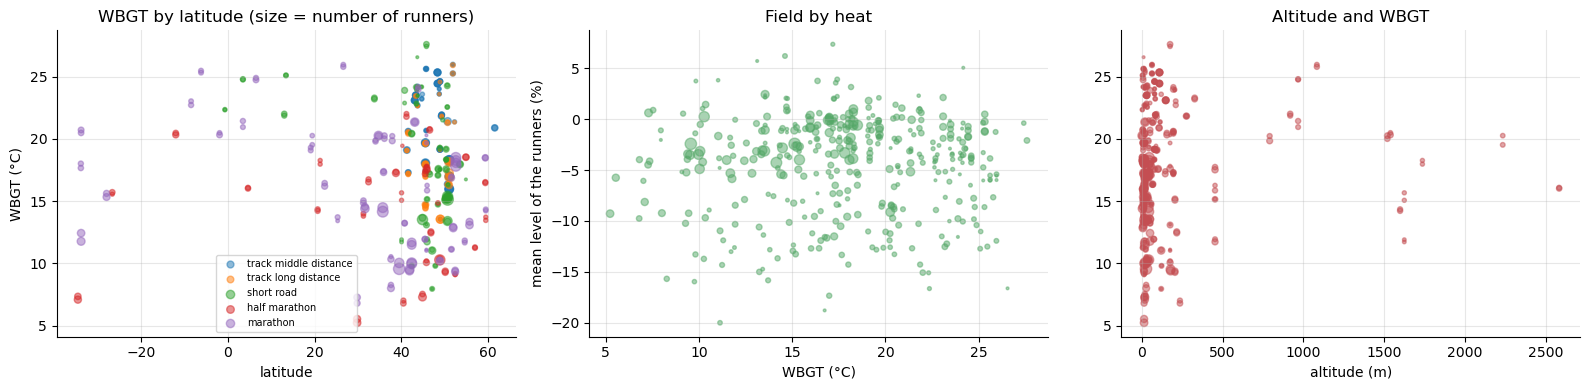

Race-level correlations (weighted by the number of runners):
  WBGT ~ level       : +0.05
  WBGT ~ age         : -0.43
  WBGT ~ form        : -0.15
  WBGT ~ altitude_m  : +0.13
  WBGT ~ hour        : +0.42


In [9]:
pc = df.groupby("id_course").agg(wbgt=("wbgt", "mean"), altitude_m=("altitude_m", "first"), lat=("lat", "first"),
                                level=("niveau_pct", "mean"), age=("age", "mean"), form=("forme_pct", "mean"),
                                group=("groupe_epreuve", "first"), hour=("heure_dec", "first"), n=(CIBLE, "size"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for g in GROUPES:
    s = pc[pc["group"] == g]
    axes[0].scatter(s["lat"], s["wbgt"], s=np.sqrt(s["n"]) * 4, alpha=0.5, label=NOMS_EN[g])
axes[0].set_xlabel("latitude"); axes[0].set_ylabel("WBGT (°C)"); axes[0].legend(fontsize=7)
axes[0].set_title("WBGT by latitude (size = number of runners)")
axes[1].scatter(pc["wbgt"], pc["level"], s=np.sqrt(pc["n"]) * 4, alpha=0.5, color="#55A868")
axes[1].set_xlabel("WBGT (°C)"); axes[1].set_ylabel("mean level of the runners (%)"); axes[1].set_title("Field by heat")
axes[2].scatter(pc["altitude_m"], pc["wbgt"], s=np.sqrt(pc["n"]) * 4, alpha=0.5, color="#C44E52")
axes[2].set_xlabel("altitude (m)"); axes[2].set_title("Altitude and WBGT")
plt.tight_layout(); plt.show()
print("Race-level correlations (weighted by the number of runners):")
w = pc["n"] / pc["n"].sum()
for v in ["level", "age", "form", "altitude_m", "hour"]:
    x = pc[["wbgt", v]].dropna(); ww = w[x.index]
    m = (x * ww.values[:, None]).sum() / ww.sum()
    cov = ((x["wbgt"] - m["wbgt"]) * (x[v] - m[v]) * ww).sum() / ww.sum()
    sd = np.sqrt(((x - m) ** 2 * ww.values[:, None]).sum() / ww.sum())
    print(f"  WBGT ~ {v:11s} : {cov / (sd['wbgt'] * sd[v]):+.2f}")

**Analysis.** At the race level, the WBGT is correlated with mean **age** (−0.43), with **start time** (+0.42), with
**form** (−0.15) and with **altitude** (+0.13), but hardly with the runners' **level** (+0.05).
The expected biases of a simple regression of $y$ on the WBGT:

* **composition of events**: hot races are mostly track meetings (38 of the 75
  races above 23 °C are middle distance), where heat matters little; cool races are
  marathons and half marathons. The pooled effect **underestimates** that of the marathon and overestimates that of
  middle distance;
* **age**: $y$ increases strongly with age (0.7% before 23, 3.5 to 3.8% after 38), because the personal best
  of an older runner is old. Hot races gather younger runners: bias **downward**;
* **altitude**: high-altitude venues (Kigali, Mexico City, Guiyang, Lanzhou) are also hot, and
  hypoxia slows runners down: bias **upward** if altitude is omitted;
* **country and course**: high WBGT in the tropics (Jakarta, Chon Buri, Lagos, Cali) and at
  European summer meetings. These races also differ in profile, field and stakes: bias of unknown
  direction, hence the course effects of part 4;
* **selection**: in strong heat, some runners give up, drop out (absent from the lists) or
  "play it safe"; the **truncation** of the lists cuts off slow performances. Bias **downward**,
  partly addressed by the margin $M$ (part 1.5).

### 1.5 Truncation: empirical demonstration

Let us return to the truncation pitfall. As an illustration, consider two male runners of the same level, whose marathon personal best is 2:30. Recall that major marathons only list men under 2:37 and women under 3:05. In cool weather, these two runners finish between 2:30 and 2:35: they are under the threshold and therefore appear in the results without any problem. With a high WBGT, the first one now runs 2:36 and remains listed. The second, more affected by the conditions, runs 2:45: he exceeds the threshold and disappears from the results. Only the runner more resistant to heat therefore appears in the data set. For athletes whose personal best is close to the threshold, that is, the slowest of the list, we only observe in strong heat those who ran well relative to their level. Let $T^{\max}_c$ denote the time of the last runner listed in race $c$. An athlete appears only if $t_i \le T^{\max}_c$, that is, if $y_i \leq m_i = 100 \ln \frac{T_c^{\max}}{t_i^{\text{PB}}}$. Their mean slowdown is then underestimated, and the effect of heat is biased toward zero.

To be convinced, let us model this illustration formally. Suppose that, in the absence of truncation, $y_i$ follows a normal distribution $\mathcal{N}(\mu_i, \sigma^2)$, that is, $y_i = \mu_i + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$. Here $\mu_i = \mathbb{E}[y_i]$ is the mean slowdown expected for athlete $i$ in the conditions of their race. An increase in WBGT increases $\mu_i$. But $y_i$ is observed only if $y_i \leq m_i$, and the quantity actually observed is $\mathbb{E}[y_i | y_i \leq m_i]$.

Let $a_i=\frac{(m_i-\mu_i)}{\sigma}$, and let $\varphi$ and $\Phi$ be the density and the cumulative distribution function of the standard normal distribution. The expectation of a normal distribution truncated from above is:

$$\mathbb{E}[y_i | y_i \leq m_i]=\mu_i-\sigma \Lambda(a_i)$$

with $\Lambda(a)=\frac{\varphi(a)}{\Phi(a)}$ (inverse Mills ratio).

Indeed,

$$\mathbb{E}[\varepsilon | \varepsilon \leq \sigma a] = \frac{1}{\Phi(a)}\int_{-\infty}^a \sigma z\varphi(z) \text{d}z=-\sigma\frac{\varphi(a)}{\Phi(a)}$$

since $z\varphi(z)=-\varphi'(z)$.

Thus, if heat increases $\mu_i$ by $\delta$, the mean actually observed only increases by
$\delta\,\frac{\partial}{\partial \mu}\mathbb{E}[y \mid y \leq m]$. To compute this derivative, note that
$a = (m - \mu)/\sigma$ depends on $\mu$, with $\frac{\partial a}{\partial \mu} = -\frac{1}{\sigma}$, and that,
since $\varphi'(a) = -a\,\varphi(a)$,

$$\Lambda'(a) = \frac{\varphi'(a)\,\Phi(a) - \varphi(a)^2}{\Phi(a)^2} = -\Lambda(a)\big(a + \Lambda(a)\big).$$

We obtain

$$\frac{\partial}{\partial \mu}\big[\mu - \sigma\Lambda(a)\big] = 1 - \sigma\,\Lambda'(a)\cdot\Big(-\frac{1}{\sigma}\Big) = 1 + \Lambda'(a)
= 1 - \Lambda(a)\big(a + \Lambda(a)\big).$$

The factor $1 - \Lambda(a)(a + \Lambda(a))$ lies between $0$ and $1$: it is also the ratio
$\text{Var}(y \mid y \leq m)/\sigma^2$, the variance of a truncated distribution being always positive and smaller than
that of the complete distribution. The estimated slope is therefore **attenuated**, all the more so as the margin $a$ is
small. When the margin is large (negligible truncation), $\Lambda(a) \to 0$, the factor tends to 1 and the
bias disappears.

As announced, the idea is therefore to keep only the athletes whose margin to the threshold is sufficient:
$m_i \geq M$ with $M$ the chosen margin. This filter bears on the athlete's **personal best** compared with the last
listed time, and not on their result of the day: it removes athletes close to the threshold, not those who ran
poorly. The cost is of course that of a smaller sample of higher level. The filter
reduces the bias without eliminating it: a slowdown larger than the margin, or a dropout, remains invisible.

Among the $4{,}425$ valid performances whose margin is below $5\%$, $63\%$ are personal bests ($y<0$), against $32\%$ in the analysis sample (margin $\geq 5 \%$). An athlete whose personal best is close to the last listed time only appears if they run fast.

To observe the impact of the choice of the minimum margin $M$, we compare the slope of $y$ as a
function of the WBGT according to the minimum truncation margin $M$ required (0, 2, 5, 8, 10 and 12%). If
truncation biases toward 0, the slope must **increase** with $M$, at the cost of a smaller sample of
higher level.

**Simple linear regression.** We assume that performance depends on the WBGT $x$ through a straight line, plus
a random error: $y = \beta_0 + \beta_1 x + \varepsilon$, where $\beta_1$ is the slope (in points of $y$ per °C), $\beta_0$ the
intercept and $\varepsilon$ a random error with zero mean and variance $\sigma^2$. By least squares, we
retain the values of $\beta_0, \beta_1$ that minimize the residual sum of squares
$S(\beta_0, \beta_1) = \sum_i (y_i - \beta_0 - \beta_1 x_i)^2$. Setting the partial derivatives to zero:

* $\partial S/\partial \beta_0 = -2\sum_i (y_i - \beta_0 - \beta_1 x_i) = 0$ gives $\hat\beta_0 = \bar y - \hat\beta_1\,\bar x$: the
  line goes through the mean point $(\bar x, \bar y)$;
* $\partial S/\partial \beta_1 = -2\sum_i x_i(y_i - \beta_0 - \beta_1 x_i) = 0$ gives, replacing $\beta_0$ by $\hat\beta_0$,
  $\sum_i (x_i - \bar x)(y_i - \bar y) = \hat\beta_1\sum_i (x_i - \bar x)^2$, hence

$$\hat\beta_1 = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2} = \frac{\widehat{\text{Cov}}(x, y)}{\widehat{\text{Var}}(x)}
= r\,\frac{s_y}{s_x},\qquad \hat\beta_0 = \bar y - \hat\beta_1\,\bar x .$$

The slope combines the strength of the linear relationship ($r$) and the ratio of the scales of the two variables.

**Precision of the slope.** Since $\sum_i(x_i-\overline{x})=0$, one can write
$\hat\beta_1 = \frac{1}{S_{xx}}\sum_i(x_i-\overline{x})\,y_i$ with $S_{xx}=\sum_i(x_i-\overline{x})^2$: it is a
linear combination of the $y_i$. With independent $\varepsilon_i$ of variance $\sigma^2$:

$$\mathbb{E}[\hat\beta_1] = \beta_1, \qquad
\text{Var}(\hat\beta_1) = \frac{\sum_i(x_i-\overline{x})^2\,\sigma^2}{S_{xx}^2} = \frac{\sigma^2}{S_{xx}}, \qquad
\widehat{\text{se}}(\hat\beta_1) = \frac{\hat\sigma}{\sqrt{S_{xx}}} .$$

The standard error decreases when there are more data, when the WBGT varies over a wider range and when the
noise $\sigma$ is smaller.

Finally, we need to estimate the unknown $\sigma^2$, on which $\text{Var}(\hat\beta_1)$ directly depends. The estimation
uses the residuals $\hat \varepsilon_i = y_i - \hat\beta_0 - \hat\beta_1 x_i$. These satisfy two
constraints: $\sum_i \hat \varepsilon_i=0$ and $\sum_i x_i \hat \varepsilon_i=0$. They vary freely
only in a space of dimension $n-2$, the number of **degrees of freedom**. One shows that
$\mathbb{E}[\sum_i \hat \varepsilon_i^2]=(n-2)\sigma^2$, hence the unbiased estimator

$$\hat \sigma^2=\frac{\sum_i \hat \varepsilon_i^2}{n-2-\nu}.$$

Dividing by $n$ would underestimate $\sigma^2$, since the line is fitted as close as possible to the points. The parameter
`ddl_perdus` $= \nu$ removes additional degrees of freedom when other parameters have been estimated;
it is $0$ in this section. For large $n$, $\hat\beta_1$ is approximately normal, hence the 95%
confidence interval $\hat\beta_1 \pm 1.96\,\widehat{\text{se}}(\hat\beta_1)$: if the experiment were repeated, 95% of the
intervals built this way would contain the true slope.

**The experiment.** For each $M$, we keep the valid performances with a margin $\geq M$ (all events,
then the marathon alone to avoid Simpson's paradox), and compute the slope, its confidence
interval and the sample size. Three points guide the reading:

* without truncation, the slope would be roughly constant: the subsample changes, not the true slope.
  With a truncation that attenuates the slope, it must increase with $M$;
* a larger $M$ reduces the bias but removes data: the confidence interval widens
  (bias-variance trade-off), and the sample changes in nature (faster athletes), which can also
  change the slope if the effect of heat depends on level;
* the subsamples are **nested** (the one for $M = 12$ is included in the one for $M = 5$): the slopes
  are highly correlated with one another, and overlapping intervals are not enough to conclude that
  two slopes are equal.

In [10]:
def pente_ols_simple(x, y, ddl_perdus=0):
    '''Simple linear regression y = a + b x.

    Inputs: x, y array-like (n,); ddl_perdus: int, degrees of freedom removed in addition to the 2 parameters
    Output: dict with 'pente', 'ordonnee', 'erreur_type_pente'
    '''
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    xc, yc = x - x.mean(), y - y.mean()
    sxx = np.sum(xc ** 2)
    b = np.sum(xc * yc) / sxx
    a = y.mean() - b * x.mean()
    residus = y - a - b * x
    sigma2 = np.sum(residus ** 2) / (len(x) - 2 - ddl_perdus)
    return {"pente": b, "ordonnee": a, "erreur_type_pente": np.sqrt(sigma2 / sxx)}


def pentes_selon_marge(df, marges, groupe=None, x="wbgt"):
    '''Slope of y against x for each minimum margin M.

    Output: DataFrame [marge, n, pente, ic_bas, ic_haut]
    '''
    lignes = []
    for M in marges:
        sel = df[df["marge_troncature_pct"] >= M]
        if groupe is not None:
            sel = sel[sel["groupe_epreuve"] == groupe]
        r = pente_ols_simple(sel[x], sel[CIBLE])
        lignes.append({"marge": M, "n": len(sel), "pente": r["pente"],
                       "ic_bas": r["pente"] - 1.96 * r["erreur_type_pente"],
                       "ic_haut": r["pente"] + 1.96 * r["erreur_type_pente"]})
    return pd.DataFrame(lignes)

In [11]:
#test
_x = np.array([0., 1, 2, 3, 4]); _y = 2 + 0.5 * _x + np.array([0.1, -0.1, 0, 0.1, -0.1])
_r = pente_ols_simple(_x, _y)
_p = np.polyfit(_x, _y, 1)
assert np.isclose(_r["pente"], _p[0]) and np.isclose(_r["ordonnee"], _p[1])
_res = _y - np.polyval(_p, _x)
assert np.isclose(_r["erreur_type_pente"], np.sqrt(np.sum(_res ** 2) / 3 / 10))
_d = pd.DataFrame({"wbgt": [10., 20, 30, 10, 20, 30], CIBLE: [0., 1, 2, 0, 2, 4], "marge_troncature_pct": [1., 1, 1, 9, 9, 9],
                   "groupe_epreuve": ["marathon"] * 6})
_t = pentes_selon_marge(_d, [0, 5])
assert list(_t["n"]) == [6, 3] and np.isclose(_t["pente"].iloc[1], 0.2) and np.isclose(_t["pente"].iloc[0], 0.15)
print("pente_ols_simple, pentes_selon_marge: OK")

pente_ols_simple, pentes_selon_marge: OK


All events 
  marge     n  pente  ic_bas  ic_haut
     0 14221 0.1127  0.1012   0.1243
     2 13104 0.1045  0.0925   0.1165
     5 10398 0.0952  0.0813   0.1091
     8  7637 0.0959  0.0788   0.1129
    10  5961 0.0992  0.0796   0.1188
    12  4514 0.1103  0.0872   0.1334
Marathon 
  marge    n  pente  ic_bas  ic_haut
     0 5382 0.2219  0.1979   0.2460
     2 4919 0.2295  0.2046   0.2544
     5 3857 0.2276  0.1994   0.2559
     8 2899 0.2361  0.2030   0.2692
    10 2392 0.2396  0.2031   0.2762
    12 1974 0.2571  0.2169   0.2974


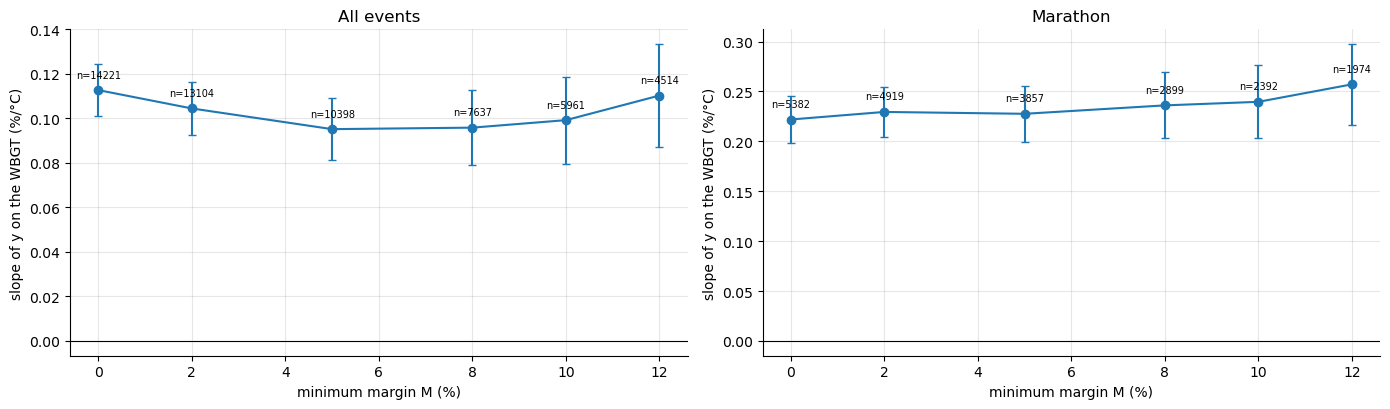

In [12]:
MARGES = [0, 2, 5, 8, 10, 12]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, g in zip(axes, [None, "marathon"]):
    t = pentes_selon_marge(df_complet, MARGES, groupe=g)
    ax.errorbar(t["marge"], t["pente"], yerr=[t["pente"] - t["ic_bas"], t["ic_haut"] - t["pente"]], fmt="o-", capsize=3)
    for _, r in t.iterrows():
        ax.annotate(f"n={int(r['n'])}", (r["marge"], r["pente"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7)
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("minimum margin M (%)"); ax.set_ylabel("slope of y on the WBGT (%/°C)")
    ax.set_title("All events" if g is None else "Marathon")
    print(("All events" if g is None else "Marathon"), "\n", t.round(4).to_string(index=False))
plt.tight_layout(); plt.show()

**Analysis.** The overall slope moves little with the margin: 0.113 %/°C without filtering ($M = 0$, 14,221 performances),
0.095 for $M = 5$, 0.110 for $M = 12$ (4,514 performances). In the **marathon**, it increases
slightly with $M$: 0.222 → 0.228 → 0.257 %/°C. This is the expected direction: when the lists are
truncated, the slow performances of hot days are missing, which **attenuates** the slope; requiring a
larger margin removes the races where this attenuation is possible. The magnitude remains modest (+15%
between $M = 0$ and $M = 12$, within the margins of uncertainty), whereas the sample is divided by
2.7. $M = 5$ is a reasonable compromise, which we will revisit in part 11 with the final model.

Two caveats. The overall slope mixes events (part 1.4). The confidence intervals shown assume independent
performances: with a race ICC of 0.18 (part 1.6), they are about twice
too narrow.

### 1.6 Dependence structure: race, meeting, course, venue

Runners of the same race share the weather, the course of the race (pacemakers, tactics) and the
field; the editions of the same course share its profile. We measure here the share of the variance
of $y$ common to runners of the same **race**, the same **meeting**, the same **course** (all
editions) or the same **venue**, through the **intraclass correlation** (ICC). A high ICC has two
consequences: whole groups will have to be kept on the same side of the validation (part 2), and a
hierarchical model will be needed (part 4).

**Random group effect model.** We assume that the observations are divided into $G$ groups
(races, venues...) and that

$$
y_{gj}=\mu+u_g+\varepsilon_{gj}, \quad
u_g \sim \mathcal{N}(0,\tau^2), \quad
\varepsilon_{gj} \sim \mathcal{N}(0,\sigma^2),
$$

all independent. $u_g$ is a group effect shared by all the observations of group $g$ (same
weather, same race dynamics, same course), $\varepsilon_{gj}$ is the part specific to individual $j$. In
this case,

$$
\text{Var}(y_{gj})=\tau^2+\sigma^2, \quad
\text{Cov}(y_{gj},y_{gj'})= \tau^2 \ (j \ne j'), \quad
\text{ICC}=\text{Corr}(y_{gj},y_{gj'})=\frac{\tau^2}{\tau^2+\sigma^2}.
$$

The covariance comes from the fact that two runners of the same group share the same $u_g$:
$\text{Cov}(\mu + u_g + \varepsilon_{gj}, \mu + u_g + \varepsilon_{gj'}) = \text{Var}(u_g) = \tau^2$.
The ICC has two equivalent readings: the share of total variance due to the groups, and the correlation
between two observations of the same group. For $\text{ICC}=0$, the groups play no role; if
$\text{ICC}=1$, all the observations of a group are identical.

**ANOVA estimator, unbalanced groups.** With $N$ observations, $n_g$ observations in group $g$,
$\bar y_g$ the group mean and $\bar y$ the overall mean, total variation decomposes into a
between-group part and a within-group part:

$$
\underbrace{\sum_g\sum_j(y_{gj}-\bar y)^2}_{\text{SST}}=\underbrace{\sum_g n_g(\bar y_g-\bar y)^2}_{\text{SSB (between groups)}}
+\underbrace{\sum_g\sum_j(y_{gj}-\bar y_g)^2}_{\text{SSW (within groups)}} .
$$

The mean squares are defined by dividing each sum by its number of degrees of freedom:

$$\text{MSB} = \frac{\sum_g n_g(\bar y_g - \bar y)^2}{G-1},\qquad
  \text{MSW} = \frac{\sum_g\sum_j (y_{gj} - \bar y_g)^2}{N-G},\qquad
  n_0 = \frac{N - \sum_g n_g^2/N}{G-1}.$$

Under the model above, one shows that

$$
\mathbb{E}[\text{MSW}]=\sigma^2, \quad
\mathbb{E}[\text{MSB}]=\sigma^2+n_0 \tau^2.
$$

The intuition is the following. Within a group, $u_g$ is common to all and disappears from the deviations
$y_{gj} - \bar y_g$: these only contain individual noise, hence $\mathbb{E}[\text{MSW}] = \sigma^2$
($N - G$ degrees of freedom, since $G$ means were estimated). Group means, on the other hand, vary for
two reasons: the true differences between groups ($u_g$, of variance $\tau^2$) and sampling
noise ($\sigma^2/n_g$). Expanding $\mathbb{E}[\text{SSB}]$ gives
$(G - 1)\sigma^2 + \big(N - \sum_g n_g^2/N\big)\tau^2$, hence the factor $n_0$. If all groups have the
same size $n$, $n_0 = n$; if they are unbalanced, $n_0$ is smaller than the mean size $N/G$, because
large groups bring less information on $\tau^2$ than their size suggests. We deduce
the method-of-moments estimator, which equates each mean square with its expectation:

$$
\hat \sigma^2 = \text{MSW}, \quad
\hat \tau^2 = \frac{\text{MSB}-\text{MSW}}{n_0}, \quad
\widehat{\text{ICC}} = \frac{\hat \tau^2}{\hat \tau^2+\hat \sigma^2} = \frac{\text{MSB} - \text{MSW}}{\text{MSB} + (n_0 - 1)\,\text{MSW}}.$$

When the true ICC is close to 0, MSB can be smaller than MSW by chance, and the estimator is
slightly **negative**. We do not truncate it at 0, which would introduce an upward bias.

**Design effect and effective sample size.** For the mean of $n$ observations of the same group,
pairwise correlated with correlation $\rho = \text{ICC}$ and with variance $\sigma_t^2 = \tau^2 + \sigma^2$,

$$\text{Var}(\bar y) = \frac{1}{n^2}\Big[n\,\sigma_t^2 + n(n-1)\,\rho\,\sigma_t^2\Big] = \frac{\sigma_t^2}{n}\,\big[1 + (n - 1)\rho\big].$$

The factor $\text{deff} = 1 + (\bar n - 1)\rho$, called the **design effect** (Kish), measures by how much the
correlation multiplies the variance compared with independent observations. The **effective sample
size** $N/\text{deff}$ is the number of independent observations that would bring the same
information.

In [13]:
def icc_anova(y, groupes):
    '''Intraclass correlation (ANOVA estimator, unbalanced groups).

    Inputs: y array-like (N,); groupes array-like (N,) of identifiers
    Output: float
    '''
    d = pd.DataFrame({"y": np.asarray(y, dtype=float), "g": np.asarray(groupes)})
    N, moy = len(d), d["y"].mean()
    stats = d.groupby("g")["y"].agg(["mean", "size"])
    k = len(stats)
    msb = np.sum(stats["size"] * (stats["mean"] - moy) ** 2) / (k - 1)
    msw = np.sum((d["y"] - d.groupby("g")["y"].transform("mean")) ** 2) / (N - k)
    n0 = (N - np.sum(stats["size"] ** 2) / N) / (k - 1)
    return float((msb - msw) / (msb + (n0 - 1) * msw))

In [14]:
#test
_rng = np.random.default_rng(1)
_g = np.repeat(np.arange(400), _rng.integers(2, 6, 400))
_u = _rng.normal(0, 1.0, 400)[_g]; _e = _rng.normal(0, 1.0, len(_g))
assert abs(icc_anova(_u + _e, _g) - 0.5) < 0.08
assert abs(icc_anova(_e, _g)) < 0.08
print("icc_anova: OK")

icc_anova: OK


In [15]:
for nom, col in [("race", "id_course"), ("meeting", "id_meeting"), ("course", "id_parcours"), ("venue", "id_lieu")]:
    print(f"ICC {nom:9s}: {icc_anova(df[CIBLE], df[col]):.3f}   ({df[col].nunique()} groups)")
print(df.groupby(["groupe_epreuve", "sexe"])[CIBLE].agg(["size", "mean", "std"]).rename(index=NOMS_EN).round(2))

ICC race     : 0.183   (396 groups)
ICC meeting  : 0.170   (135 groups)
ICC course   : 0.174   (172 groups)
ICC venue    : 0.161   (100 groups)
                            size  mean   std
groupe_epreuve        sexe                  
track middle distance F      981  1.22  2.03
                      M     1517  1.17  1.85
track long distance   F      315  1.20  2.42
                      M      704  0.76  2.16
marathon              F     1575  2.18  4.18
                      M     2282  2.17  3.84
short road            F      438  1.76  3.53
                      M     1452  1.34  3.20
half marathon         F      392  1.58  3.90
                      M      742  1.58  3.37


**Analysis.** About **17% of the variance of $y$** is common to runners of the same race (ICC 0.18), the same
meeting (0.17), the same course (0.17) or the same venue (0.16). These values are almost equal:
most of what is shared is already shared **at the venue level** (weather, course, field, conditions
of the day), and almost nothing is gained by going down to the race.

Consequences: $(i)$ the design effect $1 + (\bar n - 1)\,\text{ICC} \approx 1 + 25 \times 0.18 \approx 5.5$
brings the actual information of 10,398 performances down to **about 1,900 independent equivalents**, and
only 396 distinct weather situations; $(ii)$ random validation folds would let
venue effects leak (part 2); $(iii)$ confidence intervals must resample
**venues**, not rows; $(iv)$ a model with a random race effect is natural (part 4).

## Part 2 — Validation protocol

The final tool will be used to estimate the effect of weather conditions in a city and a race that
have never been observed. The evaluation protocol must reproduce this situation: a model is only
judged on data absent from its training, and these data must be as independent of it
as those of a real use will be.

### 2.1 Sources of information leakage and protocol retained

The error measured on a validation set is an unbiased estimate of the generalization risk
$\mathcal{R}(f) = \mathbb{E}[\ell(f(x), y)]$ only if the training and validation sets are
**independent**. When information shared between the two sets is available at evaluation time
but will not be in real use, the measured error is too optimistic: this is called **information
leakage** (*data leakage*). Part 1.6 showed that 16 to 18% of the variance of $y$ is common
to runners of the same race, the same course or the same venue. Three dependence structures are
at stake.

1. **Weather and random events are shared within a race and a meeting.** All runners of a
   race experience (almost) the same WBGT and the same race dynamics: pacemakers, tactics, headwind in
   the home straight. A random split of the rows places the same race on both sides; the
   model can then associate the day's random events with a WBGT value and be rewarded for this
   overfitting.

2. **The speed of a course is shared between its editions.** Boston remains hilly from one year
   to the next and Valencia remains fast. If the 2023 edition is in training and the 2026 edition in
   validation, the model can recognize the course (same altitude, same typical conditions) and
   benefit from it without having learned anything about the effect of weather.

3. **The athletes.** The source data are anonymous: the same athlete can appear several times,
   but it is rare, and their level is already absorbed by the personal best.

**Grouping by venue.** We group the data at the most encompassing level, the **venue** (the
city): all the races, editions and events of the same city are placed on the same side of each
split. This cautious choice costs almost nothing, since the venue ICC (0.16) is close to that of the
race (0.18): most of what is shared is already shared at the venue level.

**Test set.** About 20% of the venues are set aside. Since hot conditions are rare, the
draw is **stratified**: venues are divided into three climate terciles according to their mean WBGT
(cuts at the 1/3 and 2/3 quantiles), then $\lceil 0.2\, n_{\text{tercile}} \rceil$ venues are drawn at
random in each tercile. The test set thus contains hot, cool and intermediate venues. It is
used **only once**, for the final evaluation (part 7): choosing a model or a
hyperparameter on the test set would make its error optimistic.

**Grouped cross-validation.** On the remaining venues, models and their hyperparameters are
chosen by cross-validation with $K = 5$ folds. For each fold $k$, a model is trained on the other
four ($\mathcal{A}_k$) then evaluated on fold $k$ ($\mathcal{V}_k$), and the risk is estimated by the
mean of the $K$ errors. Each fold is made of whole venues. To balance the folds in number of
performances, venues are assigned greedily: they are sorted by decreasing size (venues
of the same size in a random but reproducible order), then each is placed in the
least filled fold.

In [16]:
def separer_par_lieux(df, frac_test=0.2, seed=SEED):
    '''Test venues drawn at random within each tercile of mean WBGT. Output: (df_train, df_test).'''
    rng = np.random.default_rng(seed)
    climat = df.groupby("id_lieu")["wbgt"].mean()
    tiers = pd.qcut(climat, 3, labels=False)
    test = []
    for t in sorted(tiers.unique()):
        lieux = np.array(sorted(tiers.index[tiers == t]))
        k = int(np.ceil(frac_test * len(lieux)))
        test += list(rng.permutation(lieux)[:k])
    masque = df["id_lieu"].isin(test).to_numpy()
    return df[~masque].copy().reset_index(drop=True), df[masque].copy().reset_index(drop=True)


def plis_par_groupes(groupes, K=5, seed=SEED):
    '''Cross-validation with balanced groups. Output: list of K tuples (idx_train, idx_val).'''
    groupes = np.asarray(groupes)
    uniques, effectifs = np.unique(groupes, return_counts=True)
    ordre = np.random.default_rng(seed).permutation(len(uniques))
    ordre = ordre[np.argsort(-effectifs[ordre], kind="stable")]
    charge, affect = np.zeros(K), {}
    for i in ordre:
        k = int(np.argmin(charge))
        affect[uniques[i]] = k
        charge[k] += effectifs[i]
    pli = np.array([affect[g] for g in groupes])
    return [(np.where(pli != k)[0], np.where(pli == k)[0]) for k in range(K)]


def identifiants_communs(df, idx_a, idx_b, colonnes=("id_lieu", "id_parcours", "id_meeting", "id_course")):
    '''Number of identifiers present both in df.iloc[idx_a] and in df.iloc[idx_b], by column.'''
    return {col: len(set(df[col].iloc[idx_a]) & set(df[col].iloc[idx_b])) for col in colonnes}

In [17]:
#test
df_train, df_test = separer_par_lieux(df)
assert len(df_train) + len(df_test) == len(df) and not set(df_train["id_lieu"]) & set(df_test["id_lieu"])
assert 0.1 < df_test["id_lieu"].nunique() / df["id_lieu"].nunique() < 0.3
PLIS = plis_par_groupes(df_train["id_lieu"], K=5)
assert len(PLIS) == 5
tailles = [len(v) for _, v in PLIS]
for itr, iva in PLIS:
    assert len(np.intersect1d(itr, iva)) == 0 and len(itr) + len(iva) == len(df_train)
    assert all(v == 0 for v in identifiants_communs(df_train, itr, iva).values())
_toy = plis_par_groupes(np.array(["a", "a", "a", "b", "c", "c"]), K=2)
assert sorted(len(v) for _, v in _toy) == [3, 3]
print("Validation folds (performances):", tailles, "| test:", len(df_test), "performances,",
      df_test["id_lieu"].nunique(), "venues:", ", ".join(sorted(df_test["ville"].unique())))

Validation folds (performances): [1608, 1609, 1608, 1611, 1607] | test: 2355 performances, 21 venues: Annecy, Auxerre, Bordeaux, Boulogne Sur Mer, Brest, Burnaby, Cape Elizabeth, ME, Cape Town, Chicago, IL, Cholet, Chon Buri, Guadalajara, Jakarta, Larne, Liège, Ordizia, Portland, OR, San Juan de los Lagos, Smederevo, Tampere, Valencia


In [18]:
# For comparison: a random split of the rows massively shares the identifiers
_perm = np.random.default_rng(SEED).permutation(len(df_train))
print("Random 80/20 split:", identifiants_communs(df_train, _perm[:int(.8 * len(_perm))], _perm[int(.8 * len(_perm)):]))

Random 80/20 split: {'id_lieu': 77, 'id_parcours': 119, 'id_meeting': 105, 'id_course': 247}


**Analysis.** The test set contains **21 venues and 2,355 performances** (23% of the data). It covers
the range of climates well, with a mean WBGT per venue from 9.5 °C (Chicago marathon) to 26.5 °C
(Cape Elizabeth): cool venues (Chicago, Valencia, Auxerre, Cholet), intermediate ones (Annecy, Brest, Cape
Town) and hot ones (Ordizia, Smederevo, Chon Buri, Jakarta). Two venues weigh heavily in it: Portland (686
track performances) and Valencia (415 marathon performances). The 79 remaining
venues (8,043 performances) form five balanced folds of 1,607 to 1,611 performances, that is, 14 to 17
venues each. No venue, course, meeting or race identifier is shared between
training and validation.

By comparison, a random 80/20 split of the rows shares **77 of the 79 venues, 119 courses,
105 meetings and 247 races** between training and validation: almost all the dependence
structures identified above would be present on both sides. Part 5.4 measures the cost of
this leakage on the estimate of the error.

### 2.2 Evaluation metrics

For $n$ observations $y_i$ and their predictions $\hat y_i$, we use three metrics:

$$\text{RMSE} = \sqrt{\tfrac1n\textstyle\sum_i (y_i - \hat y_i)^2},\qquad
  \text{MAE} = \tfrac1n\textstyle\sum_i |y_i - \hat y_i|,\qquad
  R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

**The RMSE** is expressed in the unit of $y$ (percentage points) and strongly penalizes large
errors. It corresponds to the squared loss, whose minimizer is the conditional expectation
$\mathbb{E}[y \mid x]$: it is the main metric, consistent with the loss used by the models.

**The MAE** corresponds to the absolute loss, whose minimizer is the conditional median. It is more
robust to extreme values. Part 1.2 showed that $y$ is skewed and heavy-tailed, and that
its variance is four times larger in the marathon than in middle distance: the RMSE will therefore be dominated by
a few poor performances and by road events, and the MAE is a useful complement.

**The $R^2$** measures the share of the variance of $y$ explained by the model, by comparison with the
constant prediction $\bar y$ computed **on the evaluated sample**. Out of sample, it can be
negative: the model then does worse than this mean. Even the constant model obtains a slightly
negative validation $R^2$, since it predicts the training mean and not that of the evaluated fold.

The expected $R^2$ values are modest. Most of the variance of $y$ comes from variability from one race
to another and from one runner to another (form on the day, tactics, age of the personal best), which weather
only partly explains. For the final tool, the quality of the **estimate of the effect** of heat,
that is, of the degradation curve, will matter as much as the accuracy of individual
predictions.

In [19]:
def rmse(y, y_pred):
    '''Root mean squared error. Inputs array-like (n,). Output float.'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))


def mae(y, y_pred):
    '''Mean absolute error.'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs(y - y_pred)))


def r2(y, y_pred):
    '''Out-of-sample coefficient of determination (reference: mean of y).'''
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    return float(1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2))

In [20]:
#test
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
_a = np.random.default_rng(2).normal(size=50); _b = _a + np.random.default_rng(3).normal(size=50)
assert np.isclose(rmse(_a, _b), np.sqrt(mean_squared_error(_a, _b)))
assert np.isclose(mae(_a, _b), mean_absolute_error(_a, _b)) and np.isclose(r2(_a, _b), r2_score(_a, _b))
assert np.isclose(r2(_a, np.full(50, _a.mean())), 0.0)
print("metrics: OK")

metrics: OK


### 2.3 Derived variables and Mundlak term

Three variables are added. They are computed within a row or within a **course**; since a
course belongs to a single venue, their computation introduces no leakage between the folds.

* **Expected race duration**: `log_duree` $= \ln(\texttt{duree\_ref\_min})$, where the duration is that of the
  personal best. The effect of heat grows with the duration of the effort (part 0.2); the logarithm
  puts an 800 m (about 2 minutes) and a marathon (about 150 minutes) on the same scale.

* **Useful altitude**: `alt_km` $= \max(0,\ \text{altitude} - 500)/1000$, the altitude above 500 m, in
  kilometers. This "hinge" function expresses the physiological assumption of a negligible effect of hypoxia
  below 500 m and a linear one above.

* **Mundlak term**: `wbgt_moy_parcours` $= \bar W_g$, the mean WBGT of course $g$ (city × event,
  all editions and all runners together), and `wbgt_ecart_parcours` $= W_{gj} - \bar W_g$. Any WBGT
  thus decomposes into

  $$W_{gj} = \underbrace{\bar W_g}_{\text{between courses}} + \underbrace{(W_{gj} - \bar W_g)}_{\text{within course}}.$$

  The **within-course** component varies from one edition to another, or between fast and slow runners of the same
  race who do not run during the same hours. It compares a course with itself and remains sheltered from
  differences between courses. The **between-course** component, on the contrary, compares
  different courses and remains exposed to the confounding factors of part 1.4 (country, field, profile).
  Introducing $\bar W_g$ as a regressor allows the WBGT coefficient to capture only the
  within-course effect (Mundlak, 1978; part 4.2).

In [21]:
def ajouter_variables(df):
    '''Adds log_duree, alt_km, wbgt_moy_parcours, wbgt_ecart_parcours. Returns a copy.'''
    out = df.copy()
    out["log_duree"] = np.log(out["duree_ref_min"])
    out["alt_km"] = np.maximum(0.0, out["altitude_m"] - 500.0) / 1000.0
    out["wbgt_moy_parcours"] = out.groupby("id_parcours")["wbgt"].transform("mean")
    out["wbgt_ecart_parcours"] = out["wbgt"] - out["wbgt_moy_parcours"]
    return out

In [22]:
#test
_tmp = df.head(50).copy(); _ = ajouter_variables(_tmp)
assert "log_duree" not in _tmp.columns, "ajouter_variables must not modify its input"
df = ajouter_variables(df)
df_train, df_test = separer_par_lieux(df)
PLIS = plis_par_groupes(df_train["id_lieu"], K=5)
assert np.allclose(df.groupby("id_parcours")["wbgt_ecart_parcours"].mean(), 0, atol=1e-9)
assert (df["alt_km"] >= 0).all() and np.isclose(df.loc[df["altitude_m"] <= 500, "alt_km"], 0).all()
print(f"Standard deviation of the WBGT: total {df['wbgt'].std():.2f} °C, within a course {df['wbgt_ecart_parcours'].std():.2f} °C")
print(f"Rows above 1,000 m: {(df['altitude_m'] > 1000).sum()} ({df.loc[df['altitude_m'] > 1000, 'ville'].nunique()} venues)")

Standard deviation of the WBGT: total 4.52 °C, within a course 1.04 °C
Rows above 1,000 m: 168 (8 venues)


In [23]:
# Lists of the variables used
NUM_CONTEXTE = ["niveau_pct", "age", "forme_pct", "log_duree", "alt_km", "heure_dec"]
CAT_CONTEXTE = ["groupe_epreuve", "sexe"]
NUM_METEO = ["wbgt", "vent_10m", "precipitation_mm_h"]     # the WBGT summarizes T, RH, wind and radiation
NUM_MUNDLAK = ["wbgt_moy_parcours"]
print(df[NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK].isna().mean().round(3).to_dict())

{'niveau_pct': 0.0, 'age': 0.092, 'forme_pct': 0.451, 'log_duree': 0.0, 'alt_km': 0.0, 'heure_dec': 0.0, 'wbgt': 0.0, 'vent_10m': 0.0, 'precipitation_mm_h': 0.0, 'wbgt_moy_parcours': 0.0}


**Analysis.** The standard deviation of the WBGT is 4.52 °C over the whole data set, but **only 1.04 °C
within a course**: within-course variation represents only about 5% of the
variance of the WBGT ($1.04^2/4.52^2 \approx 0.05$). Most of the information on heat
therefore comes from comparisons between venues, exposed to confounding factors. An estimate based
on within-course variation alone will be better protected from these biases, but will rest on little
variation and will have to be extrapolated to describe a 10 °C difference.

Altitude above 1,000 m concerns only 168 performances, in 8 venues: its effect will be estimated
with great uncertainty. Missing values are limited to age (9.2%) and form
(45.1%, for lack of a pre-race season's best), which justifies imputation
together with a missing-value indicator.

### 2.4 Preprocessing learned on the training set only

The models operate on a numerical matrix $X \in \mathbb{R}^{n \times p}$. All the parameters of the
preprocessing (medians, means, standard deviations, categories) are **learned on $\mathcal{A}_k$
only**, then applied as such to $\mathcal{V}_k$ or to the test set. Estimating them on all the
data would be a leak: the preprocessing would "know" the validation venues.

**Numerical variables.** Missing values are imputed by the **training median**,
robust to extreme values. When a column has missing values in training, an
indicator `col__manquant` is added, because the absence of a value can be informative: an athlete
without a season's best has often not run the event earlier in
the year. The variables are finally **standardized**, $z = (x - \mu)/s$ (with $s = 1$ if $s = 0$). Standardization
is necessary for the ridge penalty, which depends on the scale of the coefficients, and eases the
optimization of neural networks; it is useless for trees, which are invariant under monotone
transformations.

**Categorical variables.** Each category seen in training receives an indicator column
(*one-hot* encoding); an unknown category produces a row of zeros. If all categories are
encoded and the model has an intercept, the sum of the indicators equals the
constant column: $X$ is no longer of full rank and $X^\top X$ is not invertible. The option
`ref_premiere=True` therefore drops the first category, called the reference category, against which the other coefficients
measure the difference (part 4).

Applied to the context variables, this preprocessing produces 15 columns: 6 numerical variables, 2
missing-value indicators (age and form), 5 event groups and 2 sexes.

In [24]:
class Preprocesseur:
    '''Imputation + missing-value indicators + standardization + one-hot, learned on the training set.

    numeriques: list of numerical columns; categorielles: list of categorical columns
    standardiser: bool (False for trees); ref_premiere: bool, drop the first category
    '''

    def __init__(self, numeriques, categorielles=(), standardiser=True, ref_premiere=False):
        self.numeriques, self.categorielles, self.standardiser = list(numeriques), list(categorielles), standardiser
        self.ref_premiere = ref_premiere

    def fit(self, df):
        '''Learns the parameters on df. Returns self.'''
        self.mediane_, self.manq_, self.mu_, self.s_, self.modalites_ = {}, {}, {}, {}, {}
        self.noms_ = []
        for col in self.numeriques:
            x = df[col].astype(float)
            self.mediane_[col] = float(x.median()) if x.notna().any() else 0.0
            self.manq_[col] = bool(x.isna().any())
            x = x.fillna(self.mediane_[col])
            self.mu_[col] = float(x.mean()) if self.standardiser else 0.0
            s = float(x.std(ddof=0)) if self.standardiser else 1.0
            self.s_[col] = s if s > 0 else 1.0
            self.noms_.append(col)
            if self.manq_[col]:
                self.noms_.append(col + "__manquant")
        for col in self.categorielles:
            mods = sorted(df[col].astype(str).unique())
            self.modalites_[col] = mods[1:] if self.ref_premiere else mods
            self.noms_ += [f"{col}={m}" for m in self.modalites_[col]]
        return self

    def transform(self, df):
        '''Applies the transformation. Output: np.ndarray (n, len(noms_)) float64.'''
        blocs = []
        for col in self.numeriques:
            x = df[col].astype(float)
            blocs.append(((x.fillna(self.mediane_[col]) - self.mu_[col]) / self.s_[col]).to_numpy()[:, None])
            if self.manq_[col]:
                blocs.append(x.isna().to_numpy(dtype=float)[:, None])
        for col in self.categorielles:
            v = df[col].astype(str).to_numpy()
            if self.modalites_[col]:
                blocs.append(np.stack([(v == m).astype(float) for m in self.modalites_[col]], axis=1))
        return np.hstack(blocs) if blocs else np.zeros((len(df), 0))

    def fit_transform(self, df):
        return self.fit(df).transform(df)

In [25]:
#test
_tr = pd.DataFrame({"a": [1.0, np.nan, 3.0, 5.0], "b": [2.0, 2.0, 2.0, 2.0], "c": ["x", "y", "x", "x"]})
_te = pd.DataFrame({"a": [np.nan, 10.0], "b": [3.0, np.nan], "c": ["z", "y"]})
_p = Preprocesseur(["a", "b"], ["c"]).fit(_tr)
assert _p.noms_ == ["a", "a__manquant", "b", "c=x", "c=y"]
_X = _p.transform(_tr)
assert _X.shape == (4, 5) and np.allclose(_X[:, 0].mean(), 0) and np.allclose(_X[:, 0].std(), 1)
assert np.allclose(_X[:, 1], [0, 1, 0, 0]) and np.allclose(_X[:, 2], 0)   # zero standard deviation -> s = 1
_Xt = _p.transform(_te)
assert _Xt.shape == (2, 5) and not np.isnan(_Xt).any()
assert np.allclose(_Xt[0, 3:], 0) and np.allclose(_Xt[1, 3:], [0, 1])     # unknown category -> zeros
assert np.isclose(_Xt[0, 0], _X[2, 0])                                     # NaN -> training median (3)
assert Preprocesseur(["a"], ["c"], ref_premiere=True).fit(_tr).noms_ == ["a", "a__manquant", "c=y"]
_p_tr = Preprocesseur(NUM_CONTEXTE, CAT_CONTEXTE).fit(df_train)
assert np.allclose(_p_tr.transform(df_train)[:, :1].mean(), 0)
print("Preprocesseur: OK,", len(_p_tr.noms_), "columns")

Preprocesseur: OK, 15 columns


### 2.5 Cross-validation loop

All the models of the study share the same interface: `modele.fit(df_apprentissage)`, where the model
chooses its columns and its preprocessing by itself, and `modele.predict(df)`. Cross-validation
then becomes a generic procedure: for each fold $k$, a **new** model is created (no
information passes from one fold to another), trained on $\mathcal{A}_k$, then evaluated on $\mathcal{V}_k$
by the RMSE, the MAE and the $R^2$. The procedure also keeps the **out-of-fold predictions**:
each training performance receives the prediction of a model that did not see it, which makes it possible to
analyze the errors over all the training data.

The constant model, which predicts the mean of $y$ on the training set, provides the first point of
reference.

In [26]:
def validation_croisee(fabrique, df, plis, cible=CIBLE):
    '''Generic cross-validation.

    fabrique: callable without arguments returning a new model (fit(df) / predict(df))
    Output: (scores, oof) with scores a DataFrame [fold, n_venues, n, rmse, mae, r2] and oof np.ndarray (n,)
    '''
    oof = np.full(len(df), np.nan)
    lignes = []
    for k, (itr, iva) in enumerate(plis):
        m = fabrique()
        m.fit(df.iloc[itr])
        p = np.asarray(m.predict(df.iloc[iva]), dtype=float)
        oof[iva] = p
        y = df[cible].to_numpy()[iva]
        lignes.append({"fold": k, "n_venues": int(df["id_lieu"].iloc[iva].nunique()), "n": len(iva),
                       "rmse": rmse(y, p), "mae": mae(y, p), "r2": r2(y, p)})
    return pd.DataFrame(lignes), oof

In [27]:
#test
class _Moyenne:
    def fit(self, d): self.m = d[CIBLE].mean(); return self
    def predict(self, d): return np.full(len(d), self.m)
_s, _o = validation_croisee(_Moyenne, df_train, PLIS)
assert len(_s) == len(PLIS) and not np.isnan(_o).any()
_itr, _iva = PLIS[0]
assert np.allclose(_o[_iva], df_train[CIBLE].iloc[_itr].mean())
print(_s.round(4))

   fold  n_venues     n    rmse     mae      r2
0     0        14  1608  2.6473  2.0451 -0.0165
1     1        16  1609  3.6749  2.7839 -0.0006
2     2        16  1608  3.5211  2.6752 -0.0012
3     3        17  1611  3.5666  2.6734 -0.0059
4     4        16  1607  3.0897  2.1956 -0.0001


**Analysis.** The constant model obtains a cross-validated RMSE of **3.30** on average, but
very variable from one fold to another: from 2.65 (fold 0, 14 venues) to 3.67 (fold 1). The standard deviation across folds
(0.43) gives a standard error of the mean of about 0.19. This variability sets the scale of the
comparisons to come: a difference of a few hundredths of RMSE between two models will not be
significant. Since the folds are shared by all models, comparisons will have to be made
**fold by fold**, a difficult fold weighing on all models at once.

The $R^2$ values are slightly negative (from $-0.017$ to $-0.0001$), as expected: the constant model
predicts the training mean, slightly different from that of each fold.

## Part 3 — Benchmark models: naive models, linear and polynomial regressions

Before turning to flexible models, we establish simple benchmarks. They
answer two questions: what share of the variance of $y$ is predictable on a new venue, and
what share of this predictability is due to the weather rather than to the athletes' profile? They also provide
a first estimate of the effect of heat, which part 1.4 showed to be exposed
to several biases.

### 3.1 Naive models

Two models without any explanatory variable serve as a floor:

* the **constant model** predicts the mean of $y$ on the training set. Any useful model must do better;
* the **group-mean model** predicts the mean of $y$ in the event × sex cell of the
  performance, and the overall mean for a cell absent from training. Part 1.2 showed
  that the mean level of $y$ varies by event group (from 0.9% in track long distance to 2.2% in the
  marathon): this model tests whether this information alone transfers to new venues.

In [28]:
class ModeleConstant:
    '''Predicts the mean of the target on the training set.'''

    def fit(self, df):
        self.c_ = float(df[CIBLE].mean())
        return self

    def predict(self, df):
        return np.full(len(df), self.c_)


class ModeleMoyenneGroupe:
    '''Predicts the mean of the target by group (fallback: overall mean).'''

    def __init__(self, colonnes=("groupe_epreuve", "sexe")):
        self.colonnes = list(colonnes)

    def _cle(self, df):
        return df[self.colonnes].astype(str).agg("|".join, axis=1)

    def fit(self, df):
        self.global_ = float(df[CIBLE].mean())
        self.moyennes_ = df.groupby(self._cle(df))[CIBLE].mean().to_dict()
        return self

    def predict(self, df):
        return self._cle(df).map(self.moyennes_).fillna(self.global_).to_numpy(dtype=float)

In [29]:
#test
_d = pd.DataFrame({"groupe_epreuve": ["marathon", "marathon", "fond piste"], "sexe": ["M", "M", "F"], CIBLE: [1.0, 3.0, 5.0]})
assert np.allclose(ModeleConstant().fit(_d).predict(_d), 3.0)
_m = ModeleMoyenneGroupe().fit(_d)
_q = pd.DataFrame({"groupe_epreuve": ["marathon", "semi-marathon"], "sexe": ["M", "F"]})
assert np.allclose(_m.predict(_q), [2.0, 3.0])
RESULTATS_CV = {}
for nom, fab in [("constant", ModeleConstant), ("event × sex means", ModeleMoyenneGroupe)]:
    s, _ = validation_croisee(fab, df_train, PLIS)
    RESULTATS_CV[nom] = s
    print(f"{nom:25s} CV RMSE = {s['rmse'].mean():.4f}  (by fold: {np.round(s['rmse'].values, 3)})")

constant                  CV RMSE = 3.2999  (by fold: [2.647 3.675 3.521 3.567 3.09 ])


event × sex means         CV RMSE = 3.3029  (by fold: [2.55  3.821 3.554 3.541 3.049])


**Analysis.** The constant model obtains a cross-validated RMSE of **3.300**, and the group-mean
model **3.303**: knowing the event and the sex brings nothing on average. The fold-by-fold detail
is instructive. The group means do better on three folds (by up to $-0.10$ on fold 0)
and worse on the other two (by up to $+0.15$ on fold 1). The differences in mean $y$ between
groups (of the order of one point) are small compared with the variability from one venue to another, and the means
learned on some venues do not transfer to others: estimating ten means adds
estimation variance without transferable information. These two differences remain in any case much
smaller than the standard error across folds (about 0.19, part 2.5).

### 3.2 Ordinary least squares and ridge regression

**Ordinary least squares (OLS).** A column of ones (the intercept) is added to $X$ and we look for
the coefficients $w$ that minimize $\mathcal{L}(w) = \lVert y - Xw\rVert^2$. The gradient
$\nabla\mathcal{L}(w) = -2X^\top(y - Xw)$ vanishes for the **normal equations**

$$X^\top X\,\hat w = X^\top y, \qquad \text{that is,} \qquad \hat w = (X^\top X)^{-1}X^\top y \quad \text{if } X^\top X \text{ is invertible.}$$

Geometrically, $X\hat w$ is the orthogonal projection of $y$ onto the space spanned by the columns
of $X$, and the residual $y - X\hat w$ is orthogonal to each of them. If columns are collinear
(for example a complete *one-hot* encoding and an intercept), $X^\top X$ is not invertible and there
are infinitely many solutions. We compute them by singular value decomposition
(`np.linalg.lstsq`), which returns the **minimum-norm** solution $\hat w = X^+ y$, where $X^+$ is the
Moore-Penrose pseudo-inverse. A column that is identically zero then receives a zero coefficient.

**Ridge regression (Tikhonov regularization).** A penalty on the size of the
coefficients is added to the loss, **without penalizing the intercept** $b$:

$$\mathcal{L}(b, w) = \frac1n\sum_i (y_i - b - x_i^\top w)^2 + \lambda\lVert w\rVert^2 .$$

The intercept sets the mean level of $y$, which has no reason to be close to 0: penalizing it would
bias all predictions. Setting the derivative with respect to $b$ to zero gives $\hat b = \bar y - \bar x^\top \hat w$.
Substituting, the problem only involves the centered data $X_c = X - \bar x$ and
$y_c = y - \bar y$, and setting the gradient with respect to $w$ to zero leads to

$$\hat w = (X_c^\top X_c + n\lambda I)^{-1}X_c^\top y_c,\qquad \hat b = \bar y - \bar x^\top \hat w.$$

The matrix $X_c^\top X_c + n\lambda I$ is positive definite as soon as $\lambda > 0$: the solution always
exists, even with collinear columns. With this convention, scikit-learn's `alpha` parameter
equals $n\lambda$.

**Effect of the penalty.** With the singular value decomposition $X_c = UDV^\top$, the prediction
reads $X_c\hat w = \sum_j u_j\, \frac{d_j^2}{d_j^2 + n\lambda}\, u_j^\top y_c$. Each direction of
the variable space is shrunk by the factor $d_j^2/(d_j^2 + n\lambda) \in (0, 1)$: the
low-variance directions, poorly determined by the data and unstable under OLS, are the most
attenuated. Ridge accepts a **bias** (coefficients pulled toward 0) in exchange for a lower
**variance**. Two consequences for what follows:

* the penalty depends on the scale of the variables, hence the standardization learned on the training set
  (part 2.4);
* faced with two nearly collinear variables, ridge tends to **split** the effect between them: for a
  given sum $w_1 + w_2$, $w_1^2 + w_2^2$ is minimal when $w_1 = w_2$.

In [30]:
class RegressionMC:
    '''Ordinary least squares with intercept (closed-form solution).'''

    def fit(self, X, y):
        '''X: (n, p), y: (n,). Returns self; attributes coef_ (p,), intercept_ (float).'''
        Xa = np.column_stack([np.ones(len(X)), X])
        w, *_ = np.linalg.lstsq(Xa, np.asarray(y, float), rcond=None)
        self.intercept_, self.coef_ = float(w[0]), w[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


class RegressionRidge:
    '''Ridge: (1/n)||y - b - Xw||² + lam ||w||², unpenalized intercept.'''

    def __init__(self, lam=1e-2):
        self.lam = lam

    def fit(self, X, y):
        y = np.asarray(y, float)
        xm, ym = X.mean(axis=0), y.mean()
        Xc = X - xm
        n, p = X.shape
        self.coef_ = np.linalg.solve(Xc.T @ Xc + n * self.lam * np.eye(p), Xc.T @ (y - ym))
        self.intercept_ = float(ym - xm @ self.coef_)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

In [31]:
#test
from sklearn.linear_model import LinearRegression, Ridge
_rng = np.random.default_rng(4)
_X = _rng.normal(size=(200, 5)); _y = _X @ np.array([1., -2, 0, 0.5, 3]) + 7 + _rng.normal(size=200)
_m = RegressionMC().fit(_X, _y); _s = LinearRegression().fit(_X, _y)
assert np.allclose(_m.coef_, _s.coef_) and np.isclose(_m.intercept_, _s.intercept_)
for _lam in [1e-3, 0.1, 10.0]:
    _r = RegressionRidge(_lam).fit(_X, _y); _sr = Ridge(alpha=200 * _lam).fit(_X, _y)
    assert np.allclose(_r.coef_, _sr.coef_) and np.isclose(_r.intercept_, _sr.intercept_)
assert np.allclose(RegressionRidge(1e-12).fit(_X, _y).coef_, _m.coef_, atol=1e-6)
print("RegressionMC, RegressionRidge: OK")

RegressionMC, RegressionRidge: OK


### 3.3 Polynomial basis of the WBGT

Part 1.3 suggests a nonlinear relationship between WBGT and performance, at least in the marathon. To
represent it in a model linear in its parameters, the WBGT $W$ is replaced by the
polynomial basis

$$\psi(W) = [z, z^2, \dots, z^D], \qquad z = \frac{W - W_{\text{ref}}}{5},$$

where $W_{\text{ref}} = 15$ °C is the reference WBGT (`WBGT_REF`) and 5 °C a fixed scale. Centering and scaling **before** raising to a power
avoids columns of very different orders of magnitude ($25^3 \approx 15{,}600$ versus $25$), which
would make $X^\top X$ ill-conditioned. The center and the scale are **fixed** a priori: if estimated on the
data, they would change from one fold to another. The power 0 is excluded, the intercept being handled by the
model.

In [32]:
def base_polynomiale(w, degre, centre=WBGT_REF, echelle=5.0):
    '''Inputs: w array-like (n,), degre int >= 1. Output: np.ndarray (n, degre), column k = z**(k+1).'''
    z = (np.asarray(w, dtype=float) - centre) / echelle
    return np.column_stack([z ** k for k in range(1, degre + 1)])

In [33]:
#test
_B = base_polynomiale([WBGT_REF, WBGT_REF + 5, WBGT_REF - 10], 3)
assert _B.shape == (3, 3) and np.allclose(_B[0], 0) and np.allclose(_B[1], 1) and np.allclose(_B[2], [-2, 4, -8])
print("base_polynomiale: OK")

base_polynomiale: OK


The linear pipeline assembles these elements: polynomial terms of the WBGT, possible interactions
between these terms and the event group, control variables, Mundlak term, preprocessing and
regressor (OLS or ridge). The WBGT terms are **recomputed from the `wbgt` column** at
each call: to evaluate the model at another WBGT, it suffices to modify this column. This is
what makes it possible to compute the effect of heat below and the degradation curves (part 8).

In [34]:
class PipelineLineaire:
    '''WBGT terms + controls + preprocessing + linear regressor (fit(X, y) / predict(X)).'''

    def __init__(self, regresseur, degre=1, interactions=False, num=(), cat=(), mundlak=False):
        self.regresseur, self.degre, self.interactions = regresseur, degre, interactions
        self.num, self.cat, self.mundlak = list(num), list(cat), mundlak

    def _design(self, df):
        d = pd.DataFrame(index=df.index)
        B = base_polynomiale(df["wbgt"], self.degre)
        for k in range(self.degre):
            d[f"wbgt_p{k + 1}"] = B[:, k]
            if self.interactions:
                for g in GROUPES[1:]:
                    d[f"wbgt_p{k + 1}_x_{g}"] = B[:, k] * (df["groupe_epreuve"] == g)
        for col in self.num + self.cat + (["wbgt_moy_parcours"] if self.mundlak else []):
            d[col] = df[col]
        return d

    def fit(self, df):
        d = self._design(df)
        num = [c for c in d.columns if c not in self.cat]
        self.pre_ = Preprocesseur(num, self.cat).fit(d)
        self.regresseur.fit(self.pre_.transform(d), df[CIBLE].to_numpy())
        return self

    def predict(self, df):
        return self.regresseur.predict(self.pre_.transform(self._design(df)))

### 3.4 Experiments

Three families of models are compared in cross-validation by venue:

1. **OLS on the WBGT alone** (degree 1), which reproduce the simple regression of part 1.5;
2. **polynomial ridge on the WBGT alone**, the degree $D \in \{1, 2, 3, 4\}$ and
   $\lambda \in \{10^{-3}, \dots, 10\}$ being chosen by cross-validation;
3. the **full ridge**: WBGT (degree $D \le 3$), control variables (level, age, form, duration,
   altitude, time, wind, rain, event group, sex), with or without WBGT × event group
   interactions and with or without the Mundlak term, that is, 48 configurations.

**Measuring the effect of heat.** To summarize the effect of heat according to a model $f$, we
use the **mean effect of a 10 °C increase in WBGT above the reference**:

$$\overline{\Delta}_{10} = \frac1n \sum_i \Big[ f(x_i \mid W = W_{\text{ref}} + 10) - f(x_i \mid W = W_{\text{ref}}) \Big],$$

all other variables keeping their observed values. For a linear model of degree 1 without
interaction, this is exactly ten times the WBGT slope, which the test below checks.

In [35]:
def effet_wbgt(modele, df, w0=WBGT_REF, w1=WBGT_REF + 10):
    '''Mean effect (in points of y) of moving the WBGT from w0 to w1, other variables unchanged.'''
    d0, d1 = df.copy(), df.copy()
    d0["wbgt"], d1["wbgt"] = w0, w1
    return float(np.mean(modele.predict(d1) - modele.predict(d0)))

In [36]:
#test
_m = PipelineLineaire(RegressionMC(), degre=1).fit(df_train)
_pente = pente_ols_simple(df_train["wbgt"], df_train[CIBLE])["pente"]
assert np.isclose(effet_wbgt(_m, df_train), 10 * _pente)
print(f"OLS on the WBGT only: +10 °C effect = {effet_wbgt(_m, df_train):+.3f} points of y")

OLS on the WBGT only: +10 °C effect = +0.879 points of y


In [37]:
def cv_rmse(fabrique):
    s, _ = validation_croisee(fabrique, df_train, PLIS)
    return s["rmse"].mean(), s

grille = []
for D in [1, 2, 3, 4]:
    for lam in [1e-3, 1e-2, 1e-1, 1.0, 10.0]:
        m, _ = cv_rmse(lambda D=D, lam=lam: PipelineLineaire(RegressionRidge(lam), degre=D))
        grille.append({"D": D, "lambda": lam, "rmse_cv": m})
grille = pd.DataFrame(grille)
print(grille.pivot(index="D", columns="lambda", values="rmse_cv").round(5))
meilleur_poly = grille.loc[grille["rmse_cv"].idxmin()]
print("Best (WBGT only):", meilleur_poly.to_dict())

lambda   0.001    0.010    0.100    1.000    10.000
D                                                  
1       3.30100  3.30068  3.29797  3.29144  3.29701
2       3.31289  3.31253  3.30938  3.29769  3.29722
3       3.32261  3.32085  3.31146  3.29598  3.29483
4       3.31625  3.31284  3.30754  3.29947  3.29609
Best (WBGT only): {'D': 1.0, 'lambda': 1.0, 'rmse_cv': 3.2914376646747385}


**Analysis.** The WBGT alone brings almost nothing in prediction. OLS on the WBGT obtain an RMSE
of 3.301, **slightly worse than the constant model** (3.300). The best polynomial ridge
($D = 1$, $\lambda = 1$) reaches 3.291, a gain of only 0.009, and the whole grid lies between
3.291 and 3.323. Degrees 2 to 4 only match degree 1 with a strong penalty
($\lambda = 1$ to $10$), which brings the polynomial back toward a straight line: nothing justifies a curvature at this
stage.

This result does not imply that heat has no effect. Part 1 showed that the variance of $y$
is dominated by differences between races and between runners, and that the raw effect of the WBGT is
blurred by the composition of events and by confounding factors. A model that only sees the
WBGT cannot separate these contributions.

In [38]:
configs = {
    "OLS WBGT (D=1)": lambda: PipelineLineaire(RegressionMC(), degre=1),
    "polynomial ridge WBGT": lambda: PipelineLineaire(RegressionRidge(meilleur_poly["lambda"]), degre=int(meilleur_poly["D"])),
}
res = []
for D in [1, 2, 3]:
    for inter in [False, True]:
        for mund in [False, True]:
            for lam in [1e-2, 1e-1, 1.0, 10.0]:
                f = (lambda D=D, inter=inter, mund=mund, lam=lam:
                     PipelineLineaire(RegressionRidge(lam), degre=D, interactions=inter,
                                      num=NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"], cat=CAT_CONTEXTE, mundlak=mund))
                m, _ = cv_rmse(f)
                res.append({"D": D, "interactions": inter, "mundlak": mund, "lambda": lam, "rmse_cv": m})
res = pd.DataFrame(res).sort_values("rmse_cv")
print(res.head(8).round(5).to_string(index=False))
best_lin = res.iloc[0]
print("Best full linear model:", best_lin.to_dict())

 D  interactions  mundlak  lambda  rmse_cv
 3          True    False    0.10  2.98789
 2          True    False    0.10  2.98827
 2          True     True    0.10  2.98990
 3          True     True    0.10  2.99002
 2          True    False    0.01  2.99499
 1         False    False    0.10  2.99579
 1         False     True    0.10  2.99890
 2          True     True    0.01  2.99953
Best full linear model: {'D': 3, 'interactions': True, 'mundlak': False, 'lambda': 0.1, 'rmse_cv': 2.987891912565801}


In [39]:
def fabrique_ridge_complet(D=int(best_lin["D"]), inter=bool(best_lin["interactions"]), mund=True, lam=float(best_lin["lambda"])):
    return PipelineLineaire(RegressionRidge(lam), degre=D, interactions=inter,
                            num=NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"], cat=CAT_CONTEXTE, mundlak=mund)

configs["full ridge without Mundlak"] = lambda: fabrique_ridge_complet(mund=False)
configs["full ridge + Mundlak"] = lambda: fabrique_ridge_complet(mund=True)
tab = []
for nom, fab in configs.items():
    s, _ = validation_croisee(fab, df_train, PLIS)
    RESULTATS_CV[nom] = s
    m = fab().fit(df_train)
    tab.append({"model": nom, "CV RMSE": s["rmse"].mean(), "CV R²": s["r2"].mean(),
                "+10 °C effect (train)": effet_wbgt(m, df_train)})
for nom in ["constant", "event × sex means"]:
    tab.append({"model": nom, "CV RMSE": RESULTATS_CV[nom]["rmse"].mean(), "CV R²": RESULTATS_CV[nom]["r2"].mean(),
                "+10 °C effect (train)": 0.0})
print(pd.DataFrame(tab).sort_values("CV RMSE").round(4).to_string(index=False))

                     model  CV RMSE   CV R²  +10 °C effect (train)
full ridge without Mundlak   2.9879  0.1791                 2.5009
      full ridge + Mundlak   2.9900  0.1780                 2.6546
     polynomial ridge WBGT   3.2914  0.0002                 0.4393
                  constant   3.2999 -0.0049                 0.0000
            OLS WBGT (D=1)   3.3010 -0.0056                 0.8786
         event × sex means   3.3029 -0.0020                 0.0000


**Analysis.**

| model | CV RMSE | CV $R^2$ | +10 °C effect (points of $y$) |
|---|---|---|---|
| full ridge without Mundlak | **2.988** | 0.179 | 2.50 |
| full ridge + Mundlak | 2.990 | 0.178 | 2.65 |
| polynomial ridge WBGT ($D = 1$, $\lambda = 1$) | 3.291 | 0.000 | 0.44 |
| constant | 3.300 | $-0.005$ | 0 |
| OLS WBGT ($D = 1$) | 3.301 | $-0.006$ | 0.88 |
| event × sex means | 3.303 | $-0.002$ | 0 |

**Contribution of the control variables.** With the controls, the RMSE drops from 3.30 to **2.99** and the validation $R^2$
reaches 0.18: about one fifth of the variance of $y$ becomes predictable on a new
venue. This gain comes from the athletes' profile (age, level, form) and the type of event much more than from
the weather, whose isolated contribution to prediction is nil. The $R^2$ remains modest, as expected: form on the
day, tactics and the age of the personal best remain unpredictable.

**Choice of the configuration.** The best configuration is a degree-3 polynomial with WBGT × event group
interactions, without Mundlak, and $\lambda = 0.1$ (2.988). But the eight best
configurations lie within 0.012 of RMSE, and the simplest configuration ($D = 1$, without
interactions) is only 0.008 away from the best. These differences are more than ten times smaller than the standard
error across folds (about 0.19): cross-validation cannot separate them, and choosing the
argmin amounts to choosing partly at random, here the most complex model. Yet a degree-3 polynomial
specific to each event group extrapolates poorly outside the observed range: a WBGT of 25 °C is
beyond the data in the half marathon (no race above 22 °C). Part 4.3 introduces a
selection rule that favors the simplest model among those that are statistically
equivalent. The Mundlak term, for its part, changes nothing in prediction (2.990 versus 2.988).

**Effect of heat.** The mean effect of a 10 °C increase goes from **0.88 point** (OLS, WBGT alone) to
**2.50 points** with the controls and the interactions, and to 2.65 points with the Mundlak term.
Several reasons contribute to this increase. The controls correct the biases identified in part 1.4,
in particular the downward one due to age. The interactions above all allow the effect to
differ by event, instead of imposing a common slope dominated by middle distance, where heat
matters little (Simpson's paradox, part 1.3). The computed effect nevertheless remains an average over all
training performances, and it includes cubic extrapolations for the groups whose range of
WBGT does not reach 25 °C: it will be broken down by event and given a confidence interval in
part 8.

The Mundlak term gives a slightly stronger effect (2.65 versus 2.50). With $\bar W_g$ as a regressor,
the WBGT coefficient only measures the **within-course** effect, sheltered from the differences between
courses: the within-course effect is therefore not weaker than the overall effect, which suggests that the
remaining confounding factors between courses, once the controls are introduced, do not inflate the
estimate. This reading calls for two caveats. The WBGT and its course mean are correlated at
0.97, and the ridge penalty tends to split the effect between two such collinear variables (part 3.2):
the within-course coefficient therefore depends partly on $\lambda$. More generally, the penalty shrinks
the effects: the polynomial ridge on the WBGT alone, with $\lambda = 1$, only gives 0.44 point, half
as much as OLS (0.88). **The $\lambda$ that optimizes prediction is not the one that best estimates
an effect.** Part 4 will estimate the effect of heat without a penalty, with models with race and
course effects, and will compare it with the fixed-effects estimator.

## Part 4 — Mixed-effects models: race and course effects

Parts 1 and 2 brought out a strong dependence structure. 16 to 18% of the variance of
$y$ is common to runners of the same race, the same course or the same venue (part 1.6), and the
weather is in practice a **race-level variable**: it is almost identical for all runners of the same
race. The models of part 3 ignore this structure: least squares and ridge
treat each performance as an independent observation. This raises three problems.

1. **Weighting.** Each performance counts equally. A race of 293 runners therefore weighs 293 times
   more than a single-runner race in the estimate of the WBGT effect, whereas it only brings
   **one** weather situation. The 20 largest races gather about a third of the performances,
   and they are mostly cool races (part 1.2): the effect of heat is then estimated
   mainly on a few races.
2. **Precision.** The usual standard errors assume independent observations; with an ICC of
   0.18, they are too optimistic (part 1.6).
3. **Confounding between groups.** If hot courses differ from the others for unmeasured
   reasons (profile, field, organization), the estimated effect mixes heat with these differences.

Mixed-effects models directly address the first two problems. Part 4.2 shows that they
also make it possible to tackle the third.

### 4.1 The random-intercept model

#### The model

$$y_{gj} = x_{gj}^\top\beta + u_g + \varepsilon_{gj},\qquad u_g \sim \mathcal N(0, \tau^2),\qquad
  \varepsilon_{gj}\sim\mathcal N(0,\sigma^2),$$

where $g$ indexes a **group** (a race or a course) and $j$ the $n_g$ runners of this group.

* $x_{gj}^\top\beta$ is the **fixed-effects** part: parameters $\beta$ common to the whole
  population (effect of the WBGT, of age, of level...), the same as in part 3.
* $u_g$ is the **random effect** of the group: a shift common to all its runners. For a race, it
  represents the pace of the pack, the pacemakers, the tactics, the wind in the home straight; for a course,
  the profile, the turns, the surface, shared by all its editions. Since athletes hardly repeat
  and their level is absorbed by the personal best, it is the group, and not the athlete,
  that carries the useful shared effect.
* $\varepsilon_{gj}$ is the runner's own deviation: form on the day, age of the personal best.

The assumptions are the following: the $u_g$ and the $\varepsilon_{gj}$ are independent of each other and
from one group to another; their variances $\tau^2$ and $\sigma^2$ are the same for all groups; and
above all $u_g$ is **independent of the variables** $x_{gj}$. This last assumption, called exogeneity, is
the most fragile; part 4.2 is devoted to it.

**Why a "random" effect?** One could add one indicator per race (race fixed
effects). This would add nearly 300 parameters, poorly estimated for small races and useless for
predicting a new race, whose effect is unknown by definition. The mixed model replaces these
parameters with a single one, the **variance** $\tau^2$ of the group effects: it describes the population of
races rather than each race. It extends the model of part 1.6, $y_{gj} = \mu + u_g +
\varepsilon_{gj}$, by replacing the constant $\mu$ with $x_{gj}^\top\beta$. The ratio
$\tau^2/(\tau^2+\sigma^2)$ becomes a **conditional** ICC: the share of variance common to the group that
remains once the athletes' profile has been taken into account.

#### The covariance structure

Two runners of the same group share $u_g$:

$$\text{Var}(y_{gj}) = \tau^2 + \sigma^2, \qquad \text{Cov}(y_{gj}, y_{gj'}) = \tau^2 \quad (j \neq j').$$

For a group of three runners, the covariance matrix of $y_g = (y_{g1}, y_{g2}, y_{g3})$ reads

$$V_g = \begin{pmatrix} \tau^2+\sigma^2 & \tau^2 & \tau^2 \\ \tau^2 & \tau^2+\sigma^2 & \tau^2 \\ \tau^2 & \tau^2 & \tau^2+\sigma^2 \end{pmatrix}
= \tau^2\,\mathbf 1\mathbf 1^\top + \sigma^2 I_3 .$$

In general, for a group of $n_g$ runners,

$$V_g = \sigma^2\big(I_{n_g} + \gamma\,\mathbf 1\mathbf 1^\top\big), \qquad \gamma = \frac{\tau^2}{\sigma^2},$$

where $\mathbf 1$ is the vector of $n_g$ ones. The parameter $\gamma$, ratio of the group variance to the
individual variance, is the only covariance parameter to estimate in addition to $\sigma^2$. Since the groups
are independent, the covariance matrix of all the data is **block diagonal**: one block
$V_g$ per group, zeros elsewhere.

#### Why ordinary least squares are no longer enough

Under the exogeneity assumption, the total error $u_g + \varepsilon_{gj}$ still has zero mean given
$x$: OLS remain **unbiased**. But the Gauss-Markov theorem, which guarantees that they are the most
precise linear unbiased estimators, assumes uncorrelated errors with equal variance. This
is no longer the case. Intuitively, the 293 runners of the same race share the same $u_g$: their
deviations from the line are not 293 independent pieces of information, because the common part $u_g$ does not average
out when runners are added. OLS therefore overestimate the information brought by large races.

#### Generalized least squares (GLS)

When the covariance $V$ of the errors is known, the residual sum of squares is replaced by a
distance that accounts for the correlations:

$$\hat\beta_{\text{GLS}} = \arg\min_\beta\ (y - X\beta)^\top V^{-1} (y - X\beta) = (X^\top V^{-1}X)^{-1}X^\top V^{-1}y .$$

Aitken's theorem (generalized Gauss-Markov) establishes that it is the linear unbiased estimator of
minimum variance. Its interpretation is simple: it amounts to **whitening** the data. If
$y$ and $X$ are multiplied by $V^{-1/2}$, the transformed errors have covariance
$V^{-1/2}\,V\,V^{-1/2} = I$: they are independent and of equal variance, and OLS on the transformed
data give back exactly $\hat\beta_{\text{GLS}}$. Whitening gives less weight to
redundant observations, that is, those highly correlated with one another.

#### Quasi-demeaning: computing GLS without inverting a large matrix

Directly inverting the covariance matrix of the 8,000 training performances would be costly. The
structure of $V_g$ fortunately allows an explicit computation.

**Two subspaces.** Let $J = \frac{1}{n_g}\mathbf 1\mathbf 1^\top$. For any vector
$v \in \mathbb{R}^{n_g}$ (the values of a variable in group $g$), $Jv = \bar v\,\mathbf 1$
replaces each component by the group mean, and $(I - J)v = v - \bar v\,\mathbf 1$ gives the
deviations from this mean. $J$ and $I - J$ are two complementary orthogonal projections:

$$J^2 = J, \qquad (I-J)^2 = I - J, \qquad J(I-J) = 0, \qquad J + (I - J) = I.$$

Since $\mathbf 1\mathbf 1^\top = n_g J$, the covariance decomposes on these two subspaces:

$$V_g = \sigma^2\big[(I - J) + (1 + n_g\gamma)\,J\big].$$

In other words, $V_g$ has only two eigenvalues: $\sigma^2$ for deviations from the group mean, and
$\sigma^2(1 + n_g\gamma)$ for the mean itself. This is intuitive. In the deviations from the mean, $u_g$
disappears (it is common to all): only individual noise remains, with variance $\sigma^2$. The group mean,
on the other hand, contains $u_g$ in full: $\text{Var}(\bar y_g) = \tau^2 + \sigma^2/n_g =
\sigma^2(1 + n_g\gamma)/n_g$.

**Power $-1/2$.** Since $J$ and $I - J$ are orthogonal projections, any power of $V_g$
acts separately on each subspace: $V_g^{a} = \sigma^{2a}\big[(I - J) + (1 + n_g\gamma)^a J\big]$.
With $a = -1/2$:

$$\sigma V_g^{-1/2} = (I - J) + \frac{1}{\sqrt{1 + n_g\gamma}}\,J,$$

and, applied to any vector $v$ of $\mathbb{R}^{n_g}$,

$$\sigma V_g^{-1/2} v = (v - \bar v\,\mathbf 1) + \frac{\bar v}{\sqrt{1 + n_g\gamma}}\,\mathbf 1
= v - \omega_g\,\bar v\,\mathbf 1, \qquad \boxed{\omega_g = 1 - \frac{1}{\sqrt{1 + n_g\gamma}}} \in [0, 1).$$

**Quasi-demeaning.** Whitening the data thus amounts to subtracting from each observation a fraction
$\omega_g$ of the mean of its group:

$$\tilde y_{gj} = y_{gj} - \omega_g\,\bar y_g, \qquad \tilde x_{gj} = x_{gj} - \omega_g\,\bar x_g
\quad \text{(for each column of } X \text{, intercept included, which becomes } 1 - \omega_g\text{)}.$$

The GLS estimator is then that of OLS on the quasi-demeaned data (the factor $\sigma$ does not
change $\beta$):

$$\hat\beta(\gamma) = (\tilde X^\top \tilde X)^{-1}\tilde X^\top\tilde y .$$

The computation only requires group means: it is as fast as an ordinary regression.

#### Three regimes depending on $\gamma$

The two subspaces carry two types of information. **Deviations from the group mean**
(*within*-group information) compare runners of the same group with one another. **Group means**
(*between*-group information) compare groups with one another. Quasi-demeaning keeps
the within information intact and reduces the weight of the between information by the factor $1 - \omega_g$.

| $\gamma$ | $\omega_g$ | estimator obtained | information used |
|---|---|---|---|
| $\gamma = 0$ | $0$ | pooled OLS | within and between, each row with the same weight |
| $0 < \gamma < \infty$ | between 0 and 1 | **mixed model** (partial pooling) | within in full, between attenuated |
| $\gamma \to \infty$ | $\to 1$ | within estimator (fixed effects) | within only |

For a given $\gamma$, $\omega_g$ grows with the size of the group: the mean of a large group is a precise
measurement of its effect $u_g$, which the model therefore removes to a greater extent.

#### Practical consequence: the weighting of groups

For a variable that is constant within a group, such as the WBGT within a race, only the group
means carry information. The mean of the residuals of group $g$ has variance
$\tau^2 + \sigma^2/n_g$; its weight in GLS is the inverse of this variance, that is, in units of
$1/\sigma^2$,

$$w_g = \frac{n_g}{1 + n_g\gamma} \ \xrightarrow[n_g \to \infty]{}\ \frac{1}{\gamma}.$$

For a small group, $w_g \approx n_g$: the weight is that of OLS. For a large group, the weight
**levels off** at $1/\gamma$. The intuition is the following: when a race has many runners, its
mean is measured precisely, but it remains **a single draw** of the race effect $u_g$; adding
runners no longer reduces the uncertainty due to $u_g$. The mixed model thus counts races rather
than runners. Part 4.2 gives the values obtained on our data.

#### Estimating $\gamma$: maximum likelihood and REML

Everything above assumes $\gamma$ known. Estimation is therefore done in two stages: for a given
$\gamma$, $\hat\beta(\gamma)$ is obtained by quasi-demeaning; then the $\gamma$ that makes the
data most likely is chosen.

**The likelihood.** If $y \sim \mathcal N(X\beta, V)$, the log-likelihood is

$$\ell(\beta, \sigma^2, \gamma) = -\frac12\Big[N\ln 2\pi + \ln\det V + (y - X\beta)^\top V^{-1}(y - X\beta)\Big].$$

Both terms can be computed explicitly thanks to the structure of $V_g$:

* $V_g$ has eigenvalue $\sigma^2(1 + n_g\gamma)$ once and eigenvalue $\sigma^2$ $(n_g - 1)$
  times, so $\ln\det V_g = n_g\ln\sigma^2 + \ln(1 + n_g\gamma)$, and
  $\ln\det V = N\ln\sigma^2 + \sum_g \ln(1 + n_g\gamma)$;
* the quadratic form is the norm of the whitened data:
  $(y - X\beta)^\top V^{-1}(y - X\beta) = \lVert \tilde y - \tilde X\beta \rVert^2/\sigma^2$.

For fixed $\gamma$, the $\beta$ that maximizes $\ell$ is $\hat\beta(\gamma)$, which brings out
$\text{RSS}(\gamma) = \lVert\tilde y - \tilde X\hat\beta(\gamma)\rVert^2$. Then setting the derivative
with respect to $\sigma^2$ of $N\ln\sigma^2 + \text{RSS}/\sigma^2$ to zero gives $\hat\sigma^2 = \text{RSS}/N$.
Substituting these two maximizers yields the **profile** likelihood, a function of $\gamma$ alone:

$$\ell_{\text{ML}}(\gamma) = -\frac12\Big[N\ln\hat\sigma^2(\gamma) + \sum_g\ln(1 + n_g\gamma) + N\Big] + \text{const}.$$

The two terms pull in opposite directions. The first favors a $\gamma$ that makes the residuals small once the
group means are removed. The second penalizes a high $\gamma$, that is, attributing
much variance to the groups.

**The bias of maximum likelihood.** Maximum likelihood estimates the variances as if
$\beta$ were known, whereas it was estimated on the same data. It therefore ignores the $p$ degrees of
freedom consumed by $\beta$ and **underestimates the variances**. The simplest example is that of
regression: $\hat\sigma^2_{\text{ML}} = \text{RSS}/N$ is biased, since $\mathbb{E}[\text{RSS}] = (N - p)\sigma^2$
(part 1.5). The same bias affects $\tau^2$.

**Restricted likelihood (REML).** The idea (Patterson and Thompson, 1971) is to estimate the variances
from the only part of the data that does not depend on $\beta$: the **error contrasts**
$A^\top y$, linear combinations of $y$ orthogonal to the columns of $X$ ($A^\top X = 0$). There are
$N - p$ independent ones, and their distribution depends only on $\sigma^2$ and $\gamma$. Their log-likelihood reads

$$\ell_R = -\frac12\Big[\ln\det V + \ln\det(X^\top V^{-1}X) + (y - X\hat\beta)^\top V^{-1}(y - X\hat\beta)\Big] + \text{const}.$$

The additional term $\ln\det(X^\top V^{-1}X)$ is the correction due to the estimation of $\beta$. Since
$X^\top V^{-1}X = \tilde X^\top\tilde X/\sigma^2$, it equals $\ln\det(\tilde X^\top\tilde X) - p\ln\sigma^2$.
Setting the derivative with respect to $\sigma^2$ to zero now gives $\hat\sigma^2 = \text{RSS}/(N - p)$, the
unbiased divisor, hence the profile restricted likelihood:

$$\boxed{\ell_R(\gamma) = -\frac12\Big[(N - p)\ln\hat\sigma^2(\gamma) + \sum_g\ln(1 + n_g\gamma) + \ln\det(\tilde X^\top\tilde X) + (N - p)\Big]} .$$

We retain $\hat\gamma = \arg\max_\gamma \ell_R(\gamma)$, then $\hat\beta = \hat\beta(\hat\gamma)$,
$\hat\sigma^2 = \text{RSS}(\hat\gamma)/(N - p)$ and $\hat\tau^2 = \hat\gamma\,\hat\sigma^2$.

**Numerical implementation.**

* The optimization involves a single variable. We optimize $t = \ln\gamma$ over $[-10, 6]$, that is,
  $\gamma$ between $4.5\cdot 10^{-5}$ and 403, with bounded Brent's method. Working in $\ln\gamma$
  removes the constraint $\gamma > 0$ and gives a better-conditioned function, since $\gamma$ can vary
  over several orders of magnitude.
* If $X$ is not of full rank (for example several identical missing-value indicators),
  $\det(\tilde X^\top\tilde X) = 0$ and its logarithm is $-\infty$. We then replace $p$ by the rank of
  $X$ and the determinant by the **pseudo-determinant**, the product of the nonzero eigenvalues of
  $\tilde X^\top\tilde X$ (threshold: $10^{-10}$ times the largest one).
* Columns with zero variance are removed, except the intercept, and group means are
  computed in a vectorized way.

#### Predicting the effect of a group: the BLUP

The model estimates the variance $\tau^2$ of the group effects, not the effects themselves. One can nevertheless
**predict** the effect $u_g$ of an observed group, for example to know whether a race was fast.

**Derivation.** The pair $(u_g, y_g)$ is Gaussian. For a Gaussian vector, the conditional expectation
reads $\mathbb{E}[u \mid y] = \mathbb{E}[u] + \text{Cov}(u, y)\,\text{Var}(y)^{-1}\big(y - \mathbb{E}[y]\big)$.
Here $\mathbb{E}[u_g] = 0$, $\text{Cov}(u_g, y_g) = \tau^2\mathbf 1^\top$, $\text{Var}(y_g) = V_g$ and
$\mathbb{E}[y_g] = X_g\beta$. Since $\mathbf 1$ is an eigenvector of $V_g$ for the eigenvalue
$\sigma^2(1 + n_g\gamma)$, we have $\mathbf 1^\top V_g^{-1} = \mathbf 1^\top/\big(\sigma^2(1 + n_g\gamma)\big)$,
and therefore

$$\hat u_g = \mathbb{E}[u_g \mid y_g] = \frac{\tau^2}{\sigma^2(1 + n_g\gamma)}\sum_j\big(y_{gj} - x_{gj}^\top\beta\big)
= \boxed{\frac{n_g\gamma}{1 + n_g\gamma}\,\big(\bar y_g - \bar x_g^\top\beta\big)} .$$

**Reading.** The mean of the group's residuals, $\bar y_g - \bar x_g^\top\beta$, is the naive estimate
of $u_g$. But it also contains the mean of the individual noises, with variance $\sigma^2/n_g$. The
factor

$$k_g = \frac{n_g\gamma}{1 + n_g\gamma} = \frac{\tau^2}{\tau^2 + \sigma^2/n_g}$$

is the share of the variance of this mean that truly comes from $u_g$: it is its **reliability**. The BLUP
therefore **shrinks** the mean of the residuals toward 0, all the more as the group is small (little
information) or $\tau^2$ is small (little group variance to explain). A race of three
runners who all ran very well is not judged as fast as their mean suggests: chance
explains part of the gap. It is an **empirical Bayes** estimator: the distribution
$\mathcal N(0, \tau^2)$ of the group effects plays the role of a prior, estimated over all the
groups. The shrinkage factor is related to quasi-demeaning by $k_g = 1 - (1 - \omega_g)^2$, but these
are two distinct quantities: $\omega_g$ serves to estimate $\beta$, $k_g$ to predict $u_g$.

**New group.** For a race or a venue absent from training, no data inform about
$u_g$: its prediction is its expectation, 0, and the model predicts $x^\top\hat\beta$. This is the case in
cross-validation by venue and for the final tool.

#### Implementation

The class `ModeleMixte` follows these steps: quasi-demeaning and OLS for a given $\gamma$, restricted
likelihood (or ordinary likelihood, with `reml=False`), maximization in $\ln\gamma$, then computation of
$\hat\tau^2$ and of the BLUPs. The test compares the implementation with the `MixedLM` function of `statsmodels` on
simulated data, and checks the limiting case $\gamma \to 0$, which must give back OLS.

In [40]:
from scipy.optimize import minimize_scalar


def moyennes_par_groupe(A, codes, n_i):
    '''Mean of each column of A by group, returned row by row.

    A: (N,) or (N, k); codes: (N,) integers 0..G-1; n_i: (G,) group sizes. Output: same shape as A.
    '''
    A = np.asarray(A, dtype=float)
    if A.ndim == 1:
        return (np.bincount(codes, weights=A, minlength=len(n_i)) / n_i)[codes]
    return np.column_stack([(np.bincount(codes, weights=A[:, k], minlength=len(n_i)) / n_i)[codes]
                            for k in range(A.shape[1])])


class ModeleMixte:
    '''Linear model with a random intercept per group, estimated by profile REML (or ML).

    X must contain a constant column. Attributes after fit: beta_, sigma2_, tau2_, gamma_, blup_ (dict).
    '''

    def __init__(self, reml=True, bornes_log_gamma=(-10.0, 6.0)):
        self.reml, self.bornes = reml, bornes_log_gamma

    def log_vraisemblance(self, gamma, X, y, codes, n_i):
        '''Returns (profile log-likelihood up to a constant, beta, sigma2).'''
        theta = 1.0 - 1.0 / np.sqrt(1.0 + n_i * gamma)
        th = theta[codes]
        Xt = X - th[:, None] * moyennes_par_groupe(X, codes, n_i)
        yt = y - th * moyennes_par_groupe(y, codes, n_i)
        beta, *_ = np.linalg.lstsq(Xt, yt, rcond=None)
        r = yt - Xt @ beta
        rss = float(r @ r)
        N = X.shape[0]
        logdet_h = float(np.sum(np.log1p(n_i * gamma)))
        if self.reml:
            vp = np.linalg.eigvalsh(Xt.T @ Xt)
            vp = vp[vp > vp.max() * 1e-10]          # pseudo-determinant: collinear columns ignored
            p = len(vp)                              # rank of X
            s2 = rss / (N - p)
            ll = -0.5 * ((N - p) * np.log(s2) + logdet_h + float(np.sum(np.log(vp))) + (N - p))
        else:
            s2 = rss / N
            ll = -0.5 * (N * np.log(s2) + logdet_h + N)
        return ll, beta, s2

    def fit(self, X, y, groupes):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
        uniques, codes = np.unique(np.asarray(groupes), return_inverse=True)
        n_i = np.bincount(codes).astype(float)
        sd = X.std(axis=0)
        self.garde_ = (sd > 1e-12) | np.all(np.isclose(X, 1.0), axis=0)
        Xg = X[:, self.garde_]
        res = minimize_scalar(lambda t: -self.log_vraisemblance(np.exp(t), Xg, y, codes, n_i)[0],
                              bounds=self.bornes, method="bounded", options={"xatol": 1e-6})
        self.gamma_ = float(np.exp(res.x))
        self.ll_, self.beta_, self.sigma2_ = self.log_vraisemblance(self.gamma_, Xg, y, codes, n_i)
        self.tau2_ = self.gamma_ * self.sigma2_
        resid_moy = np.bincount(codes, weights=y - Xg @ self.beta_) / n_i
        u = n_i * self.gamma_ / (1 + n_i * self.gamma_) * resid_moy
        self.blup_ = dict(zip(uniques, u))
        return self

    def predict(self, X, groupes=None):
        '''Prediction; if groupes is given, adds the BLUP of the known groups (0 otherwise).'''
        p = np.asarray(X, dtype=float)[:, self.garde_] @ self.beta_
        if groupes is not None:
            p = p + np.array([self.blup_.get(g, 0.0) for g in groupes])
        return p

In [41]:
#test
import statsmodels.api as sm
_rng = np.random.default_rng(5)
_G = 600; _ni = _rng.integers(2, 6, _G); _g = np.repeat(np.arange(_G), _ni)
_X = np.column_stack([np.ones(len(_g)), _rng.normal(size=(len(_g), 2))])
_y = _X @ np.array([1.0, 0.5, -0.3]) + _rng.normal(0, 0.8, _G)[_g] + _rng.normal(0, 1.0, len(_g))
_mm = ModeleMixte().fit(_X, _y, _g)
_sm = sm.MixedLM(_y, _X, groups=_g).fit(reml=True)
assert np.allclose(_mm.beta_, _sm.fe_params, atol=2e-3), (_mm.beta_, _sm.fe_params)
assert np.isclose(_mm.sigma2_, _sm.scale, rtol=1e-2) and np.isclose(_mm.tau2_, float(np.asarray(_sm.cov_re)[0, 0]), rtol=2e-2)
_codes = np.unique(_g, return_inverse=True)[1]
assert np.allclose(moyennes_par_groupe(_y, _codes, np.bincount(_codes).astype(float))[:_ni[0]], _y[:_ni[0]].mean())
# limiting case: gamma -> 0 gives OLS
_ll, _b0, _ = ModeleMixte().log_vraisemblance(1e-12, _X, _y, _codes, np.bincount(_codes).astype(float))
assert np.allclose(_b0, np.linalg.lstsq(_X, _y, rcond=None)[0])
print(f"ModeleMixte: OK (tau² = {_mm.tau2_:.3f} vs 0.64 simulated, sigma² = {_mm.sigma2_:.3f} vs 1.00)")

ModeleMixte: OK (tau² = 0.669 vs 0.64 simulated, sigma² = 1.002 vs 1.00)


**Analysis.** The simulated data contain 600 groups of 2 to 5 observations, with
$\beta = (1, 0.5, -0.3)$, $\tau^2 = 0.64$ and $\sigma^2 = 1$. The implementation recovers the
coefficients of `statsmodels` to within $2\cdot 10^{-3}$, and estimates $\hat\tau^2 = 0.669$ and
$\hat\sigma^2 = 1.002$. The gap of $\hat\tau^2$ from the simulated value reflects sampling
variability (only 600 groups) and not a bias, since `statsmodels` obtains the same value.
The limiting case $\gamma \to 0$ gives back OLS exactly, as quasi-demeaning predicts
($\omega_g = 0$).

### 4.2 Which group, which estimator? Random effects, fixed effects and Mundlak term

Two choices remain: the grouping level (race or course), and how to handle a
possible correlation between the group effect and the variables.

**The pipeline.** `PipelineMixte` reuses the construction of the variables of `PipelineLineaire` (WBGT terms,
controls, possible Mundlak term). It encodes the categorical variables with a reference
category (`ref_premiere=True`), since $X$ contains a constant column (part 2.4), then estimates the
model with `ModeleMixte` with a random intercept per `groupe` (`id_course` or `id_parcours`). It
predicts $x^\top\hat\beta$, and adds the BLUP if requested.

#### What the random-effects estimator mixes

Part 4.1 distinguished two sources of information: deviations from the group mean and group
means. They define two "pure" estimators:

* the **within** estimator, which only uses deviations from the mean: it compares each group
  with itself;
* the **between** estimator, which only uses group means: it compares groups
  with one another.

Pooled OLS as well as the random-effects estimator are **weighted combinations** of these two
estimators. The mixed model reduces the weight of the between information all the more as $\omega_g$ is
close to 1.

#### The exogeneity problem

The random-effects estimator assumes $u_g$ independent of $x_{gj}$. For the **course**, this is
doubtful: hot courses (Southeast Asia, West Africa, summer evening meetings) differ
from the others in much more than the weather, and these differences (profile, field, organization) end up
in $u_g$. Comparisons **between** courses then attribute to the WBGT what belongs to $u_g$:
the between estimator is biased, and the random-effects estimator inherits this bias in proportion to the
weight it gives to the between information. The within information, on the contrary, is protected: removing the
course mean makes $u_g$ disappear, whatever its correlation with the WBGT. Two remedies
rely on this property.

**Remedy 1: fixed effects (within estimator).** The course mean is subtracted from $y$ and from each
variable:

$$y_{gj} - \bar y_g = (x_{gj} - \bar x_g)^\top\beta + (\varepsilon_{gj} - \bar\varepsilon_g),$$

then $\beta$ is estimated by OLS without an intercept (the intercept disappears too). This is the limit
$\omega_g \to 1$ of quasi-demeaning. This estimator has three costs.

* Variables that are constant within a course, such as altitude or the event group, are
  absorbed by the mean and cannot be estimated. We therefore only use the variables that
  vary within a course: WBGT, wind, rain, level, age, form, time and sex (indicator
  `femme`), missing values being imputed by the median.
* The effect is only identified through the within-course variation of the WBGT, with a standard deviation of about 1 °C
  (part 2.3). It comes from the different editions of the same course, from the time gap between men's
  and women's races, and from race duration, slow runners experiencing the rise in
  temperature.
* Each course mean consumes one degree of freedom, and the within-race correlation remains: the
  usual OLS standard errors would be wrong, and we do not use them.

**Remedy 2: Mundlak's (1978) correlated random effects.** Instead of removing $u_g$, we model
its correlation with the WBGT:

$$u_g = \pi\,\bar W_g + \eta_g, \qquad \eta_g \text{ independent of the variables.}$$

Substituting, $y_{gj} = x_{gj}^\top\beta + \pi\,\bar W_g + \eta_g + \varepsilon_{gj}$: the new random
effect $\eta_g$ is exogenous, and the random-effects model becomes valid again provided that
the mean $\bar W_g$ (`wbgt_moy_parcours`) is added to the regressors. Since $W_{gj} = \bar W_g + (W_{gj} -
\bar W_g)$, the WBGT coefficient $\beta_W$ measures the **within**-course effect, $\beta_W + \pi$ the
**between**-course effect, and $\pi$ their difference: a nonzero $\pi$ signals confounding between courses.
Mundlak showed that, when the group means of **all** the variables that vary within the
groups are added, the resulting estimator coincides exactly with the within estimator. Here, only the
mean of the WBGT is added and the two specifications do not contain the same variables: close
values are expected, but not identical ones. Compared with fixed effects, this approach keeps the
variables that are constant per course (altitude, event group) and provides a model usable for
prediction.

#### And for the race?

Within a race, the WBGT is almost constant: the listed runners finish a few minutes
apart, and the WBGT gap between the first and the last never exceeds 1.2 °C (part 1.2). A
within-race estimator of the WBGT effect is therefore not identifiable in practice: one would have to
extrapolate to 10 °C an effect measured over variations of a few tenths of a degree. The random race
intercept does not serve to separate within from between. Its role is the **weighting** described in part
4.1: it bases the estimate on the number of races rather than on the number of runners. It does not
protect against confounding between groups: that is the role of the course level.

#### The experiment

We compare five estimators of the effect of a 10 °C increase in WBGT, with the same variables (WBGT of
degree 1, context variables, wind, rain, sex and event group): pooled OLS, race random effects,
course random effects with and without the Mundlak term, and course fixed effects.
The effect is the mean over the training performances defined in part 3.4. For the mixed
models, we also report $\hat\tau^2$, $\hat\sigma^2$ and the share of variance of the group,
$\hat\tau^2/(\hat\tau^2 + \hat\sigma^2)$.

In [42]:
class PipelineMixte(PipelineLineaire):
    '''Same design as PipelineLineaire, estimated by ModeleMixte (random intercept by `groupe`).'''

    def __init__(self, degre=1, interactions=False, num=(), cat=(), mundlak=False, reml=True, groupe="id_course",
                 bornes_log_gamma=(-10.0, 6.0)):
        super().__init__(None, degre, interactions, num, cat, mundlak)
        self.reml, self.groupe, self.bornes_log_gamma = reml, groupe, bornes_log_gamma

    def fit(self, df):
        d = self._design(df)
        num = [c for c in d.columns if c not in self.cat]
        self.pre_ = Preprocesseur(num, self.cat, ref_premiere=True).fit(d)
        X = np.column_stack([np.ones(len(d)), self.pre_.transform(d)])
        self.mm_ = ModeleMixte(reml=self.reml, bornes_log_gamma=self.bornes_log_gamma).fit(X, df[CIBLE].to_numpy(), df[self.groupe].to_numpy())
        return self

    def predict(self, df, avec_blup=False):
        X = np.column_stack([np.ones(len(df)), self.pre_.transform(self._design(df))])
        return self.mm_.predict(X, df[self.groupe].to_numpy() if avec_blup else None)

In [43]:
def centrer_par_groupe(df, colonnes, groupe):
    '''Within / between group decomposition.

    Inputs: df DataFrame; colonnes: list of names; groupe: name of the group column
    Output: DataFrame (same index as df) with, for each column z, z + '_moy' and z + '_intra'
    '''
    out = pd.DataFrame(index=df.index)
    for col in colonnes:
        moy = df.groupby(groupe)[col].transform("mean")
        out[col + "_moy"] = moy
        out[col + "_intra"] = df[col] - moy
    return out


VARIABLES_INTRA = ["wbgt", "vent_10m", "precipitation_mm_h", "niveau_pct", "age", "forme_pct", "heure_dec", "femme"]


def effet_fixe_wbgt(df, variables=VARIABLES_INTRA, groupe="id_parcours"):
    '''Within-group (fixed-effects) estimator. Returns the effect (points of y) of a +10 °C WBGT.'''
    d = df.assign(femme=(df["sexe"] == "F").astype(float))[variables + [CIBLE, groupe]].copy()
    for v in variables:
        d[v] = d[v].fillna(d[v].median())
    intra = centrer_par_groupe(d, variables + [CIBLE], groupe)
    Xw = intra[[v + "_intra" for v in variables]].to_numpy()
    yw = intra[CIBLE + "_intra"].to_numpy()
    coef, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
    return 10.0 * float(coef[variables.index("wbgt")])

In [44]:
#test
_d = pd.DataFrame({"g": ["a", "a", "b", "b", "b"], "z": [1., 3, 0, 0, 6]})
_c = centrer_par_groupe(_d, ["z"], "g")
assert np.allclose(_c["z_moy"], [2, 2, 2, 2, 2]) and np.allclose(_c["z_intra"], [-1, 1, -2, -2, 4])
_e = effet_fixe_wbgt(df_train)
assert np.isfinite(_e)
_intra = centrer_par_groupe(df_train, ["wbgt", CIBLE], "id_parcours")
assert np.isclose(effet_fixe_wbgt(df_train, ["wbgt"]), 10 * pente_ols_simple(_intra["wbgt_intra"], _intra[CIBLE + "_intra"])["pente"], atol=1e-8)
print(f"Course fixed effects, +10 °C of WBGT: {_e:+.3f} points of y")

Course fixed effects, +10 °C of WBGT: +2.389 points of y


In [45]:
NUM_MIXTE = NUM_CONTEXTE + ["vent_10m", "precipitation_mm_h"]
comparaison = []
m_pool = PipelineLineaire(RegressionMC(), degre=1, num=NUM_MIXTE, cat=CAT_CONTEXTE).fit(df_train)
comparaison.append(("pooled OLS (controls)", effet_wbgt(m_pool, df_train), np.nan, np.nan))
for nom, grp, mund in [("race random effects", "id_course", False),
                       ("course random effects", "id_parcours", False),
                       ("course random effects + Mundlak", "id_parcours", True)]:
    m = PipelineMixte(degre=1, num=NUM_MIXTE, cat=CAT_CONTEXTE, mundlak=mund, groupe=grp).fit(df_train)
    comparaison.append((nom, effet_wbgt(m, df_train), m.mm_.tau2_, m.mm_.sigma2_))
comparaison.append(("course fixed effects (within)", effet_fixe_wbgt(df_train), np.nan, np.nan))
tab_comp = pd.DataFrame(comparaison, columns=["estimator", "+10 °C effect (points of y)", "tau²", "sigma²"])
tab_comp["group variance share"] = tab_comp["tau²"] / (tab_comp["tau²"] + tab_comp["sigma²"])
print(tab_comp.round(3).to_string(index=False))

                      estimator  +10 °C effect (points of y)  tau²  sigma²  group variance share
          pooled OLS (controls)                        1.269   NaN     NaN                   NaN
            race random effects                        1.965 0.984   8.046                 0.109
          course random effects                        1.931 0.961   8.141                 0.106
course random effects + Mundlak                        2.116 0.961   8.141                 0.106
  course fixed effects (within)                        2.389   NaN     NaN                   NaN


**Analysis.**

| estimator | +10 °C effect (points of $y$) | $\hat\tau^2$ | $\hat\sigma^2$ | group variance share |
|---|---|---|---|---|
| pooled OLS (controls) | 1.27 | – | – | – |
| race random effects | 1.97 | 0.984 | 8.046 | 0.109 |
| course random effects | 1.93 | 0.961 | 8.141 | 0.106 |
| course random effects + Mundlak | 2.12 | 0.961 | 8.141 | 0.106 |
| course fixed effects (within) | 2.39 | – | – | – |

**A ranking consistent with theory.** The estimators line up in the order of the weight they give to the
within-course information: pooled OLS (1.27), random effects (1.93 to 1.97), Mundlak (2.12),
fixed effects (2.39). **The more the estimator relies on comparing a course with itself, the
stronger the effect of heat.** Comparisons between courses therefore pull the effect down: once
the athletes' profile is controlled, unmeasured differences between courses remain correlated with the
WBGT, in the direction of an attenuation, like most of the biases identified in part 1.4. The
random-effects estimators, weighted combinations of within and between, logically lie
between the two extremes.

**Pooled OLS and race random effects: the effect of weighting.** With exactly the same
variables, moving from OLS to the random race intercept takes the effect from 1.27 to 1.97 points
(+55%). The only difference is the weighting. With $\hat\gamma = \hat\tau^2/\hat\sigma^2 = 0.984/8.046
\approx 0.122$, the formulas of part 4.1 give:

| race size $n_g$ | $\omega_g$ | weight $w_g = n_g/(1 + n_g\hat\gamma)$ | OLS weight |
|---|---|---|---|
| 6 | 0.24 | 3.5 | 6 |
| 14 (median) | 0.39 | 5.2 | 14 |
| 293 (the largest) | 0.83 | 8.0 | 293 |

The weight of each race levels off at $1/\hat\gamma \approx 8$ equivalent observations: the largest
race weighs 2.3 times more than a race of 6 runners, against 49 times more in OLS. The OLS estimate
was dominated by a few large races, mostly cool ones; the mixed model spreads the weight over the
294 training races, including many small hot races. That the effect changes so much shows
that the OLS estimate depended heavily on these few races.

**Mundlak and fixed effects.** The two estimators of the within-course effect give 2.12 and 2.39 points:
close but not identical values, as expected. The Mundlak term only adds the mean of the
WBGT, and not those of age, level or form, and the fixed effects use neither duration, nor
altitude, nor event group. Both agree on the essential point: the within-course effect is
stronger than the effect estimated without distinguishing within and between. The coefficient $\pi$ of the Mundlak term is
therefore probably negative: from one course to another, hot courses are less slow than
the within-course effect would predict.

**Caveat.** The within effect rests on little variation: the within-course standard deviation of the WBGT is
about 1 °C, against more than 4 °C overall (part 2.3). The effect of a 10 °C increase is a linear
extrapolation of it. Moreover, these estimates impose a degree-1 effect common to all
events: the mean obtained mixes the marathon, where heat weighs heavily, and middle distance, where it
weighs little. Part 8 breaks the effect down by event. The effects of part 3 (2.50 and 2.65)
rested on a degree-3 polynomial specific to each event group: the relevant comparison here
is that with pooled OLS with the same variables (1.27).

**Variance shares.** Once the variables are controlled, the common variance share is 0.109 for the
race and 0.106 for the course, against raw ICCs of 0.18 and 0.17 (part 1.6). About 40% of
what seemed common to a race was in fact the profile of its field (level, age, form). The course
explains no more variance than the race ($\hat\tau^2 = 0.961$ against $0.984$), in line with
part 1.6: most of what is shared is already shared at the venue and course level, and a race
adds almost nothing to it.

### 4.3 Cross-validation of the mixed model and choice of complexity

**What the mixed model predicts on a new venue.** In each validation fold, the races, the
courses and the venues are all new: the BLUP is 0 and the mixed model predicts $x^\top\hat\beta$.
Its possible predictive advantage therefore cannot come from knowing the race; it can only come
from a better estimate of $\beta$, thanks to the weighting. The same will hold for the final tool.

**Configurations compared.** Model with a random race intercept, WBGT of degree $D \in \{1, 2, 3\}$,
with or without WBGT × event group interactions: six configurations. For each, we compute the
mean RMSE over the five venue folds and its standard error $s_{\text{folds}}/\sqrt{K}$, where
$s_{\text{folds}}$ is the standard deviation of the RMSEs of the $K = 5$ folds.

**Why not simply retain the smallest RMSE.** The cross-validated RMSE is itself
a noisy estimate. Part 2.5 showed that the RMSE of the same model varies strongly from one fold to
another (standard deviation of about 0.43 for the constant model). The differences between configurations are often
much smaller than this variability; choosing the argmin then amounts to choosing partly at random, and
more often the most complex model, which has more ways of fitting the noise. It is also the one that
extrapolates worst: a degree-3 polynomial outside the range of the data (the half marathon above
22 °C, for example) can take any value.

**The one-standard-error rule** (Breiman *et al.*, 1984; Hastie *et al.*, *The Elements of Statistical
Learning*, § 7.10). We retain the **simplest** model among those whose mean RMSE does not exceed
that of the best by more than one standard error:

$$\text{RMSE}(m) \le \text{RMSE}(m^\star) + \widehat{\text{se}}(m^\star),\qquad
  \widehat{\text{se}}(m^\star) = \frac{s_{\text{folds}}(m^\star)}{\sqrt K},$$

where $m^\star$ is the model with the smallest RMSE. The models below this threshold are statistically
indistinguishable from the best; simplicity then serves to separate them, because a simpler model has less
variance, extrapolates better and is easier to interpret. Here, "simpler" means the lowest degree $D$,
then the absence of interactions. This rule is a heuristic: the standard error is
computed as if the folds were independent, whereas they share part of their training
data.

In [46]:
res_mixte = []
for D in [1, 2, 3]:
    for inter in [False, True]:
        s, _ = validation_croisee(lambda D=D, inter=inter: PipelineMixte(degre=D, interactions=inter, num=NUM_MIXTE,
                                                                         cat=CAT_CONTEXTE), df_train, PLIS)
        res_mixte.append({"D": D, "interactions": inter, "rmse_cv": s["rmse"].mean(),
                          "se": s["rmse"].std(ddof=1) / np.sqrt(len(s)), "r2_cv": s["r2"].mean()})
res_mixte = pd.DataFrame(res_mixte).sort_values("rmse_cv")
print(res_mixte.round(5).to_string(index=False))
seuil = res_mixte.iloc[0]["rmse_cv"] + res_mixte.iloc[0]["se"]
best_mixte = res_mixte[res_mixte["rmse_cv"] <= seuil].sort_values(["D", "interactions"]).iloc[0]
print(f"One-standard-error rule threshold: {seuil:.5f} -> D = {int(best_mixte['D'])}, "
      f"interactions = {bool(best_mixte['interactions'])}")
def fabrique_mixte():
    return PipelineMixte(degre=int(best_mixte["D"]), interactions=bool(best_mixte["interactions"]),
                         num=NUM_MIXTE, cat=CAT_CONTEXTE)
RESULTATS_CV["mixed (race)"], OOF_MIXTE = validation_croisee(fabrique_mixte, df_train, PLIS)
print("CV RMSE of the retained mixed model:", round(RESULTATS_CV["mixed (race)"]["rmse"].mean(), 5),
      "| full ridge + Mundlak:", round(RESULTATS_CV["full ridge + Mundlak"]["rmse"].mean(), 5))

 D  interactions  rmse_cv      se   r2_cv
 1          True  3.00876 0.22462 0.17025
 2          True  3.01161 0.21402 0.16764
 1         False  3.01304 0.18642 0.16349
 2         False  3.02065 0.19443 0.16039
 3          True  3.02567 0.21744 0.16054
 3         False  3.02734 0.19296 0.15635
One-standard-error rule threshold: 3.23338 -> D = 1, interactions = False


CV RMSE of the retained mixed model: 3.01304 | full ridge + Mundlak: 2.99002


In [47]:
# ---- Test cell: do not modify ----
assert {"D", "interactions", "rmse_cv", "se"} <= set(res_mixte.columns) and len(res_mixte) == 6
assert best_mixte["rmse_cv"] <= res_mixte["rmse_cv"].min() + res_mixte.sort_values("rmse_cv").iloc[0]["se"] + 1e-12
assert callable(fabrique_mixte) and not np.isnan(OOF_MIXTE).any()

**Analysis.**

| $D$ | interactions | CV RMSE | standard error | CV $R^2$ |
|---|---|---|---|---|
| 1 | yes | **3.009** | 0.225 | 0.170 |
| 2 | yes | 3.012 | 0.214 | 0.168 |
| 1 | no | 3.013 | 0.186 | 0.163 |
| 2 | no | 3.021 | 0.194 | 0.160 |
| 3 | yes | 3.026 | 0.217 | 0.161 |
| 3 | no | 3.027 | 0.193 | 0.156 |

**Choice of the configuration.** The six configurations lie within 0.019 of RMSE (from 3.009 to 3.027), whereas
the standard errors are 0.19 to 0.23, that is, more than ten times larger. The threshold of the one-standard-error rule,
$3.009 + 0.225 = 3.233$, is therefore exceeded by none of them, and the rule retains
the simplest: **degree 1 without interactions** (3.013). The argmin would have retained degree 1 with
interactions, for a gain of 0.004 that nothing allows us to distinguish from noise. Degree 3 does not noticeably
worsen the RMSE: the extra complexity is simply useless.

**Comparison with ridge.** The retained mixed model (3.013) does slightly **worse** than the full
ridge with Mundlak (2.990, degree 3 with interactions) and than the simplest ridge of part 3
(2.996, degree 1 without interactions). The gap, about 0.02, is ten times smaller than the standard error:
the two models are equivalent in prediction. That the optimal GLS weighting does not improve the
prediction can be explained in two ways:

* the validation RMSE gives the same weight to each **performance**: the large races of the
  validation folds weigh heavily in the metric, and OLS, which also give them much weight in
  estimation, are aligned with this criterion. GLS optimize the precision of the estimate of $\beta$
  under the model, not the mean error per row;
* ridge benefits from its penalty, which slightly reduces the variance of its coefficients.

The value of the mixed model is therefore not predictive. It is **inferential**: its weighting reflects the
actual amount of information (the number of races, not of runners), which substantially changes the
estimate of the effect of heat (1.97 against 1.27 points with OLS, part 4.2), and it provides a framework
to distinguish within- and between-course effects and to quantify uncertainty. Predictive accuracy
depends very little on the complexity of the model; the **shape of the** degradation **curve**, on the other hand, depends
on it a lot. It will therefore be chosen separately for the final tool, from physiological priors
(part 8).

## Part 5 — Gradient-boosted trees, with a monotonicity constraint

The models of parts 3 and 4 impose a **shape** on the relationship between the variables and
performance: linear, or polynomial in WBGT, with interactions chosen in advance. If the effect of
age accelerates after 35, or if the effect of heat depends on both the event and the time, these
models only see it if one thought of writing it down. **Gradient-boosted trees** impose no
shape: they discover nonlinearities and interactions by themselves. This raises two questions: does this
flexibility improve prediction on new venues, and what does it say about the effect of heat?
The price of flexibility is a higher risk of overfitting, which cross-validation by venue
must keep in check.

### 5.1 Regression trees, boosting and split criterion

#### The regression tree

A regression tree partitions the variable space into rectangular regions, the **leaves**,
through a sequence of binary questions of the type "$x_j \leq s$?", and predicts a constant $w_l$ in each
leaf $l$. For example: "WBGT ≤ 20 °C?", then, for the performances above, "expected duration ≤ 60
min?". The prediction of a performance is the value of the leaf where it ends up.

The tree is built **greedily**: at each node, all variables $j$ and all
thresholds $s$ are tried, and the split that most reduces the error is retained; the procedure is repeated in each of the two
parts. This construction gives the tree four properties:

* it naturally captures **nonlinearities** (several successive splits on the same variable
  draw a staircase curve) and **interactions** (a split on duration below a split on
  the WBGT means that the effect of heat depends on duration);
* it is **invariant under any increasing transformation** of a variable: only the order of the values
  matters to choose a split, so standardization is useless;
* its prediction is **stepwise**, and constant beyond the last learned thresholds: a tree
  **does not extrapolate**. Above the highest WBGT seen in training, it predicts the same as at
  that WBGT;
* a deep tree is very **unstable**: a few observations more or less change the
  first splits, and therefore the whole tree. A shallow tree is stable but too simple.

#### Boosting

Boosting resolves this dilemma by combining many **shallow** trees. It builds an
additive model

$$\hat y_i = \sum_{m=1}^{n_{\text{trees}}} \eta\, h_m(x_i),$$

by adding the trees $h_m$ **one by one**, each correcting the errors of the previous ones.

**Intuition with the squared loss.** After $m - 1$ trees, residuals $r_i = y_i - \hat y_i$ remain.
The $m$-th tree is fitted to these residuals: it looks for the regions where the current model is
systematically wrong, and adds a correction there. The model thus progresses by successive corrections.

**The general case: gradient descent.** For any loss $\ell$, the direction that most
decreases $\sum_i \ell(y_i, \hat y_i)$ is the negative gradient $-\partial_{\hat y_i}\ell(y_i, \hat y_i)$
(the "pseudo-residuals"; for the squared loss, they are exactly the residuals). Each tree approximates
this direction: boosting is a **gradient descent in function space**, where each step
is a tree.

**The learning rate $\eta$** (`learning_rate`). Each tree is multiplied by $\eta < 1$ before being
added: the model only travels a small part of the way indicated by each tree. If we imagine that a
tree corrects the residual perfectly, it then corrects only a fraction $\eta$ of it, and
$(1 - \eta)^m$ of the initial residual remains after $m$ trees. With $\eta = 0.03$, about 75 trees are needed to
correct 90% of a signal ($0.97^{75} \approx 0.10$). These small steps regularize: no tree can
fit the noise on its own, and a regularity must be confirmed by many successive trees to
settle into the model. The price is a larger number of trees, which has to be chosen (part 5.3).

#### The second-order split criterion

How is the $m$-th tree built? We look for the tree $h$ that minimizes the regularized risk

$$\sum_i \ell\big(y_i, \hat y_i + h(x_i)\big) + \kappa\,F + \frac{\lambda}{2}\sum_{l=1}^F w_l^2,$$

where $\hat y_i$ is the prediction of the $m - 1$ previous trees and $F$ the number of leaves of $h$. The two
regularization terms have distinct roles: $\kappa$ charges for each additional leaf (a
tree must "earn" its complexity), and $\lambda$ penalizes the size of the values $w_l$ predicted in the
leaves (as ridge penalizes the size of the coefficients).

**Taylor expansion.** The loss is not always quadratic. It is approximated by its second-order Taylor
expansion around the current prediction, with $G_i = \partial_{\hat y_i}\ell(y_i, \hat y_i)$
(the gradient) and $H_i = \partial^2_{\hat y_i}\ell(y_i, \hat y_i)$ (the Hessian, the curvature):

$$\ell(y_i, \hat y_i + h_i) \approx \ell(y_i, \hat y_i) + G_i\,h_i + \tfrac12 H_i\,h_i^2 .$$

The first term does not depend on the new tree: it is a constant for the optimization.

**Grouping by leaf.** A tree predicts the same value $w_l$ for all the observations $I_l$ of the
leaf $l$. Writing $G_l = \sum_{i \in I_l} G_i$ and $H_l = \sum_{i \in I_l} H_i$, the objective becomes, up to a
constant,

$$\sum_{l=1}^F \Big[G_l\,w_l + \tfrac12 (H_l + \lambda)\,w_l^2\Big] + \kappa\,F .$$

**Optimal weight of a leaf.** Each bracket is a quadratic polynomial in $w_l$ (an upward parabola,
since $H_l + \lambda > 0$). Its derivative $G_l + (H_l + \lambda)\,w_l$ vanishes at

$$\boxed{w_l^\star = -\frac{G_l}{H_l + \lambda} = -\frac{\sum_{i\in I_l} G_i}{\sum_{i\in I_l} H_i + \lambda}},$$

where the bracket equals $-\frac12\,\frac{G_l^2}{H_l + \lambda}$. This last number is the "quality" of the
leaf: the more negative it is, the more the leaf reduces the loss.

**Gain of a split.** Splitting a set of observations $I$ into two parts $I_a$ and $I_b$ replaces one
term $-\frac12 G_I^2/(H_I + \lambda)$ by two, and adds a leaf (cost $\kappa$). The decrease of
the objective, or **gain**, is

$$\boxed{\mathcal G = \frac12\left[\frac{(\sum_{I_a} G_i)^2}{\sum_{I_a} H_i + \lambda} + \frac{(\sum_{I_b} G_i)^2}{\sum_{I_b} H_i + \lambda}
  - \frac{(\sum_{I} G_i)^2}{\sum_{I} H_i + \lambda}\right] - \kappa} .$$

A split is only useful if its gain is positive: $\kappa$ is therefore the **minimum gain required** to
split (`min_gain_to_split`). The parameter $\lambda$ (`lambda_l2`) **shrinks** the weight of the leaves toward 0,
all the more as the leaf contains few observations ($H_l$ small): a leaf of three performances
cannot, on its own, impose a strong correction.

**The case of the squared loss.** For $\ell = \frac12(y - \hat y)^2$, we have $G_i = \hat y_i - y_i = -r_i$
(minus the residual) and $H_i = 1$, so $H_l = n_l$, the number of observations in the leaf. The optimal
weight becomes

$$w_l^\star = \frac{\sum_{i \in I_l} r_i}{n_l + \lambda},$$

the **mean of the residuals** of the leaf, shrunk toward 0 by $\lambda$: we recover the intuition "each
tree corrects the residuals". With $\lambda = \kappa = 0$, the gain of a split is half the reduction of
the residual sum of squares. Indeed, $G_I^2/n_I = n_I\,\bar r_I^2$, and
$\text{SSE}(I) = \sum_{i \in I} r_i^2 - n_I\,\bar r_I^2$; in the difference
$\text{SSE}(I) - \text{SSE}(I_a) - \text{SSE}(I_b)$, the sums $\sum r_i^2$ cancel out, and what remains is
$n_a \bar r_a^2 + n_b \bar r_b^2 - n_I \bar r_I^2 = 2\,\mathcal G$. The boosting criterion therefore generalizes the
classical criterion of regression trees.

#### Efficient search for the best split

For a variable $x$ and $n$ observations, there are up to $n - 1$ possible splits. Computing each gain
by summing $G$ and $H$ on both sides would cost $O(n)$ per split, that is, $O(n^2)$ in total. We proceed
instead as follows:

1. sort the observations by increasing $x$ (stable sort, so that ties are always handled
   in the same order);
2. compute the **cumulative sums** of $G$ and $H$: for a split after the $k$-th observation,
   $G_a$ and $H_a$ are the cumulative sums up to $k$, and $G_b = G_I - G_a$, $H_b = H_I - H_a$ follow
   by difference with the totals;
3. evaluate the gain of all splits in a single vectorized operation, and retain the best one.

The total cost is $O(n \log n)$, due to the sort. Two rules complete the search:

* **no split is allowed between two equal values** of $x$: such a threshold would separate nothing, two
  observations with the same value necessarily falling on the same side;
* the threshold retained is the **midpoint** between two consecutive distinct values, as in scikit-learn: it
  separates the training data in the same way as any intermediate threshold, and lies
  as far as possible from both.

In [48]:
def poids_feuille(G, H, lam):
    '''Optimal weight of a leaf: -G / (H + lam), G and H summed over the leaf.'''
    return -G / (H + lam)


def gain_coupure(GL, HL, GR, HR, lam, gamma):
    '''Regularized gain of a split (scalars or numpy arrays of the same shape).'''
    score = lambda G, H: G ** 2 / (H + lam)
    return 0.5 * (score(GL, HL) + score(GR, HR) - score(GL + GR, HL + HR)) - gamma


def meilleure_coupure(x, g, h, lam=1.0, gamma=0.0):
    '''Best split on one variable. Output: (threshold, gain); (nan, -inf) if no split is possible.'''
    x, g, h = (np.asarray(a, dtype=float) for a in (x, g, h))
    ordre = np.argsort(x, kind="mergesort")
    xs, gs, hs = x[ordre], g[ordre], h[ordre]
    GL, HL = np.cumsum(gs)[:-1], np.cumsum(hs)[:-1]
    GR, HR = gs.sum() - GL, hs.sum() - HL
    gains = gain_coupure(GL, HL, GR, HR, lam, gamma)
    gains = np.where(xs[1:] > xs[:-1], gains, -np.inf)
    if len(gains) == 0 or not np.isfinite(gains).any():
        return np.nan, -np.inf
    k = int(np.argmax(gains))
    return float((xs[k] + xs[k + 1]) / 2), float(gains[k])

In [49]:
#test
from sklearn.tree import DecisionTreeRegressor
_rng = np.random.default_rng(6)
_x = np.round(_rng.uniform(0, 30, 400), 1); _y = np.where(_x > 17.3, 2.0, 0.0) + _rng.normal(0, 0.5, 400)
_g, _h = 0.0 - _y, np.ones_like(_y)              # zero initial prediction, squared loss
_s, _gain = meilleure_coupure(_x, _g, _h, lam=0.0)
_arbre = DecisionTreeRegressor(max_depth=1).fit(_x[:, None], _y)
assert np.isclose(_s, _arbre.tree_.threshold[0]), (_s, _arbre.tree_.threshold[0])
assert np.isclose(poids_feuille(_g[_x <= _s].sum(), _h[_x <= _s].sum(), 0.0), _y[_x <= _s].mean())
# gain = half the reduction of the sum of squares (with lam = 0)
_sse = lambda v: np.sum((v - v.mean()) ** 2)
assert np.isclose(_gain, 0.5 * (_sse(_y) - _sse(_y[_x <= _s]) - _sse(_y[_x > _s])))
assert meilleure_coupure([1, 1, 1], [1, 2, 3], [1, 1, 1])[1] == -np.inf
assert gain_coupure(1.0, 1.0, -1.0, 1.0, 0.0, 10.0) < 0          # gamma prevents the split
print(f"meilleure_coupure: OK (threshold {_s}, identical to scikit-learn)")

meilleure_coupure: OK (threshold 17.4, identical to scikit-learn)


**Analysis.** The test simulates 400 observations with a fictitious WBGT $x$ uniform between 0 and 30 (rounded to
the tenth) and a sharp break: $y$ equals 2 above 17.3 and 0 below, plus a noise with standard deviation
0.5. The initial prediction is zero, so that the residuals are the $y_i$ themselves. The function
finds a threshold of **17.4**, exactly that of a depth-1 regression tree from scikit-learn,
and located just above the simulated break. The test also checks three properties established above:
the weight of the left leaf is the mean of the $y$ of this leaf (with $\lambda = 0$); the gain equals
half the reduction of the sum of squares; no split is possible on a constant
variable. Finally, with $\kappa = 10$, the gain of an otherwise useful split becomes negative: $\kappa$ does play
its role as a threshold.

### 5.2 LightGBM and monotonicity constraint

#### What LightGBM brings

LightGBM (Ke *et al.*, 2017) implements this boosting very efficiently, through two main ideas.

* **Histograms.** Each variable is discretized once and for all into a few hundred bins
  (at most 255 by default). The split search no longer scans all the observed values,
  but the bin boundaries: the sums of $G$ and $H$ are accumulated per bin, which is much
  faster, at the cost of a slight approximation of the thresholds.
* **Leaf-wise growth.** Instead of splitting all the nodes of the same level, LightGBM
  always splits the leaf whose best split has the largest gain. For the same number of leaves, the
  resulting trees reduce the loss more, but can become deep and unbalanced: the number
  of leaves and the minimum number of observations per leaf must therefore be limited.

#### The hyperparameters and their role

Each hyperparameter controls one aspect of the complexity of the model, hence of its risk of overfitting:

| parameter | notation | role | baseline value |
|---|---|---|---|
| `learning_rate` | $\eta$ | fraction of the way traveled by each tree: smaller means more regularized, but more trees needed | 0.03 |
| `num_leaves` | $F_{\max}$ | maximum number of leaves per tree: order of the interactions the model can represent | 15 |
| `min_data_in_leaf` | | minimum size of a leaf: with at least 40 performances, a leaf cannot isolate a small race | 40 |
| `lambda_l2` | $\lambda$ | shrinkage of the leaf weights (part 5.1) | 1 |
| `min_gain_to_split` | $\kappa$ | minimum gain to split | 0 |
| `feature_fraction` | | share of the variables drawn at random to build each tree | 0.8 |
| `bagging_fraction`, `bagging_freq` | | share of the performances drawn at random for each tree, at each iteration | 0.8; 1 |

The last two parameters make the model a **stochastic boosting**. Drawing at random part of the
variables and of the rows for each tree decorrelates successive trees and reduces the variance of the model,
as in a random forest: a tree cannot always rely on the same variable or the same
performances. With a fixed seed and the options `deterministic` and `force_row_wise`, the results are
exactly reproducible.

#### The monotonicity constraint

**Definition.** We impose that the prediction be **increasing** in the WBGT, all else being
equal: for two performances that differ only in the WBGT, $W' > W$ implies
$f(x \text{ with } W') \geq f(x \text{ with } W)$. Hotter thus never makes one faster.

**Implementation in a tree.** When a tree splits on the WBGT, the split is only accepted if the
left leaf (lower WBGT) predicts a value less than or equal to that of the right one. Since a
split on the WBGT can occur deep in the tree, after splits on other variables,
LightGBM also propagates **bounds** to the subtrees: the "advanced" method computes, for each leaf,
the minimum and maximum values allowed for the constraint to remain true throughout the tree. The full
model being a sum of trees, and a sum of increasing functions being increasing, the constraint is
then satisfied by the whole model.

**Why impose it.** It is physiological knowledge: beyond the thermal optimum, heat
slows runners down (part 0.2). Injecting it into the model reduces the **variance** of the estimated curve: a
free model can produce, on few hot races, dips and bumps that are nothing but noise.

**Its limits.**

* It only makes sense if the WBGT is the **only** thermal variable. If temperature and humidity
  were also present, the model could carry the effect of heat through these unconstrained variables, and
  get around the constraint.
* It is debatable for **middle distance**, where warm air can be neutral, or even favorable (part 0.2).
* It imposes an increasing function over the **whole** range, whereas the literature places an optimum
  between 7.5 and 15 °C of WBGT: on the cold side of the optimum, a slowdown due to cold would be forbidden.
  Data below 7.5 °C are, however, rare.
* A curve constrained to rise cannot fall: if the true effect is zero, the estimate is biased
  upward, and confidence intervals cannot contain negative values above the
  reference (part 8).

#### The pipeline

`PipelineLGBM` applies the preprocessing of part 2.4 **without standardization**, useless for trees
(only the missing-value indicators and the *one-hot* encoding are useful). It translates the constraint, given
by variable name, into a vector of $+1$ and $0$ aligned with the columns produced by the preprocessing,
then trains LightGBM. It can also record the mean squared error of an evaluation set
after each tree, which is used in part 5.3. The variables are those of the full linear model:
context (level, age, form, duration, altitude, time, event group, sex), weather (WBGT, wind, rain)
and mean WBGT of the course (Mundlak term, part 2.3).

### 5.3 Number of trees chosen by cross-validation

**The number of trees, the main hyperparameter.** At first, each tree adds real signal and the
validation error decreases. Then the trees have no more general regularities to learn, and start
fitting the particularities of the training data: the venues, the races, the noise. The training
error keeps decreasing, but the validation error rises again. Too few trees, and the model is
too simple; too many, and it memorizes the training set. The number of trees $n$ must therefore be chosen on data
not used for training.

**Why not stop training on each fold.** The common practice of *early stopping*
consists in stopping training when the error on a validation set stops decreasing. But if
the model is then evaluated on this same set, the reported error is **optimistic**. The validation error
curve is noisy: its minimum is reached partly because the noise is favorable there. On
average, the minimum of a noisy curve is lower than the value, at the same point, of the noiseless curve
($\mathbb{E}[\min] \leq \min \mathbb{E}$). Choosing and evaluating on the same data amounts to evaluating with
a share of luck.

**Our procedure.** On each fold $k$ of venues, the model is trained up to a maximum number of trees
($n_{\max} = 1{,}500$), recording the validation RMSE $\text{RMSE}_k(n)$ after each tree $n$. We
**average these curves** over the $K = 5$ folds,

$$\overline{\text{RMSE}}(n) = \frac{1}{K}\sum_{k=1}^{K} \text{RMSE}_k(n),$$

and retain the number of trees that minimizes the mean curve, $n^\star = \arg\min_n \overline{\text{RMSE}}(n)$
(index 0 of the array corresponds to one tree, hence $n^\star = \arg\min + 1$ in the code). The choice thus
bears on **a single** parameter common to the five folds, and not on a stopping point specific to each fold: the
optimism due to selection is greatly reduced, as for any hyperparameter chosen by cross-validation. The
final model is retrained on all the training venues with $n^\star$ trees.

**Mean of the RMSEs or root of the mean?** For consistency with the cross-validation loop of
part 2.5, we average the **RMSEs** of the folds, and not the root of the mean of the squared errors. The
two differ slightly: the square root being concave, the mean of the roots is less than or equal to the
root of the mean (Jensen's inequality). The test below checks that the value at the minimum of the
curve coincides with the cross-validated RMSE of a model trained with $n^\star$ trees.

**The experiment.** We compare the unconstrained model and the model monotone in the WBGT, with the baseline
parameters. The figure plots the two mean curves, with the RMSE of the full ridge of part 3 as a
benchmark.

In [50]:
import lightgbm as lgb

PARAMS_LGBM_BASE = {"objective": "regression", "learning_rate": 0.03, "num_leaves": 15, "min_data_in_leaf": 40,
                    "lambda_l2": 1.0, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
                    "verbose": -1, "seed": SEED, "num_threads": 2, "deterministic": True,
                    "force_row_wise": True}


class PipelineLGBM:
    '''Preprocessing (without standardization) + LightGBM. monotone: dict {column: +1/-1}.'''

    def __init__(self, params, n_arbres, num, cat, monotone=None):
        self.params, self.n_arbres, self.num, self.cat = dict(params), int(n_arbres), list(num), list(cat)
        self.monotone = monotone or {}

    def fit(self, df, df_eval=None):
        self.pre_ = Preprocesseur(self.num, self.cat, standardiser=False).fit(df)
        p = dict(self.params)
        if self.monotone:
            p["monotone_constraints"] = [self.monotone.get(n, 0) for n in self.pre_.noms_]
            p["monotone_constraints_method"] = "advanced"
        dtr = lgb.Dataset(self.pre_.transform(df), df[CIBLE].to_numpy(), feature_name=self.pre_.noms_,
                          free_raw_data=False)
        kw = {}
        if df_eval is not None:
            histo = {}
            dva = lgb.Dataset(self.pre_.transform(df_eval), df_eval[CIBLE].to_numpy(), reference=dtr)
            kw = {"valid_sets": [dva], "valid_names": ["val"], "callbacks": [lgb.record_evaluation(histo)]}
        self.booster_ = lgb.train(p, dtr, num_boost_round=self.n_arbres, **kw)
        if df_eval is not None:
            self.courbe_ = np.array(histo["val"]["l2"])
        return self

    def predict(self, df, n_arbres=None):
        return self.booster_.predict(self.pre_.transform(df), num_iteration=n_arbres or self.n_arbres)


NUM_GBM = NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK
CAT_GBM = CAT_CONTEXTE

In [51]:
def courbe_cv_lgbm(params, df, plis, num, cat, n_max=1500, monotone=None):
    '''Cross-validated RMSE curve as a function of the number of trees.

    Output: (n_optimal, rmse_cv_at_minimum, mean_curve np.ndarray (n_max,))
    '''
    courbes = []
    for itr, iva in plis:
        m = PipelineLGBM(params, n_max, num, cat, monotone).fit(df.iloc[itr], df_eval=df.iloc[iva])
        courbes.append(np.sqrt(m.courbe_))
    moyenne = np.mean(courbes, axis=0)
    k = int(np.argmin(moyenne))
    return k + 1, float(moyenne[k]), moyenne

In [52]:
#test
_n, _r, _c = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=60)
assert len(_c) == 60 and 1 <= _n <= 60 and np.isclose(_r, _c.min())
_s, _ = validation_croisee(lambda: PipelineLGBM(PARAMS_LGBM_BASE, _n, NUM_GBM, CAT_GBM), df_train, PLIS)
assert np.isclose(_s["rmse"].mean(), _r, rtol=1e-6), (_s["rmse"].mean(), _r)
print("courbe_cv_lgbm: OK")

courbe_cv_lgbm: OK


unconstrained   : n* =   75 trees, CV RMSE = 3.01748


monotone in WBGT: n* =   76 trees, CV RMSE = 3.01689


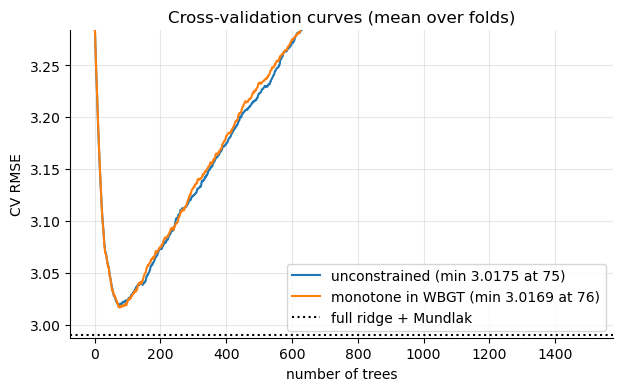

(8 s)


In [53]:
t0 = time.time()
res_gbm = {}
for nom, mono in [("unconstrained", None), ("monotone in WBGT", {"wbgt": 1})]:
    n, r, courbe = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1500, monotone=mono)
    res_gbm[nom] = (n, r, courbe)
    print(f"{nom:16s}: n* = {n:4d} trees, CV RMSE = {r:.5f}")
plt.figure(figsize=(7, 4))
for nom, (n, r, courbe) in res_gbm.items():
    plt.plot(np.arange(1, len(courbe) + 1), courbe, label=f"{nom} (min {r:.4f} at {n})")
plt.axhline(RESULTATS_CV["full ridge + Mundlak"]["rmse"].mean(), color="k", ls=":", label="full ridge + Mundlak")
plt.xlabel("number of trees"); plt.ylabel("CV RMSE"); plt.ylim(None, np.min([c[2][0] for c in res_gbm.values()]))
plt.legend(); plt.title("Cross-validation curves (mean over folds)"); plt.show()
print(f"({time.time() - t0:.0f} s)")

**Analysis.**

| model | number of trees $n^\star$ | CV RMSE |
|---|---|---|
| unconstrained LightGBM | 75 | 3.017 |
| LightGBM monotone in the WBGT | 76 | 3.017 |
| *reminder*: full ridge + Mundlak (part 3) | – | 2.990 |
| *reminder*: simplest ridge, degree 1 (part 3) | – | 2.996 |
| *reminder*: retained mixed model (part 4) | – | 3.013 |
| *reminder*: constant model (part 3) | – | 3.300 |

**The monotonicity constraint costs nothing.** The monotone model obtains 3.0169 against 3.0175 without
constraint: it even does very slightly better, with an almost identical number of trees. Imposing that the
heat never makes one run faster therefore does not contradict the data; the constraint acts at most
as a slight regularization. This is an important result for what follows: this physiological
knowledge can be imposed without loss of accuracy.

**Boosting does no better than the linear models.** With 3.017, LightGBM is on a par with the
mixed model (3.013) and slightly worse than ridge (2.990 to 2.996). All these gaps are smaller
than 0.03, whereas the standard error across folds is about 0.19 (part 2.5): the models are equivalent in
prediction. The flexibility of trees brings nothing measurable. The signal that transfers from one venue to
another is therefore essentially **smooth and close to additive** (effects of age, level, form,
duration), which linear models already capture. The nonlinearities and interactions that trees
could discover are either absent or too weak to be distinguished from noise with some 300
races.

**The shape of the validation curve.** Both curves fall quickly during the first few dozen
trees, reach their minimum around **75 trees**, then **rise steadily**: around 600 trees, the
RMSE exceeds 3.25 and returns to the value obtained with a single tree (the top of the figure). With a learning rate of 0.03, 75 trees roughly correspond to the number
needed to capture most of a simple signal (part 5.1): the model stops as soon as it has learned
the general regularities. Beyond that, each tree learns particularities of the training venues, which
do not transfer to the validation venues: this is overfitting, and it is fast. The curves
always remain above the ridge line. The strong rise confirms the value of choosing the number
of trees by cross-validation: beyond 600 trees, an overtrained model does worse than an
almost constant model.

### 5.4 Does the WBGT summarize the weather well? What does a poorly built validation cost?

Two experiments complete the study of boosting, with the baseline parameters and a number of trees chosen
each time by the cross-validation curve.

**Experiment 1: which weather variables?** We compare four sets of variables, the other
context variables remaining the same:

| set of variables | weather variables |
|---|---|
| WBGT (+ wind, rain) | WBGT, wind, rain, mean WBGT of the course |
| raw components | air temperature, humidity, wind, radiation, rain, mean WBGT of the course |
| WBGT + components | WBGT, wind, rain, temperature, humidity, radiation, mean WBGT of the course |
| no weather | none (no wind, no rain, no Mundlak term) |

Part 1.2 showed that the WBGT combines its components in very different ways depending on the type of race
(hot and dry track meetings, cool but sunny and humid marathons). Two hypotheses
are opposed. If the physical summary of the WBGT loses useful information (for example if humidity weighs more
than the formula says), the raw components should predict better. If on the contrary the summary is
relevant, it should do at least as well with fewer variables, hence fewer ways of
overfitting. The "no weather" model measures the total contribution of the weather to prediction.

**Experiment 2: which validation split?** We compare, for the same model, cross-validation by
venue and a **random** five-fold cross-validation on the rows. Part 2.1 showed that a
random split places 77 of the 79 venues, and most of the courses and races, on both
sides. We measure here what this leakage does to the reported error and to the number of trees chosen.

In [54]:
METEO_BRUTE = ["t_air", "hr", "vent_10m", "rayonnement_global", "precipitation_mm_h"]
variantes = {"WBGT (+ wind, rain)": NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK,
             "raw components": NUM_CONTEXTE + METEO_BRUTE + NUM_MUNDLAK,
             "WBGT + components": NUM_CONTEXTE + NUM_METEO + METEO_BRUTE[:2] + ["rayonnement_global"] + NUM_MUNDLAK,
             "no weather": NUM_CONTEXTE}
tab_var = []
for nom, num in variantes.items():
    n, r, _ = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, PLIS, num, CAT_GBM, n_max=1200)
    tab_var.append({"variables": nom, "n*": n, "CV RMSE": r})
print(pd.DataFrame(tab_var).round(5).to_string(index=False))

from sklearn.model_selection import KFold
plis_aleatoires = list(KFold(5, shuffle=True, random_state=SEED).split(df_train))
n_alea, r_alea, _ = courbe_cv_lgbm(PARAMS_LGBM_BASE, df_train, plis_aleatoires, NUM_GBM, CAT_GBM, n_max=1500)
print(f"\nRandom K-fold: n* = {n_alea}, CV RMSE = {r_alea:.5f}  |  by venue: n* = {res_gbm['unconstrained'][0]}, "
      f"CV RMSE = {res_gbm['unconstrained'][1]:.5f}")

          variables  n*  CV RMSE
WBGT (+ wind, rain)  75  3.01748
     raw components  97  3.00832
  WBGT + components  85  3.00827
         no weather  82  3.01408



Random K-fold: n* = 1498, CV RMSE = 2.37776  |  by venue: n* = 75, CV RMSE = 3.01748


**Analysis.**

| set of variables | $n^\star$ | CV RMSE |
|---|---|---|
| WBGT (+ wind, rain) | 75 | 3.017 |
| raw components | 97 | 3.008 |
| WBGT + components | 85 | 3.008 |
| no weather | 82 | 3.014 |

**Weather does not improve prediction.** The four sets of variables lie within 0.01 of RMSE (from 3.008
to 3.017), and the model **without any weather variable** (3.014) does as well as the model with the
WBGT (3.017). The raw components do very slightly better than the WBGT (0.009), but this gap is twenty
times smaller than the standard error across folds (about 0.19): it allows us to conclude neither that the WBGT loses
information, nor that it summarizes it well. On these data and with this split, the sets
of variables cannot be ranked by their predictive power.

**Why a real effect can bring nothing in prediction.** This result does not contradict the effect of the
heat estimated in part 4 (about 2 points of $y$ for 10 °C). It illustrates the difference between **estimating an
effect** and **improving a prediction**. An order of magnitude shows it. If heat acts with a slope
$b \approx 0.2$ point per °C, and if the WBGT varies with a standard deviation of about 4.4 °C, the variance of $y$ due to
heat is at most $b^2\,\text{Var}(W) \approx 0.04 \times 19.5 \approx 0.8$. Relative to a residual
variance of about $3^2 = 9$, it would lower the RMSE by at most $0.8/(2 \times 3) \approx 0.13$, and
only if the effect were perfectly known. The actual gain is much smaller, for three reasons:

* a large part of the variation of the WBGT is **already explained** by the event group and the time
  (hot track in the evening, cool marathon in the morning): what remains to be explained by the weather is the variation
  of the WBGT for a given event and time, which is smaller;
* the effect is **heterogeneous**: strong in the marathon, zero in middle distance, where half of the hot
  races are found (part 1.2);
* the effect is **estimated** from some 300 races, few of them hot: the estimation error
  adds variance to the predictions and absorbs part of the gain.

A potential gain of a few hundredths, drowned in a variability across folds of 0.19, is invisible in
cross-validation. The quality of the tool will therefore be judged on the **estimate of the effect** and on its
uncertainty (parts 4 and 8), not on the RMSE: this is what part 2.2 announced.

**Random folds report an illusory performance.**

| validation | $n^\star$ | CV RMSE |
|---|---|---|
| random K-fold on the rows | 1,498 | 2.378 |
| K-fold by venue | 75 | 3.017 |

With random folds, the reported RMSE drops to **2.378**, a performance overestimated by 21%, and the
number of trees retained reaches **1,498**, at the limit of the search ($n_{\max} = 1{,}500$): twenty times more
than with the folds by venue, and probably more if the search had continued. The explanation lies in
the structure of the data. With random folds, each race has runners in training and in
validation. The model can then **memorize the specific effect of each race** (its date, its venue, its weather,
its field, its race dynamics) and give it back to the runners of the same race in validation. The more
trees it adds, the more finely it memorizes, and the better it "predicts": the validation curve no longer rises,
hence the maximum number of trees.

A model selected this way would be doubly misleading: its reported performance would be wrong, and its
number of trees, chosen to memorize, would make it heavily overfitted and disappointing on a new venue,
that is, exactly in the intended use of the tool (the curve by venue of part 5.3 shows what
1,500 trees cost on new venues). This is the empirical confirmation of the information leakage
described in part 2.1.

## Part 6 — Neural network

The previous parts used two broad families of models: **linear** models (parts 3
and 4), whose shape is fixed in advance, and **trees** (part 5), flexible but
stepwise. **Neural networks** form a third family, flexible like trees but
producing **smooth** functions. This part presents them without assuming any prior knowledge:
what they are, what they can represent, how they learn, and what they are worth on a problem
such as ours.

### 6.1 What is a neural network?

#### What a neural network is for

Like all the models of this study, a neural network is a **parameterized function** $f_\theta$ that
maps a vector of variables $x$ to a prediction $\hat y = f_\theta(x)$. Its parameters $\theta$ are
learned by minimizing a loss on examples (part 0.5). Its distinctive feature is that it belongs to a
**very rich** family of functions: with enough parameters, it can represent almost any
relationship between $x$ and $y$, without the shape having to be specified (line, polynomial, interactions). We do not
tell it "the effect of age is quadratic": it discovers it.

Neural networks are behind the recent progress in image recognition, machine
translation, speech recognition or text generation: problems where the data are
**massive** (millions of examples) and **unstructured** (pixels, words), and where nobody knows how to
write down the shape of the relationship by hand. They also apply to **tabular** data such as
ours (a table of rows and columns), but with less success, as we will see.

#### The artificial neuron

The basic unit is the **neuron**: it computes a linear combination of its inputs, then applies to it
a nonlinear function $\sigma$, called the **activation**:

$$h = \sigma\Big(\sum_{r=1}^{d} w_r\,x_r + b\Big) = \sigma(w^\top x + b).$$

The $w_r$ are the **weights**, $b$ the **bias** (a constant). In this part, $\sigma$ denotes an activation
function, and no longer a standard deviation. The name comes from a distant analogy with the
biological neuron, which fires when the sum of its input signals exceeds a threshold. Two special
cases show that a neuron has nothing mysterious about it: if $\sigma$ is the identity, a neuron is
exactly a **linear regression**; if $\sigma$ is the sigmoid $1/(1 + e^{-z})$, it is a
**logistic regression**.

#### Layers

A network assembles neurons into **layers**. A layer of $m$ neurons all receiving the same input
vector $h \in \mathbb{R}^{d}$ is written in matrix notation:

$$h' = \sigma(W h + b), \qquad W \in \mathbb{R}^{m \times d},\ b \in \mathbb{R}^{m},$$

where each row of $W$ contains the weights of one neuron and $\sigma$ is applied componentwise. The
**multilayer perceptron** (MLP) chains several layers: the output of one is the input of the next.

$$h_0 = x, \qquad h_k = \sigma(W_k\, h_{k-1} + b_k) \ \ (k = 1, \dots, L), \qquad \hat y = w_{L+1}^\top h_L + b_{L+1} .$$

The intermediate layers are called **hidden**: we observe neither their inputs nor their outputs, only
$x$ and $y$. The number of neurons in a layer is its **width**, the number of layers the **depth** of the
network. A layer that receives $d$ inputs and has $m$ neurons has $(d + 1) \times m$ parameters (the weights
and one bias per neuron): the number of parameters grows quickly with width.

#### Why a nonlinear activation

Without activation, a network would only be a **disguised linear regression**: the composition of two
affine functions is affine,

$$W_2(W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2),$$

and stacking layers would be useless. It is the activation that gives the network its ability to represent
nonlinear relationships. The most common ones are:

| activation | formula | properties |
|---|---|---|
| sigmoid | $1/(1 + e^{-z})$ | smooth, with values in $(0, 1)$; its derivative is very small for large $\lvert z \rvert$, which slows down the training of deep networks |
| ReLU | $\max(0, z)$ | very simple, derivative 0 or 1; the network is then a piecewise affine function |
| SiLU | $z\,\sigma(z)$ | close to ReLU, but smooth and differentiable everywhere: the network is a smooth function |

**A geometric intuition.** With the ReLU activation, each neuron of the first layer "folds" space
along the hyperplane $w^\top x + b = 0$: it is 0 on one side and grows linearly on the other. In one
dimension, a sum of neurons $\sum_k c_k \max(0, x - s_k)$ is a **broken line** whose kinks are
located at $s_k$ and whose slopes change by $c_k$ at each kink. With enough kinks, a broken line
approximates any continuous curve: this is the idea of the following theorem.

#### What a network can represent: the universal approximation theorem

> **Theorem** (Cybenko, 1989; Hornik, 1991; Leshno *et al.*, 1993). Let $\sigma$ be a continuous
> and non-polynomial activation function. For any continuous function $g$ defined on a compact set $K \subset \mathbb{R}^d$ and
> for any $\varepsilon > 0$, there exists a network with **a single hidden layer**, with a finite number $N$ of
> neurons,
> $$f_N(x) = \sum_{k=1}^{N} c_k\,\sigma(w_k^\top x + b_k),$$
> such that $\sup_{x \in K} \lvert g(x) - f_N(x) \rvert < \varepsilon$.

This theorem says that no continuous relationship is out of reach of a wide enough network. One must also
know what it **does not say**:

* it guarantees the **existence** of suitable weights, but does not say how to **find** them: training
  is a difficult optimization problem (below);
* the number of neurons needed can be **gigantic**;
* it concerns the approximation of a **known** function over all of $K$, not learning from a
  **finite** and noisy **sample**: a network able to represent anything is also able to represent the
  noise, that is, to **overfit**;
* it says nothing about the behavior **outside** the domain $K$: a network does not extrapolate reliably.

**Width or depth?** The theorem uses only one hidden layer, but depth is often more
economical: some functions require an exponential number of neurons with a single layer, and only
a polynomial number with several layers (Telgarsky, 2016). Each layer can build more elaborate
features from those of the previous layer.

#### How a network learns: optimization and backpropagation

**A non-convex optimization problem.** We look for the parameters $\theta$ (all the matrices $W_k$ and
all the biases) that minimize the empirical risk, here the mean squared error
$\hat{\mathcal R}(\theta) = \frac1n\sum_i (y_i - f_\theta(x_i))^2$. Unlike least squares (part
3.2), there is no closed form, and the function to minimize is **not convex**: it has many
local minima and saddle points. We proceed by **gradient descent**: we start from randomly drawn weights,
and move step by step in the direction opposite to the gradient,

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \hat{\mathcal R}(\theta),$$

where $\eta$ is the **learning rate**. Too large, the steps make the optimization diverge; too small,
it is very slow. Nothing guarantees reaching the global minimum, but in practice the minima reached
by this procedure are often good. The result nevertheless depends on the initial draw of the weights: two
trainings with different seeds give two different networks.

**Backpropagation.** The gradient of the loss must be computed with respect to thousands of parameters.
**Backpropagation** does this efficiently through the chain rule, applied layer by layer
from the output to the input. Take a network with one hidden layer, $z = W_1 x + b_1$, $h = \sigma(z)$,
$\hat y = w_2^\top h + b_2$, and the loss of one observation $\ell = \frac12(\hat y - y)^2$. Writing
$\delta = \hat y - y$ for the prediction error:

$$\frac{\partial \ell}{\partial b_2} = \delta, \qquad
  \frac{\partial \ell}{\partial w_2} = \delta\,h, \qquad
  \frac{\partial \ell}{\partial h} = \delta\,w_2, \qquad
  \frac{\partial \ell}{\partial z} = (\delta\,w_2) \odot \sigma'(z), \qquad
  \frac{\partial \ell}{\partial W_1} = \frac{\partial \ell}{\partial z}\,x^\top, \qquad
  \frac{\partial \ell}{\partial b_1} = \frac{\partial \ell}{\partial z},$$

where $\odot$ is the componentwise product. The mechanism is visible: the error $\delta$ is
**propagated backward** through the weights $w_2$, then multiplied by the derivative of the activation. The computation
reuses the quantities of the forward pass ($h$, $z$) and costs about as much as a prediction. PyTorch
automates it: it records the operations of the forward pass (the "computational graph") and computes all the
gradients with `backward()`. One also sees why the sigmoid hinders deep networks: its derivative,
at most 1/4, is multiplied once per layer, and the gradient vanishes on its way back.

#### The main risk: overfitting

A network has many parameters. The one of the demonstration in part 6.5 has about 11,000,
for some 6,400 training performances: more parameters than observations. Such a network can,
in principle, memorize the training data, noise included. It must therefore be **regularized**
(part 6.4) and its complexity chosen by cross-validation, like the other models.

#### When to use a neural network?

| | advantages | drawbacks |
|---|---|---|
| **flexibility** | approximates any continuous relationship (approximation theorem); interactions discovered automatically | high risk of overfitting, especially with little data |
| **shape of the function** | **smooth** function (with SiLU), suited to regular effects | does not extrapolate reliably outside the data |
| **data** | scales to millions of examples; handles images, texts, sounds | needs a lot of data to beat simpler models |
| **categorical variables** | compact *embeddings*, even for thousands of categories (part 6.2) | |
| **tuning** | flexible: loss, architecture, constraints can be adapted | many sensitive hyperparameters (learning rate, architecture, regularization); standardization essential |
| **reproducibility** | | non-convex optimization: the result depends on the random seeds |
| **interpretation** | | "black box": the weights have no direct interpretation (part 8) |
| **cost** | | training slower than linear models or boosting on small data |

On **tabular data of modest size**, such as ours (about 8,000 performances and some
fifteen variables), neural networks generally **do no better** than gradient boosting
or well-specified linear models (Grinsztajn *et al.*, 2022). Our expectations are therefore measured: the
network serves here as a point of comparison, and its smooth shape could suit regular effects such as
those of age, level or the WBGT, which trees cut into steps.

### 6.2 Categorical variables: *embeddings*

A network only handles numbers. For a categorical variable (event group, sex), part 2.4
used **one-hot** encoding: one 0/1 column per category. Neural networks rather use
**embeddings**.

**Definition.** An *embedding* maps each category $m$ to a **learned** vector $e_m \in \mathbb{R}^{d_e}$, stored
in a table $E$ (one row per category). The network receives $e_m$ instead of the category. This is
equivalent to multiplying the *one-hot* encoding of the category by the matrix $E$,

$$e_m = E^\top\,\mathbb 1_m, \qquad \mathbb 1_m = (0, \dots, 0, 1, 0, \dots, 0),$$

that is, to a first linear layer without bias applied to the *one-hot* vector, but implemented as a
simple table lookup. The vectors are learned together with the rest of the network, by
backpropagation: two categories with similar effects end up with similar vectors.

**Interest.** For a variable with very many categories (thousands of products, words, customers),
*one-hot* encoding would produce thousands of columns; an *embedding* of dimension 8 or 16 summarizes them in a
dense vector, which shares information between similar categories. Here, the categorical variables only have
5 and 2 categories: the *embedding* brings little compared with *one-hot*, but it is the
standard way of handling them in a network. The dimension of the *embedding* is capped by the number of
categories: a vector of dimension 4 for a variable with 3 categories would bring no more
information.

**Coding the categories.** To read the table, each category must be coded by an integer. This coding is
**learned on the training set**, like the rest of the preprocessing (part 2.4): the categories seen receive the
integers $1, 2, \dots$ (in alphabetical order), and **the integer 0 is reserved for unknown categories**, seen
only in validation or in test. The table therefore has one more row than the number of categories seen (the
"cardinality" includes the unknown category). Recomputing the coding on the test set would be a mistake: the
integers would no longer designate the same categories, and the network would read the wrong row of the table.

The test checks this behavior: with the categories "x" and "y" seen in training, "y" receives the
code 2, the unknown category "z" the code 0, and the cardinality is 3.

In [55]:
class EncodeurCategories:
    '''Codes each category seen at fit time by an integer >= 1; 0 = unknown.

    After fit: modalites_ (dict col -> dict category -> code), cardinalites_ (list, unknown included)
    '''

    def __init__(self, colonnes):
        self.colonnes = list(colonnes)

    def fit(self, df):
        self.modalites_ = {c: {m: k + 1 for k, m in enumerate(sorted(df[c].astype(str).unique()))}
                           for c in self.colonnes}
        self.cardinalites_ = [len(self.modalites_[c]) + 1 for c in self.colonnes]
        return self

    def transform(self, df):
        '''Output: np.ndarray int64 (n, n_columns).'''
        return np.column_stack([df[c].astype(str).map(self.modalites_[c]).fillna(0).to_numpy(dtype=np.int64)
                                for c in self.colonnes])

In [56]:
#test
_e = EncodeurCategories(["a"]).fit(pd.DataFrame({"a": ["x", "y", "x"]}))
assert _e.cardinalites_ == [3] and _e.transform(pd.DataFrame({"a": ["y", "z"]})).tolist() == [[2], [0]]
print("EncodeurCategories: OK")

EncodeurCategories: OK


### 6.3 Network architecture

Our network is a multilayer perceptron whose input concatenates the standardized numerical variables
$x^{\text{num}}$ and one *embedding* per categorical variable:

$$h_0 = [x^{\text{num}},\ e_{\text{group}},\ e_{\text{sex}}],\qquad
  h_k = \text{Dropout}\big(\text{SiLU}(W_k\, h_{k-1} + b_k)\big),\qquad \hat y = w_{L+1}^\top h_L + b_{L+1} .$$

* **The inputs.** The numerical variables are those of boosting: level, age, form, duration, altitude,
  time, WBGT, wind, rain and mean WBGT of the course, plus the missing-value indicators of age and
  form, that is, 12 columns. The *embedding* of the event group (5 categories and the unknown category) has
  dimension 4, that of sex (2 categories and the unknown one) dimension 3. The input $h_0$ therefore has 19 components.
* **The hidden layers.** Their number and width are hyperparameters: two layers of 64 and 32
  neurons by default, of 128 and 64 in the experiments below.
* **The SiLU activation**, $\text{SiLU}(z) = z\,\sigma(z)$, with derivative $\sigma(z)\big(1 + z\,(1 - \sigma(z))\big)$,
  is smooth: the learned function is smooth too.
* **Dropout**, applied after each hidden layer, is presented in part 6.4.
* **The output** is a single neuron without activation: a linear combination of the last hidden layer,
  which can take any real value, like $y$.

**The number of parameters.** For a (128, 64) architecture: $(19 + 1) \times 128 = 2{,}560$ parameters for the
first layer, $(128 + 1) \times 64 = 8{,}256$ for the second, $64 + 1 = 65$ for the output, and
$6 \times 4 + 3 \times 3 = 33$ for the two *embedding* tables, that is, **10,914 parameters**. The test builds
a small network (5 numerical variables, categories of cardinalities 3 and 4, *embeddings* capped at 3 and 4,
layers of 16 and 8 neurons) and checks that it has $13 \times 16 + 17 \times 8 + 9 + 9 + 16 = 378$ parameters.

**A shape trap.** The output is reduced to a vector of shape $(n,)$ and not $(n, 1)$. Otherwise, the
comparison with the target, of shape $(n,)$, would be "broadcast" into an $(n, n)$ matrix of
all the cross differences: the loss would be wrong, without any error message.

**Execution.** The code of the network is written in the module `reseau_torch.py` (`%%writefile` command) and run in the PyTorch process, as is its test (part 0.7).

In [57]:
%%writefile reseau_torch.py
# Module run in the PyTorch process (part 0.7): PyTorch is imported first there.
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

torch.set_num_threads(2)


class ReseauPerf(nn.Module):
    '''MLP with embeddings. n_num: number of numerical variables; cardinalites: list of integers.'''

    def __init__(self, n_num, cardinalites, dim_emb=4, couches=(64, 32), dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, min(dim_emb, c)) for c in cardinalites])
        d = n_num + sum(e.embedding_dim for e in self.embs)
        blocs = []
        for h in couches:
            blocs += [nn.Linear(d, h), nn.SiLU(), nn.Dropout(dropout)]
            d = h
        blocs.append(nn.Linear(d, 1))
        self.mlp = nn.Sequential(*blocs)

    def forward(self, x_num, x_cat):
        '''x_num: (n, n_num) float32; x_cat: (n, n_cat) int64. Output: (n,).'''
        z = torch.cat([x_num] + [emb(x_cat[:, k]) for k, emb in enumerate(self.embs)], dim=1)
        return self.mlp(z).squeeze(-1)

Overwriting reseau_torch.py


In [58]:
#test (run in the PyTorch process, part 0.7)
tester('''
torch.manual_seed(0)
_r = ReseauPerf(5, [3, 4], dim_emb=8, couches=(16, 8))
_out = _r(torch.randn(7, 5), torch.tensor([[0, 1]] * 7))
assert _out.shape == (7,) and _r.embs[0].embedding_dim == 3
print("ReseauPerf: OK,", sum(p.numel() for p in _r.parameters()), "parameters")
''')

ReseauPerf: OK, 378 parameters


### 6.4 Training and regularization

#### Stochastic gradient descent

Computing the gradient of the risk on all the data at each step would be costly. It is computed instead on
a **mini-batch** of $n_{\text{batch}}$ observations drawn at random (here 128 or 256):

$$\theta \leftarrow \theta - \eta\,\nabla_\theta\,\frac{1}{n_{\text{batch}}}\sum_{i \in \text{batch}} (y_i - f_\theta(x_i))^2 .$$

The gradient of a mini-batch is an **unbiased** estimator of the full gradient, noisier but much
cheaper: many small approximate steps are taken rather than a few large exact steps. This noise
even helps to escape poor local minima and saddle points. An **epoch** is a complete pass over
the data, in mini-batches drawn in random order. Each step involves four operations: resetting
the gradients to zero (otherwise they accumulate from one step to the next), computing the loss of the mini-batch,
backpropagating it, and updating the parameters.

#### The Adam optimizer

With a single learning rate, parameters with a large gradient move too fast and those with
a small gradient too slowly. The **Adam** optimizer (Kingma and Ba, 2015) adapts the step of each
parameter from two moving averages, that of the gradient $g_t$ (a "momentum") and that of its square
(a measure of its magnitude):

$$m_t = \beta_1 m_{t-1} + (1 - \beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1 - \beta_2)\,g_t^2,$$

$$\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
  \theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon},$$

with $\beta_1 = 0.9$ and $\beta_2 = 0.999$ by default. The divisions by $1 - \beta^t$ correct the bias due to
initializing the averages at 0 during the first steps. The ratio $\hat m_t/\sqrt{\hat v_t}$ is of order
1 when the gradient is consistent and smaller when it is noisy: each parameter moves by about $\eta$
in a stable direction, and cautiously in an uncertain one.

#### Three regularizations

**Decoupled *weight decay* (AdamW).** At each step, we add $\theta \leftarrow \theta - \eta\,\lambda\,\theta$:
the weights are shrunk toward 0, as in a ridge regression (part 3.2). With Adam, this
"decoupled" version (Loshchilov and Hutter, 2019) differs from a penalty $\lambda\lVert\theta\rVert^2$ added to the
loss: the gradient of the penalty would be divided by $\sqrt{\hat v_t}$, and therefore applied very unevenly to the
parameters.

***Dropout*** (Srivastava *et al.*, 2014). During training, each neuron of a hidden layer is
set to zero with probability $p$, independently at each mini-batch, and the neurons kept are
multiplied by $1/(1 - p)$ so that the expected output does not change. The network cannot rely on
any particular neuron, nor on a fragile combination of neurons: it must spread the information. The effect is
close to averaging a very large number of subnetworks. At prediction time, *dropout* is disabled (`eval`
mode): all neurons are used.

**Early stopping.** Over the epochs, the training error keeps decreasing, but
the error on unseen data decreases then rises again when the network starts to overfit (part 5.3).
We therefore measure the validation loss at each epoch, keep a **copy** of the weights that minimized it,
and stop training after a fixed number of epochs without improvement, the **patience**; the best
weights are then reloaded. Two details matter: an improvement is only retained if it exceeds
a small tolerance, and the copy must be **deep** (a mere reference would point to the current
weights, which keep changing, and the final weights would be kept).

**Reproducibility.** The seeds of the weight initialization and of the order of the mini-batches are fixed: the
same training always gives the same network.

The test trains a small network on simulated data ($y = 2x_1 - x_2$): the training loss must
be divided by more than 5 in 60 epochs. With a patience of 5 epochs, training must stop before
the limit of 500 epochs, and the reloaded weights must give exactly the best validation loss
observed.

**Execution.** The training loop completes the module `reseau_torch.py`, and its test runs in the PyTorch process (part 0.7).

In [59]:
%%writefile -a reseau_torch.py


# Continuation of the reseau_torch.py module (PyTorch process, part 0.7).
import copy


def entrainer_reseau(modele, Xn, Xc, y, Xn_val=None, Xc_val=None, y_val=None, lr=1e-3, weight_decay=1e-4,
                     epochs=100, batch_size=256, patience=None, seed=0, tol=1e-6):
    '''Trains modele in place. Xn float32 (n, p), Xc int64 (n, q), y float32 (n,): torch tensors.

    Output: dict {"train": [losses], "val": [losses]} (MSE per epoch).
    '''
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(Xn, Xc, y), batch_size=batch_size, shuffle=True, generator=gen)
    perte = nn.MSELoss()
    hist = {"train": [], "val": []}
    meilleur, etat, attente = np.inf, None, 0
    for _ in range(epochs):
        modele.train()
        cumul = 0.0
        for xb, cb, yb in loader:
            opt.zero_grad()
            l = perte(modele(xb, cb), yb)
            l.backward()
            opt.step()
            cumul += l.item() * len(yb)
        hist["train"].append(cumul / len(y))
        if y_val is not None:
            modele.eval()
            with torch.no_grad():
                v = perte(modele(Xn_val, Xc_val), y_val).item()
            hist["val"].append(v)
            if v < meilleur - tol:
                meilleur, etat, attente = v, copy.deepcopy(modele.state_dict()), 0
            else:
                attente += 1
                if patience is not None and attente >= patience:
                    break
    if patience is not None and etat is not None:
        modele.load_state_dict(etat)
    return hist

Appending to reseau_torch.py


In [60]:
#test (run in the PyTorch process, part 0.7)
tester('''
_g = torch.Generator().manual_seed(0)
_Xn = torch.randn(400, 3, generator=_g); _Xc = torch.zeros(400, 1, dtype=torch.long)
_y = (_Xn[:, 0] * 2 - _Xn[:, 1]).float()
_m = ReseauPerf(3, [2], couches=(16,), dropout=0.0)
_h = entrainer_reseau(_m, _Xn[:300], _Xc[:300], _y[:300], _Xn[300:], _Xc[300:], _y[300:], lr=1e-2, epochs=60, batch_size=50)
assert _h["train"][-1] < 0.2 * _h["train"][0] and len(_h["val"]) == 60
_m2 = ReseauPerf(3, [2], couches=(16,), dropout=0.0)
_h2 = entrainer_reseau(_m2, _Xn[:300], _Xc[:300], _y[:300], _Xn[300:], _Xc[300:], _y[300:], lr=1e-2, epochs=500,
                       batch_size=50, patience=5)
_m2.eval()
with torch.no_grad():
    _v = nn.MSELoss()(_m2(_Xn[300:], _Xc[300:]), _y[300:]).item()
assert len(_h2["val"]) < 500 and np.isclose(_v, min(_h2["val"]), rtol=1e-5)
print("entrainer_reseau: OK (stopped after", len(_h2["val"]), "epochs)")
''')

entrainer_reseau: OK (stopped after 200 epochs)


### 6.5 Pipeline, ensemble of networks and number of epochs

**The pipeline.** `PipelineReseau` assembles the previous elements with the conventions of the other models
(`fit`, `predict`):

* the numerical variables are imputed, completed by the missing-value indicators and **standardized**
  (part 2.4). This is essential for a network: with variables of very different scales (an age
  of the order of 30, rain of the order of 0.1), the gradients would be unbalanced and the initialization of the
  weights unsuitable;
* the **target is also standardized** (training mean and standard deviation), then the predictions are
  brought back to the scale of $y$. The network thus works on a target with mean 0 and standard deviation 1, which
  makes the default initialization and learning rate suitable;
* the categories are coded by the encoder of part 6.2;
* `n_modeles` networks are trained with different seeds, and their predictions are **averaged**.

**Why an ensemble of networks.** Two networks trained with different seeds give different
predictions: this is a source of variance specific to non-convex optimization. If $n_{\text{mod}}$ predictors
each have a variance $s^2$ and a pairwise correlation $\rho$, their mean has variance

$$\text{Var}\Big(\frac{1}{n_{\text{mod}}}\sum_{m=1}^{n_{\text{mod}}} f_m\Big) = \rho\,s^2 + \frac{1 - \rho}{n_{\text{mod}}}\,s^2 ,$$

which decreases with $n_{\text{mod}}$ as long as the networks are not perfectly correlated. The bias does not change: an
ensemble reduces variance at no cost in bias.

**Demonstration of overfitting.** We first train a fairly wide network (two layers of 128 and 64
neurons, about 11,000 parameters), **without *dropout* or *weight decay***, with a learning rate of
$3\cdot 10^{-3}$, on four folds of venues, monitoring the error on the fifth fold (new venues). We
compare two stopping points: at the end of the 150 epochs, and by early stopping with a patience of 15 epochs. The figure
plots the training and validation RMSE at each epoch.

**The number of epochs by cross-validation.** As for boosting (part 5.3), stopping on a fold then
evaluating on this same fold would be optimistic. We therefore record the validation RMSE after each epoch on
each fold, **average the curves**, and retain the minimum of the mean curve. We thus compare two
settings of the same (128, 64) network, with a learning rate of $10^{-3}$: without regularization, and with
*dropout* ($p = 0.2$) and *weight decay* ($\lambda = 10^{-2}$). To limit computing time, the search
covers three folds out of five and at most 60 epochs.

**Execution.** All these operations go through `PipelineReseau`, which preprocesses the data in the main process and hands over the training and the prediction of the networks to the PyTorch process (part 0.7).

In [61]:
class PipelineReseau:
    '''Preprocessing + ensemble of ReseauPerf networks. Same fit(df) / predict(df) conventions.

    Preprocessing runs here; training and prediction of the networks run in the PyTorch process
    (part 0.7). reseaux_ holds the weights of the networks, as numpy arrays.
    '''

    def __init__(self, num, cat, couches=(64, 32), dropout=0.1, dim_emb=4, lr=1e-3, weight_decay=1e-4,
                 epochs=100, batch_size=256, n_modeles=1, seed=SEED, patience=None):
        self.num, self.cat = list(num), list(cat)
        self.hp = dict(couches=tuple(couches), dropout=dropout, dim_emb=dim_emb)
        self.lr, self.wd, self.epochs, self.bs = lr, weight_decay, int(epochs), int(batch_size)
        self.n_modeles, self.seed, self.patience = n_modeles, seed, patience

    def _tableaux(self, df, avec_y=True):
        """Numpy arrays sent to the PyTorch process (part 0.7)."""
        Xn = self.pre_.transform(df).astype(np.float32)
        Xc = self.enc_.transform(df).astype(np.int64)
        y = ((df[CIBLE].to_numpy() - self.my_) / self.sy_).astype(np.float32) if avec_y else None
        return Xn, Xc, y

    def fit(self, df, df_eval=None):
        self.pre_ = Preprocesseur(self.num, []).fit(df)
        self.enc_ = EncodeurCategories(self.cat).fit(df)
        self.my_, self.sy_ = float(df[CIBLE].mean()), float(df[CIBLE].std())
        Xn, Xc, y = self._tableaux(df)
        ev = self._tableaux(df_eval) if df_eval is not None else (None, None, None)
        # training of the n_modeles networks in the PyTorch process: their weights come back as numpy arrays
        self.reseaux_, self.historiques_ = executer(
            "entrainer_ensemble", Xn, Xc, y, *ev, cardinalites=self.enc_.cardinalites_, hp=self.hp, lr=self.lr,
            weight_decay=self.wd, epochs=self.epochs, batch_size=self.bs, patience=self.patience,
            n_modeles=self.n_modeles, seed=self.seed)
        if df_eval is not None:   # validation RMSE curve (units of y), averaged over the ensemble
            self.courbe_ = np.sqrt(np.mean([np.array(h["val"]) for h in self.historiques_], axis=0)) * self.sy_
        return self

    def predict(self, df):
        Xn, Xc, _ = self._tableaux(df, avec_y=False)
        # prediction of the ensemble in the PyTorch process, from the weights kept here
        p = executer("predire_ensemble", self.reseaux_, Xn, Xc, cardinalites=self.enc_.cardinalites_, hp=self.hp)
        return p * self.sy_ + self.my_


NUM_NN = NUM_CONTEXTE + NUM_METEO + NUM_MUNDLAK
CAT_NN = CAT_CONTEXTE

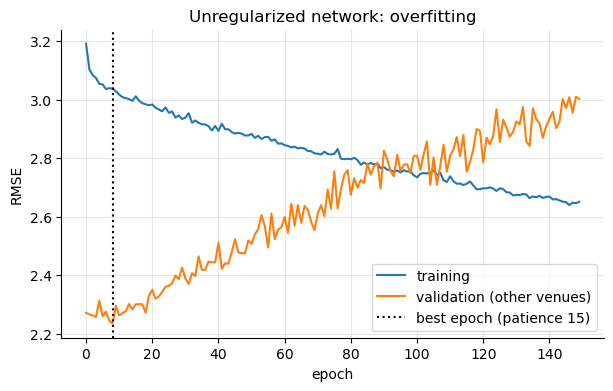

Validation RMSE: end of training 3.0015 | early stopping 2.2350   (7 s)


In [62]:
t0 = time.time()
_a, _v = df_train.iloc[PLIS[0][0]], df_train.iloc[PLIS[0][1]]
demo = PipelineReseau(NUM_NN, CAT_NN, couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=3e-3, epochs=150).fit(_a, _v)
demo_es = PipelineReseau(NUM_NN, CAT_NN, couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=3e-3, epochs=150,
                         patience=15).fit(_a, _v)
h = demo.historiques_[0]
plt.figure(figsize=(7, 4))
plt.plot(np.sqrt(h["train"]) * demo.sy_, label="training")
plt.plot(np.sqrt(h["val"]) * demo.sy_, label="validation (other venues)")
plt.axvline(len(demo_es.historiques_[0]["val"]) - 16, color="k", ls=":", label="best epoch (patience 15)")
plt.xlabel("epoch"); plt.ylabel("RMSE"); plt.legend(); plt.title("Unregularized network: overfitting")
plt.show()
print(f"Validation RMSE: end of training {rmse(_v[CIBLE], demo.predict(_v)):.4f} | "
      f"early stopping {rmse(_v[CIBLE], demo_es.predict(_v)):.4f}   ({time.time() - t0:.0f} s)")

**Analysis.** The figure shows the typical signature of **overfitting**:

| | epoch 1 | best validation epoch (9) | epoch 150 |
|---|---|---|---|
| training RMSE (four folds) | 3.19 | about 3.04 (read from the figure) | 2.65 |
| validation RMSE (fold 0, 14 new venues) | 2.27 | **2.24** | 3.00 |

* The **training** RMSE decreases without interruption, from 3.19 to 2.65: the network fits the venues it
  sees better and better.
* The **validation** RMSE reaches its minimum as early as the **9th epoch** (2.24), then rises almost linearly
  up to 3.00 at the 150th epoch. From then on, each epoch improves the fit to the training venues
  at the expense of new venues: the two curves diverge. With about 11,000 parameters for 6,435
  training performances, the network has ample room to memorize the noise and the particularities of each
  venue, and this is what it does after the 9th epoch.
* **Early stopping** (patience of 15 epochs) interrupts training at the 24th epoch and reloads the weights
  of the 9th: the validation RMSE is then **2.235**, against **3.002** at the end of training. The
  overfitting thus costs 0.77 point of RMSE (+34%). Without early stopping, the network even does clearly
  worse than the constant model on this fold (2.647, part 3.1).

**Why is the validation error at first lower than the training error?** It is not a
paradox. Fold 0 is the "easiest" of the five: the constant model obtains 2.65 there, against 3.30 on average
(part 3.1). Its venues have less dispersed performances. Errors can therefore only be compared within the same
fold, and it is their **evolution** that matters.

**A caveat.** The value 2.235 is optimistic: the stopping epoch was chosen on this same fold, at the
lowest point of a noisy curve (part 5.3). This is why the number of epochs is chosen below from the
mean cross-validation curve.

In [63]:
def courbe_cv_reseau(hp, df, plis, num=NUM_NN, cat=CAT_NN, epochs=150):
    '''hp: dict of PipelineReseau hyperparameters. Output: (n_epochs*, rmse_cv*, mean curve).'''
    courbes = []
    for itr, iva in plis:
        m = PipelineReseau(num, cat, epochs=epochs, **hp).fit(df.iloc[itr], df_eval=df.iloc[iva])
        courbes.append(m.courbe_)
    moyenne = np.mean(courbes, axis=0)
    k = int(np.argmin(moyenne))
    return k + 1, float(moyenne[k]), moyenne

In [64]:
#test
_n, _r, _c = courbe_cv_reseau({"couches": (16,), "lr": 1e-3}, df_train, PLIS, epochs=5)
assert len(_c) == 5 and 1 <= _n <= 5 and np.isclose(_r, _c.min())
print("courbe_cv_reseau: OK")

courbe_cv_reseau: OK


unregularized                   : epochs* =   4, CV RMSE = 2.93736


dropout 0.2 + weight decay 1e-2 : epochs* =  14, CV RMSE = 2.92631


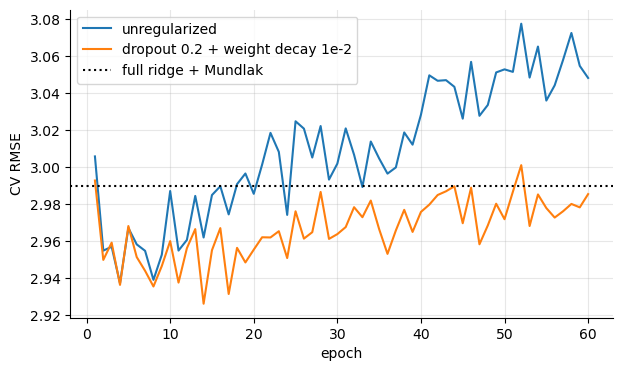

(16 s)


In [65]:
t0 = time.time()
reglages_nn = {"unregularized": dict(couches=(128, 64), dropout=0.0, weight_decay=0.0, lr=1e-3),
               "dropout 0.2 + weight decay 1e-2": dict(couches=(128, 64), dropout=0.2, weight_decay=1e-2, lr=1e-3)}
res_nn = {}
for nom, hp in reglages_nn.items():
    res_nn[nom] = courbe_cv_reseau(hp, df_train, PLIS[:3], epochs=60)   # 3 folds out of 5: computing budget
    print(f"{nom:32s}: epochs* = {res_nn[nom][0]:3d}, CV RMSE = {res_nn[nom][1]:.5f}")
plt.figure(figsize=(7, 4))
for nom, (n, r, cbe) in res_nn.items():
    plt.plot(np.arange(1, len(cbe) + 1), cbe, label=nom)
plt.axhline(RESULTATS_CV["full ridge + Mundlak"]["rmse"].mean(), color="k", ls=":", label="full ridge + Mundlak")
plt.xlabel("epoch"); plt.ylabel("CV RMSE"); plt.legend(); plt.show()
print(f"({time.time() - t0:.0f} s)")

**Analysis.** The cross-validation of the network only covers the **first three folds** (computing budget).
For a fair comparison, the network must be confronted with the other models **on the same folds**:

| model | epochs retained | CV RMSE, first 3 folds | CV RMSE, 5 folds |
|---|---|---|---|
| unregularized network | 4 | 2.937 | – |
| network with *dropout* 0.2 and *weight decay* $10^{-2}$ | 14 | **2.926** | – |
| full ridge without Mundlak (part 3) | – | 2.936 | 2.988 |
| full ridge + Mundlak (part 3) | – | 2.938 | 2.990 |
| retained mixed model (part 4) | – | 2.977 | 3.013 |
| constant model (part 3) | – | 3.281 | 3.300 |

(The "first 3 folds" columns of the models of parts 3 and 4 are the means of their RMSEs on folds
0, 1 and 2.)

**A comparison to be read with care.** The first three folds are easier than average: ridge
obtains 2.938 there against 2.990 over the five folds. The dotted line of the figure, which represents ridge over the
**five** folds, therefore **flatters the network**: on equal folds, the regularized network (2.926) only beats
ridge by 0.01, and the unregularized network (2.937) is on a par with it. These gaps are much smaller than the standard error
across folds (about 0.19): **the network does no better than a well-specified linear model**. It slightly beats
the mixed model (0.05), but within the noise as well. This is the expected result on tabular data of
modest size (part 6.1), and it confirms the diagnosis of part 5: the signal that transfers from one venue to
another is smooth and nearly additive, and a linear model already captures it.

**The role of regularization.** The two curves do not look alike at all:

* **without regularization**, the RMSE reaches its minimum as early as the **4th epoch**, then rises and exceeds 3.05 from
  the 40th epoch onward: the network overfits very quickly;
* **with *dropout* and *weight decay***, the minimum is reached later (14th epoch), and above all the curve stays
  between 2.93 and 3.00 over the 60 epochs: it barely rises.

Regularization hardly improves the best value (0.011), but it makes the network **much less
sensitive to the number of epochs**. This is valuable in practice, since this number is chosen on a noisy curve:
with regularization, an error of a few epochs costs almost nothing, whereas it costs a lot without.

**The noise of the curves.** From one epoch to the next, both curves oscillate by 0.02 to 0.03, the order of magnitude
of the gaps between models. Their minimum therefore contains a share of luck (part 5.3): the RMSEs retained are
slightly optimistic, which strengthens the conclusion of an equivalence with ridge. The evaluation on the test venues
(part 7) will settle the matter, with an ensemble of five networks to reduce the variance due to seeds.

**And *embeddings* of athlete, race or venue?** *Embeddings* would in principle make it possible to handle
variables with very many categories, such as the athlete, the race or the venue. An *embedding* per athlete would be
the neural equivalent of an individual random intercept (part 4). It is impossible here: the data are
anonymous and athletes rarely repeat. An *embedding* per race or per venue would be useless in validation
as in test, because **all the races and venues evaluated are new**: their vector would never have
been learned and would remain at its initial value. This is the **cold-start** problem, the same one that cancels the
BLUP of the mixed model in validation (part 4.3). The personal best already plays the role of the individual effect of
the athlete, measured outside the race.

## Part 7 — Hyperparameter optimization and rigorous comparison

Parts 3 to 6 built four families of models (linear, mixed, boosting, networks) with
reasonable starting settings. This part answers two questions. Can these models be improved by
better tuning their **hyperparameters**? And, once each model is tuned, which one is the best, with
what certainty? For the second question, we use for the first and only time the **test set**
set aside in part 2.

### 7.1 Random hyperparameter search

#### Parameters and hyperparameters

A model has two kinds of settings:

* the **parameters** are learned from the data by the algorithm itself: the coefficients of a
  regression, the leaf values of a tree, the weights of a network;
* the **hyperparameters** are set **before** training and determine its form or intensity: the
  learning rate, the number of leaves, the penalty $\lambda$, the architecture of a network, the
  *dropout* rate.

Hyperparameters mainly control the **complexity** of the model, that is, the bias-variance trade-off: too
little complexity and the model misses the signal, too much and it learns the noise. They cannot be
learned by minimizing the training error, which would always choose the most complex model. They are therefore chosen
by minimizing an estimate of the error **on unseen data**, here the cross-validated RMSE by
venue (part 2).

#### Grid or random draws?

**Grid search** tries all the combinations of a fixed set of values for each
hyperparameter. With $q$ hyperparameters and $k$ values each, $k^q$ evaluations are needed: 5 values for 7
hyperparameters already require $5^7 = 78{,}125$ cross-validations. This is the "curse of dimensionality".
With a realistic budget, only 2 or 3 values per hyperparameter can be tried.

**Random search** draws $N$ configurations at random in the search space. Bergstra and Bengio
(2012) showed that, for the same budget, it explores better than a grid, for a simple reason: in practice,
**only a few hyperparameters really matter**, and one does not know in advance which ones. A grid of $N$
points only tries $N^{1/q}$ distinct values of each hyperparameter, whereas a random draw tries $N$ of
**each**. For example, with 9 evaluations and 2 hyperparameters of which only one matters, a
$3 \times 3$ grid only tries 3 values of the one that matters; 9 random draws try 9.

**A simple guarantee.** Call a configuration "good" if it lies among the best 5% of the
search space. Each random draw has a probability 0.05 of being one, so the probability that at least one of the
$N$ draws is good is

$$\mathbb{P}(\text{at least one good configuration}) = 1 - 0.95^N .$$

It exceeds 95% as soon as $N = 60$, whatever the dimension of the space. With our budgets, 16 draws give
a probability of 56% of reaching the best 5%, and of 81% of reaching the best 10%
($1 - 0.9^{16}$).

#### The search space and the sampling distributions

Each hyperparameter is drawn from a distribution suited to its nature.

* **Log-uniform distribution**, for **scale** parameters (learning rate, penalties) whose effect depends on
  the order of magnitude rather than on the absolute value. We draw $U$ uniformly on $[\ln a, \ln b]$ and
  take $x = e^U$. The density of $x$ is then $f(x) = \frac{1}{x \ln(b/a)}$ on $[a, b]$, and

  $$\mathbb{P}(x \leq c) = \frac{\ln(c/a)}{\ln(b/a)}:$$

  each order of magnitude receives the same probability. On $[0.001, 0.1]$, $\mathbb{P}(x < 0.01) = 1/2$.
  With a uniform distribution on $[0.01, 0.1]$ on the contrary, 56% of the draws would fall above 0.05 and
  only 11% below 0.02: small values, often the best ones, would almost never be tried.
* **Uniform distribution**, for **proportions** (fraction of variables or of rows, *dropout* rate).
* **Uniform distribution on the integers**, bounds included, for **counts** (number of leaves, minimum size
  of a leaf).
* **Uniform choice from a list**, for **discrete** options (architecture of a network, dimension of the
  *embeddings*).

The space is described by a dictionary that maps each hyperparameter to its distribution and its bounds, for example
`"learning_rate": ("loguniforme", 0.02, 0.1)`. The procedure draws $N$ configurations with a fixed seed,
evaluates each one, and returns the table of results sorted by increasing cross-validated RMSE.

The test draws 2,000 configurations from a demonstration space and checks the properties of the distributions: the
proportion of log-uniform values below 0.01 on $[0.001, 0.1]$ is close to 1/2, the integer bounds
are included, the choices return elements of the list, and the final table is sorted.

In [66]:
def echantillonner_config(espace, rng):
    '''Draws a configuration. espace: dict name -> (type, ...). Output: dict name -> value.'''
    cfg = {}
    for nom, spec in espace.items():
        t = spec[0]
        if t == "loguniforme":
            cfg[nom] = float(np.exp(rng.uniform(np.log(spec[1]), np.log(spec[2]))))
        elif t == "uniforme":
            cfg[nom] = float(rng.uniform(spec[1], spec[2]))
        elif t == "entier":
            cfg[nom] = int(rng.integers(spec[1], spec[2] + 1))
        elif t == "choix":
            cfg[nom] = spec[1][int(rng.integers(len(spec[1])))]
        else:
            raise ValueError(t)
    return cfg


def recherche_aleatoire(espace, evaluer, n_iter, seed=SEED):
    '''evaluer(config) -> dict containing at least "rmse_cv". Output: sorted DataFrame.'''
    rng = np.random.default_rng(seed)
    lignes = []
    for _ in range(n_iter):
        cfg = echantillonner_config(espace, rng)
        lignes.append({**cfg, **evaluer(cfg)})
    return pd.DataFrame(lignes).sort_values("rmse_cv").reset_index(drop=True)

In [67]:
#test
_esp = {"a": ("loguniforme", 1e-3, 1e-1), "b": ("entier", 2, 3), "c": ("choix", [(1,), (2, 3)]), "d": ("uniforme", 0, 1)}
_rng = np.random.default_rng(0)
_cfgs = [echantillonner_config(_esp, _rng) for _ in range(2000)]
_a = np.array([q["a"] for q in _cfgs])
assert _a.min() >= 1e-3 and _a.max() <= 1e-1 and 0.4 < np.mean(_a < 1e-2) < 0.6        # log-uniform
assert {q["b"] for q in _cfgs} == {2, 3} and {q["c"] for q in _cfgs} == {(1,), (2, 3)}
_df = recherche_aleatoire(_esp, lambda q: {"rmse_cv": (q["d"] - 0.3) ** 2}, 30)
assert _df["rmse_cv"].is_monotonic_increasing and len(_df) == 30
print("random search: OK")

random search: OK


#### The two searches

**LightGBM** (16 configurations). Each configuration is evaluated by cross-validation on the five venue
folds, with the monotonicity constraint in the WBGT and a number of trees chosen from the mean curve (part 5.3,
at most 1,000 trees). The same setting is then evaluated **without** constraint, for comparison.

| hyperparameter | distribution | range | role (part 5.2) |
|---|---|---|---|
| `learning_rate` | log-uniform | 0.02 to 0.1 | step size of each tree |
| `num_leaves` | integer | 4 to 48 | complexity of the interactions |
| `min_data_in_leaf` | integer | 20 to 250 | minimum size of a leaf |
| `lambda_l2` | log-uniform | 0.1 to 50 | shrinkage of the leaf weights |
| `feature_fraction` | uniform | 0.5 to 1 | share of the variables per tree |
| `bagging_fraction` | uniform | 0.5 to 1 | share of the rows per tree |
| `min_gain_to_split` | choice | 0; 0.001; 0.01 | minimum gain of a split |

**Neural network** (5 configurations). Each configuration is evaluated on three folds out of five, with at most 60
epochs and a number of epochs chosen from the mean curve (part 6.5). The budget is smaller since
each evaluation is more expensive.

| hyperparameter | distribution | values | role (part 6) |
|---|---|---|---|
| `couches` (layers) | choice | (32,), (64, 32), (128, 64), (64, 64, 32) | width and depth |
| `dropout` | uniform | 0 to 0.3 | regularization by switching neurons off |
| `lr` | log-uniform | $3\cdot10^{-4}$ to $3\cdot10^{-3}$ | Adam learning rate |
| `weight_decay` | log-uniform | $10^{-5}$ to $3\cdot10^{-2}$ | shrinkage of the weights |
| `dim_emb` | choice | 2, 4, 8 | dimension of the *embeddings* |
| `batch_size` | choice | 128, 256 | mini-batch size |

#### The optimism of the best score

Choosing the best of $N$ configurations on the cross-validated RMSE introduces a **selection
bias**. Each estimated RMSE contains a share of noise. The configuration retained is the one whose estimate
is the lowest, which favors those whose noise was favorable. On average, the minimum of several
noisy estimates is lower than the true error of the model retained:

$$\mathbb{E}\Big[\min_{k \leq N} \widehat{\text{RMSE}}_k\Big] \leq \min_{k \leq N} \mathbb{E}\big[\widehat{\text{RMSE}}_k\big] .$$

This is the same inequality as for the choice of the number of trees (part 5.3), at the scale of the whole
configuration. The gap grows with the number of configurations tried. In the simplest case, where $N$
configurations would have the same true error and independent estimation errors with the same standard deviation
$s$, the most favorable one would be on average $1.8\,s$ below the true error for $N = 16$ (this is
the expectation of the maximum of 16 standard normal variables, which grows like $\sqrt{2\ln N}$). In practice,
the effect is weaker, because all the configurations are evaluated on the same folds and their estimation
errors are highly correlated. The cross-validation score of the winner nevertheless remains an
optimistic estimate of its performance: this is the role of the test set, used only once, at the end.

In [68]:
t0 = time.time()
ESPACE_LGBM = {"learning_rate": ("loguniforme", 0.02, 0.1), "num_leaves": ("entier", 4, 48),
               "min_data_in_leaf": ("entier", 20, 250), "lambda_l2": ("loguniforme", 0.1, 50.0),
               "feature_fraction": ("uniforme", 0.5, 1.0), "bagging_fraction": ("uniforme", 0.5, 1.0),
               "min_gain_to_split": ("choix", [0.0, 0.001, 0.01])}

def evaluer_lgbm(cfg, monotone={"wbgt": 1}):
    p = {**PARAMS_LGBM_BASE, **cfg}
    n, r, _ = courbe_cv_lgbm(p, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1000, monotone=monotone)
    return {"n_arbres": n, "rmse_cv": r}

rech_lgbm = recherche_aleatoire(ESPACE_LGBM, evaluer_lgbm, n_iter=16)
print(rech_lgbm.head(6).round(4).to_string(index=False))
MEILLEUR_LGBM = {k: rech_lgbm.iloc[0][k] for k in ESPACE_LGBM}
MEILLEUR_LGBM["num_leaves"] = int(MEILLEUR_LGBM["num_leaves"]); MEILLEUR_LGBM["min_data_in_leaf"] = int(MEILLEUR_LGBM["min_data_in_leaf"])
N_ARBRES_LGBM = int(rech_lgbm.iloc[0]["n_arbres"])
# same setting without constraint, for comparison
n_libre, r_libre, _ = courbe_cv_lgbm({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, df_train, PLIS, NUM_GBM, CAT_GBM, n_max=1000)
print(f"\nBest monotone LightGBM: CV RMSE {rech_lgbm.iloc[0]['rmse_cv']:.5f} ({N_ARBRES_LGBM} trees) | "
      f"same setting without constraint: {r_libre:.5f} ({n_libre} trees)   ({time.time() - t0:.0f} s)")

 learning_rate  num_leaves  min_data_in_leaf  lambda_l2  feature_fraction  bagging_fraction  min_gain_to_split  n_arbres  rmse_cv
        0.0201          21               218     0.1232            0.8648            0.5878              0.000       159   3.0278
        0.0639          42               141     0.6876            0.7429            0.9447              0.000        31   3.0290
        0.0275          22               238     3.6838            0.6493            0.8360              0.000       121   3.0312
        0.0406          45               129     2.2346            0.7126            0.8101              0.010        71   3.0318
        0.0356          46               175     0.7391            0.7972            0.6690              0.001        95   3.0325
        0.0478          42                38     1.3830            0.5142            0.5621              0.000        46   3.0328



Best monotone LightGBM: CV RMSE 3.02779 (159 trees) | same setting without constraint: 3.03350 (130 trees)   (70 s)


In [69]:
t0 = time.time()
ESPACE_NN = {"couches": ("choix", [(32,), (64, 32), (128, 64), (64, 64, 32)]), "dropout": ("uniforme", 0.0, 0.3),
             "lr": ("loguniforme", 3e-4, 3e-3), "weight_decay": ("loguniforme", 1e-5, 3e-2),
             "dim_emb": ("choix", [2, 4, 8]), "batch_size": ("choix", [128, 256])}

def evaluer_nn(cfg):
    n, r, _ = courbe_cv_reseau(cfg, df_train, PLIS[:3], epochs=60)   # 3 folds out of 5: computing budget
    return {"epochs": n, "rmse_cv": r}

rech_nn = recherche_aleatoire(ESPACE_NN, evaluer_nn, n_iter=5)
print(rech_nn.round(4).to_string(index=False))
MEILLEUR_NN = {k: rech_nn.iloc[0][k] for k in ESPACE_NN}
MEILLEUR_NN["dim_emb"] = int(MEILLEUR_NN["dim_emb"]); MEILLEUR_NN["batch_size"] = int(MEILLEUR_NN["batch_size"])
EPOCHS_NN = int(rech_nn.iloc[0]["epochs"])
print(f"({time.time() - t0:.0f} s)")

     couches  dropout     lr  weight_decay  dim_emb  batch_size  epochs  rmse_cv
(64, 64, 32)   0.2738 0.0012        0.0034        4         256      14   2.9220
       (32,)   0.2189 0.0004        0.0100        2         256      55   2.9241
       (32,)   0.1268 0.0003        0.0000        2         128      58   2.9252
   (128, 64)   0.2448 0.0003        0.0096        8         256      40   2.9339
(64, 64, 32)   0.0809 0.0003        0.0000        4         128      24   2.9395
(42 s)


**Analysis.**

**LightGBM.** The six best configurations out of sixteen:

| rate | leaves | min. size | $\lambda$ | var. frac. | row frac. | $\kappa$ | trees | CV RMSE |
|---|---|---|---|---|---|---|---|---|
| 0.020 | 21 | 218 | 0.12 | 0.86 | 0.59 | 0 | 159 | **3.0278** |
| 0.064 | 42 | 141 | 0.69 | 0.74 | 0.94 | 0 | 31 | 3.0290 |
| 0.028 | 22 | 238 | 3.68 | 0.65 | 0.84 | 0 | 121 | 3.0312 |
| 0.041 | 45 | 129 | 2.23 | 0.71 | 0.81 | 0.01 | 71 | 3.0318 |
| 0.036 | 46 | 175 | 0.74 | 0.80 | 0.67 | 0.001 | 95 | 3.0325 |
| 0.048 | 42 | 38 | 1.38 | 0.51 | 0.56 | 0 | 46 | 3.0328 |

* **The surface is a plateau.** The six best configurations lie within 0.005 of RMSE, whereas their
  hyperparameters are very different (rates from 0.02 to 0.06, from 31 to 159 trees). The precise value of the
  hyperparameters matters very little: very different settings lead to models of the same quality, which is
  the situation described by Bergstra and Bengio.
* **The search does no better than the starting setting.** With the monotonicity constraint, the baseline setting
  of part 5 obtained 3.0169, better than the best configuration drawn (3.0278). The baseline setting
  does belong to the search space, but none of the sixteen draws fell into such a good region; sixteen
  draws only give about a one-in-two chance of reaching the best 5% of the space. The gap (0.011) remains
  in any case much smaller than the standard error across folds (about 0.19): the procedure, as written,
  retains the best configuration **drawn**, and the final model uses this setting, with no practical consequence.
* **A clear trend: heavily populated leaves.** Five of the six best configurations require at least 129
  performances per leaf (218 for the best one), against 40 in the baseline setting. Such a populated leaf cannot
  isolate a race or even a small venue: these trees are strongly regularized. This is consistent with
  part 5: the transferable signal is smooth, and the details specific to a venue must not be learned.
* **The monotonicity constraint still costs nothing.** The same setting without constraint obtains 3.0335 (130 trees),
  slightly worse than with the constraint (3.0278).

**Neural network.** The five configurations, evaluated on the first three folds:

| layers | *dropout* | rate | *weight decay* | *embedding* dim. | batch | epochs | CV RMSE (3 folds) |
|---|---|---|---|---|---|---|---|
| (64, 64, 32) | 0.27 | $1.2\cdot10^{-3}$ | $3.4\cdot10^{-3}$ | 4 | 256 | 14 | **2.9220** |
| (32,) | 0.22 | $4\cdot10^{-4}$ | $10^{-2}$ | 2 | 256 | 55 | 2.9241 |
| (32,) | 0.13 | $3\cdot10^{-4}$ | $\approx 0$ | 2 | 128 | 58 | 2.9252 |
| (128, 64) | 0.24 | $3\cdot10^{-4}$ | $10^{-2}$ | 8 | 256 | 40 | 2.9339 |
| (64, 64, 32) | 0.08 | $3\cdot10^{-4}$ | $\approx 0$ | 4 | 128 | 24 | 2.9395 |

* **Here too, a plateau.** The five configurations lie within 0.018, with very different architectures, from a
  single layer of 32 neurons to three layers of 64, 64 and 32.
* **Regularization wins slightly.** The least regularized configuration (*dropout* 0.08, no *weight
  decay*) comes last; the best one has the strongest *dropout* (0.27).
* **Learning rate and number of epochs go together.** With a small rate ($3$ to $4\cdot10^{-4}$), 24 to
  58 epochs are needed to reach the minimum; with a rate of $1.2\cdot10^{-3}$, 14 are enough. The number of epochs chosen
  by cross-validation adapts to the rate.
* **The winner owes part of its score to luck.** On the same three folds, ridge obtained 2.936 to 2.938
  (part 6.5). The lead of the best network (0.015) is much smaller than the standard error, and it is partly
  the effect of the selection bias described above: the best of five noisy scores was retained. To reduce the
  variance due to the seeds, the final network averages five networks with this setting, with 14 epochs.

### 7.2 Final evaluation on the test venues

#### The protocol

All the models are retrained on **all 79 training venues**, with the hyperparameters
chosen by cross-validation, then evaluated **only once** on the 21 test venues, never used so far.
This evaluation is fair because no choice was made by looking at the test set: models, variables,
hyperparameters, numbers of trees or epochs were all set by cross-validation. Nine models are
compared:

| model | description |
|---|---|
| constant | mean of $y$ on the training set (part 3.1) |
| event × sex means | mean of $y$ by event and sex (part 3.1) |
| OLS WBGT only | regression of $y$ on the WBGT alone (part 3.4) |
| full ridge + Mundlak | best ridge of part 3, with the Mundlak term |
| mixed (race) | model with a random race intercept retained in part 4.3 |
| monotone LightGBM | best setting of the random search, constrained in the WBGT |
| free LightGBM | same setting, without constraint |
| network (ensemble of 5) | best setting of the random search, mean of 5 networks with different seeds |
| ensemble (mixed, LightGBM, network) | mean of the predictions of the three previous models |

**Why an ensemble of different models?** If $e_1, e_2, e_3$ are the errors of three models on a
performance, the error of their mean is the mean of the errors, and the convexity inequality
$\big(\frac{e_1 + e_2 + e_3}{3}\big)^2 \leq \frac{e_1^2 + e_2^2 + e_3^2}{3}$ gives, averaging over the
performances,

$$\text{MSE}(\text{ensemble}) \leq \frac{\text{MSE}_1 + \text{MSE}_2 + \text{MSE}_3}{3} .$$

The ensemble always does at least as well as the average of its members, and all the better as their errors
are weakly correlated. Models from different families (mixed linear, trees, network) make mistakes in
different ways, which makes the combination interesting.

#### Measuring uncertainty: the bootstrap

With only 21 venues, the test RMSE is itself uncertain: another draw of test venues would give
another value. To quantify this uncertainty, we use the **bootstrap** (Efron, 1979).

**The principle.** We would like to know the distribution of a statistic (here the RMSE) over samples drawn
from the population, but only one sample is available. The idea of the bootstrap is to **replace the population
by the sample itself**: new samples of the same size are drawn with replacement from the sample, and
the statistic is recomputed on each. Some observations are drawn several times, others not at all.
The dispersion of the $B$ values obtained mimics the one that would be observed on genuinely new samples.
The 95% **percentile confidence interval** is formed by the 2.5% and 97.5% quantiles of the $B$ replicates. We
take $B = 2{,}000$: a 2.5% quantile is then estimated from the 50 most extreme replicates, which
makes it stable.

**The cluster bootstrap.** The bootstrap assumes that the resampled units are **independent**. Yet the
prediction errors within a race, and even within a venue, are correlated (same weather, same race
dynamics, same course; part 1.6). Resampling the performances one by one would treat each
performance as bringing independent information, and would underestimate the uncertainty, exactly like the
naive standard errors (design effect, part 1.6). We therefore resample the **venues**: 21 venues are drawn with
replacement among the 21 test venues, **all** their performances are pooled, and the RMSE is recomputed. The
resampling unit is the same as the grouping unit of the validation (part 2): this is the consistency of the
whole protocol.

**The paired comparison.** To compare two models $A$ and $B$, we do not compare their two confidence
intervals: we compute the **difference** of their RMSEs **on each of the same replicates**, then the confidence
interval of this difference. This is much more precise, since

$$\text{Var}(R_A - R_B) = \text{Var}(R_A) + \text{Var}(R_B) - 2\,\text{Cov}(R_A, R_B),$$

and the covariance is strongly positive: a venue that is hard to predict increases the error of all models at
once. The difference removes this common share of uncertainty. If the confidence interval of the difference excludes
0, the gap between the two models is significant at the 5% level. The constant model serves as the reference.

The test simulates 60 groups of 20 observations, with a group effect, and two "models": one predicts 0,
the other is close to the truth. It checks that the paired difference is significantly negative for the good
model, that the estimate falls within its interval, and above all that a bootstrap **by rows** gives a
narrower interval than a bootstrap **by groups**: ignoring the group structure makes it too optimistic.

**The other indicators.** We also report the test $R^2$ and MAE (part 2.2), without intervals.

In [70]:
def bootstrap_par_groupes(y, predictions, groupes, reference, metrique=None, B=2000, seed=SEED):
    '''Cluster bootstrap, paired across models.

    y: (n,); predictions: dict name -> (n,); groupes: (n,); reference: name of the reference model
    metrique: function (y, p) -> float (rmse by default)
    Output: DataFrame indexed by model: estimate, ci_low, ci_high, diff_ref, diff_ci_low, diff_ci_high
    '''
    metrique = metrique or rmse
    y = np.asarray(y, float); groupes = np.asarray(groupes)
    uniques, codes = np.unique(groupes, return_inverse=True)
    positions = [np.where(codes == k)[0] for k in range(len(uniques))]
    rng = np.random.default_rng(seed)
    noms = list(predictions)
    reps = np.empty((B, len(noms)))
    for b in range(B):
        tirage = rng.integers(0, len(uniques), len(uniques))
        idx = np.concatenate([positions[k] for k in tirage])
        reps[b] = [metrique(y[idx], np.asarray(predictions[n])[idx]) for n in noms]
    est = np.array([metrique(y, np.asarray(predictions[n])) for n in noms])
    j = noms.index(reference)
    diff = reps - reps[:, [j]]
    return pd.DataFrame({"estimate": est,
                         "ci_low": np.quantile(reps, 0.025, axis=0), "ci_high": np.quantile(reps, 0.975, axis=0),
                         "diff_ref": est - est[j],
                         "diff_ci_low": np.quantile(diff, 0.025, axis=0), "diff_ci_high": np.quantile(diff, 0.975, axis=0)},
                        index=noms)

In [71]:
#test
_rng = np.random.default_rng(7)
_gr = np.repeat(np.arange(60), 20); _yb = _rng.normal(size=1200) + _rng.normal(size=60)[_gr]
_pb = {"zero": np.zeros(1200), "good": _yb - _rng.normal(0, 0.3, 1200)}
_t = bootstrap_par_groupes(_yb, _pb, _gr, "zero", B=300)
assert _t.loc["zero", "diff_ref"] == 0 and _t.loc["good", "diff_ci_high"] < 0
assert _t.loc["zero", "ci_low"] < _t.loc["zero", "estimate"] < _t.loc["zero", "ci_high"]
_t2 = bootstrap_par_groupes(_yb, _pb, np.arange(1200), "zero", B=300)
assert (_t2.loc["zero", "ci_high"] - _t2.loc["zero", "ci_low"]) < (_t.loc["zero", "ci_high"] - _t.loc["zero", "ci_low"])
print("bootstrap_par_groupes: OK")

bootstrap_par_groupes: OK


In [72]:
t0 = time.time()
FABRIQUES = {
    "constant": ModeleConstant,
    "event × sex means": ModeleMoyenneGroupe,
    "OLS WBGT only": lambda: PipelineLineaire(RegressionMC(), degre=1),
    "full ridge + Mundlak": lambda: fabrique_ridge_complet(mund=True),
    "mixed (race)": fabrique_mixte,
    "monotone LightGBM": lambda: PipelineLGBM({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM,
                                              monotone={"wbgt": 1}),
    "free LightGBM": lambda: PipelineLGBM({**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}, n_libre, NUM_GBM, CAT_GBM),
    "network (ensemble of 5)": lambda: PipelineReseau(NUM_NN, CAT_NN, epochs=EPOCHS_NN, n_modeles=5, **MEILLEUR_NN),
}
MODELES_2325, PRED_TEST = {}, {}
for nom, fab in FABRIQUES.items():
    MODELES_2325[nom] = fab().fit(df_train)
    PRED_TEST[nom] = MODELES_2325[nom].predict(df_test)
PRED_TEST["ensemble (mixed, LightGBM, network)"] = np.mean([PRED_TEST["mixed (race)"], PRED_TEST["monotone LightGBM"],
                                                           PRED_TEST["network (ensemble of 5)"]], axis=0)
tab_test = bootstrap_par_groupes(df_test[CIBLE], PRED_TEST, df_test["id_lieu"], reference="constant", B=2000)
tab_test["R²"] = [r2(df_test[CIBLE], PRED_TEST[n]) for n in tab_test.index]
tab_test["MAE"] = [mae(df_test[CIBLE], PRED_TEST[n]) for n in tab_test.index]
print(f"Test: {len(df_test)} performances, {df_test['id_course'].nunique()} races, {df_test['id_lieu'].nunique()} venues ({time.time() - t0:.0f} s)")
print("RMSE and 95% CI (venue bootstrap); diff_ref = RMSE difference from the constant model")
print(tab_test.sort_values("estimate").round(4).to_string())

Test: 2355 performances, 102 races, 21 venues (5 s)
RMSE and 95% CI (venue bootstrap); diff_ref = RMSE difference from the constant model
                                     estimate  ci_low  ci_high  diff_ref  diff_ci_low  diff_ci_high      R²     MAE
ensemble (mixed, LightGBM, network)    2.8772  2.4968   3.2703   -0.3141      -0.5239       -0.1653  0.1724  2.1355
mixed (race)                           2.8959  2.5248   3.2898   -0.2954      -0.5067       -0.1390  0.1616  2.1486
monotone LightGBM                      2.8975  2.5184   3.2908   -0.2938      -0.4858       -0.1570  0.1607  2.1511
network (ensemble of 5)                2.9022  2.5141   3.3001   -0.2891      -0.5032       -0.1353  0.1579  2.1598
free LightGBM                          2.9023  2.5179   3.3027   -0.2890      -0.4659       -0.1612  0.1579  2.1551
full ridge + Mundlak                   2.9444  2.4902   3.4088   -0.2469      -0.5283       -0.1110  0.1333  2.2137
OLS WBGT only                          3.1417  2.7

**Analysis.** The test set contains **2,355 performances, 102 races and 21 venues**.

| model | RMSE | 95% CI | difference from constant | 95% CI of the difference | $R^2$ | MAE |
|---|---|---|---|---|---|---|
| ensemble (mixed, LightGBM, network) | **2.877** | [2.50, 3.27] | $-0.314$ | [$-0.52$, $-0.17$] | 0.172 | 2.136 |
| mixed (race) | 2.896 | [2.52, 3.29] | $-0.295$ | [$-0.51$, $-0.14$] | 0.162 | 2.149 |
| monotone LightGBM | 2.898 | [2.52, 3.29] | $-0.294$ | [$-0.49$, $-0.16$] | 0.161 | 2.151 |
| network (ensemble of 5) | 2.902 | [2.51, 3.30] | $-0.289$ | [$-0.50$, $-0.14$] | 0.158 | 2.160 |
| free LightGBM | 2.902 | [2.52, 3.30] | $-0.289$ | [$-0.47$, $-0.16$] | 0.158 | 2.155 |
| full ridge + Mundlak | 2.944 | [2.49, 3.41] | $-0.247$ | [$-0.53$, $-0.11$] | 0.133 | 2.214 |
| OLS WBGT only | 3.142 | [2.73, 3.61] | $-0.050$ | [$-0.14$, $+0.05$] | 0.013 | 2.383 |
| constant | 3.191 | [2.70, 3.71] | 0 | – | $-0.018$ | 2.422 |
| event × sex means | 3.305 | [2.78, 3.86] | $+0.113$ | [$-0.03$, $+0.22$] | $-0.092$ | 2.501 |

**The models with control variables clearly beat the constant model.** The six models that use the profile
of the athletes reduce the RMSE by 0.25 to 0.31 point, and all the confidence intervals of these gaps exclude 0:
the gain is significant. Their test $R^2$ ranges from 0.13 to 0.17: **about one sixth of the variance of performances
is predictable on a never-seen venue**. The rest (form on the day, tactics, age of the personal best) is not, and
the tool will have to say so (part 9).

**The naive models do no better than the constant.** The WBGT alone gains 0.05 point, with an interval that contains 0:
heat, taken alone, does not predict performance, as parts 3 and 5 had shown. The event × sex means
even do worse than the constant (+0.11), as in cross-validation (part 3.1): the level differences
between groups learned on some venues do not transfer.

**The order among the best models is not established.** Five models lie within 0.025 of RMSE (from 2.877 to 2.902), and
the mixed model, the monotone LightGBM, the network and the free LightGBM within 0.006. Their gaps to the constant model have
intervals that overlap almost entirely. The families of models are **equivalent in prediction**, as
parts 4 to 6 announced. We note, however, that ridge, slightly better in cross-validation (2.990),
is the worst of the models with controls on the test set (2.944), whereas the mixed model, slightly worse in
cross-validation (3.013), is among the best. The ridge retained in part 3 is a degree-3 polynomial with
interactions, chosen by the smallest RMSE, whereas the mixed model has degree 1, chosen by the one-standard-error
rule (part 4.3). This reversal is in line with the warning of part 3: a more complex model,
chosen on non-significant gaps, transfers less well to new venues. The gap between the two (0.048)
nevertheless remains too small to prove it.

**The ensemble is the best, but gains little.** In line with the convexity inequality, the squared error of
the ensemble ($2.877^2 = 8.28$) is lower than the mean of those of its three members
($\frac13(2.896^2 + 2.898^2 + 2.902^2) = 8.40$). The gain is nevertheless small (1.5%), because the three
models almost always err in the same direction on the same performances: the correlation between their errors
is 0.97 to 0.99 (additional computation, not displayed by the notebook). What they cannot predict, form on the
day, none of them can. Likewise, the five networks of the ensemble have test RMSEs of 2.89 to 2.92 taken
separately (additional computation): averaging the seeds does not make the network better than its best member, but
avoids depending on an unlucky seed.

**Why the intervals are so wide, and why the paired differences are more precise.** The interval of the RMSE
of the ensemble goes from 2.50 to 3.27, a width of 0.77 point. There are only 21 venues, and some of them weigh very
heavily: Portland alone accounts for 686 performances (29% of the test set) and Valencia for 415 (18%). Depending on whether these venues are
drawn zero, one or two times in a bootstrap replicate, the RMSE changes a lot. The interval of the **difference** from the
constant model is twice as narrow (0.36 point), because a difficult venue increases the error of all models at
once and the difference removes this common share.

**The test RMSE is lower than in cross-validation.** The test RMSEs (2.88 to 2.94 for the models with
controls, 3.19 for the constant) are lower than the cross-validation ones (2.99 to 3.03, and 3.30 for the
constant). The test venues are slightly less heterogeneous than the average fold. It is therefore the **gaps between
models** that must be compared, not the absolute levels from one set of venues to another.

**Assessment.** In prediction, the four families of models are on a par: a degree-1 mixed linear model does as
well as a tuned boosting or an ensemble of networks. The choice of the tool's model therefore cannot be made on the
accuracy of the predictions. It will be made on the **quality of the estimate of the effect of heat**: readability of the
degradation curve, absence of bias and honest uncertainty (part 8).

## Part 8 — Interpretability: SHAP, partial dependence and degradation curve

Part 7 showed that the families of models are on a par in prediction. The final tool does not need
the best prediction of a race time anyway, but a reliable estimate of the **effect** of weather
conditions. This part therefore opens the models to see what they learned (8.1), builds the
degradation curve (8.2) and its uncertainty (8.3), then chooses and estimates the model of the tool (8.4).

### 8.1 Shapley values (SHAP)

#### The problem: attributing a prediction to the variables

For a linear model, the contribution of a variable to a prediction can be read directly: it is the product
of its coefficient and its value. For a boosting of 159 trees, there is nothing of the kind: the same variable
is involved in hundreds of splits, in interaction with the others. Yet we want to answer the
question: **what share of this prediction is due to each variable?**

#### The Shapley value

Cooperative game theory (Shapley, 1953) answers an analogous question: how to share fairly
the gain of a coalition among its players, when the contribution of each depends on the others? Here, the "players" are
the $p$ variables, and the "gain" is the prediction. For a performance $x$, let

$$v(S) = \mathbb{E}\big[f(X) \mid X_S = x_S\big]$$

be the expected prediction when only the variables of the set $S$ are known, the others being unknown
(replaced by their distribution in the data). $v(\varnothing) = \mathbb{E}[f(X)]$ is the mean prediction,
and $v(\{1, \dots, p\}) = f(x)$ the full prediction. The **Shapley value** of variable $j$ is

$$\phi_j(x) = \sum_{S \subseteq \{1, \dots, p\} \setminus \{j\}} \frac{|S|!\,(p - |S| - 1)!}{p!}\,\big[v(S \cup \{j\}) - v(S)\big].$$

**Reading.** $v(S \cup \{j\}) - v(S)$ is the **marginal contribution** of $j$ when it joins the set $S$. The
coefficient $|S|!\,(p - |S| - 1)!/p!$ is the probability that, in an order of arrival of the variables drawn at random
among the $p!$ possible orders, the variables arrived before $j$ are exactly those of $S$. The Shapley value
is therefore the marginal contribution of $j$, **averaged over all the possible orders of arrival**: no order is
privileged. With two variables, for example,

$$\phi_1(x) = \tfrac12\big[v(\{1\}) - v(\varnothing)\big] + \tfrac12\big[v(\{1, 2\}) - v(\{2\})\big]:$$

the mean of the contribution of variable 1 when it arrives first and when it arrives second.

#### Four properties

Shapley values are the **unique** allocation that satisfies the following four properties:

* **efficiency**: $f(x) = \phi_0 + \sum_{j=1}^{p} \phi_j(x)$, with $\phi_0 = \mathbb{E}[f(X)]$. The prediction is
  exactly decomposed into a base value and contributions that add up;
* **symmetry**: two variables that play exactly the same role receive the same contribution;
* **dummy variable**: a variable that never changes the prediction receives 0;
* **additivity**: for a sum of models, such as a boosting, the contributions add up.

#### Computation and reading

The formula requires $2^{p-1}$ terms per variable, which is impossible to compute directly for $p = 18$
columns. For trees, the **TreeSHAP** algorithm (Lundberg and Lee, 2017) exploits the structure of the trees to
compute the exact values in polynomial time. We apply it to the monotone LightGBM of part 7, on the
test venues. Two readings are drawn from it:

* the global **importance** of a variable is the mean of $|\phi_j|$ over the performances, in points of $y$:
  the mean magnitude of its effect on the predictions;
* the **summary plot** places, for each variable, one point per performance, at abscissa $\phi_j$, colored
  by the value of the variable: one reads the direction of the effect (do high values push the prediction up or
  down?) and its dispersion.

**A SHAP value is not a causal effect.** It describes the **model**, not the world. With correlated
variables (WBGT, time, event group, venue), the credit is shared between them by a convention, and a
variable can receive a large contribution simply because it helps the model recognize a type of
race. To measure the effect of heat for a given athlete profile, we will rather use partial dependence.

Mean |SHAP| importance (points of y):
wbgt                         0.5485
age                          0.5021
niveau_pct                   0.3899
forme_pct                    0.2938
heure_dec                    0.2397
vent_10m                     0.1591
log_duree                    0.1278
precipitation_mm_h           0.0715
wbgt_moy_parcours            0.0684
forme_pct__manquant          0.0136
groupe_epreuve=fond piste    0.0129
groupe_epreuve=marathon      0.0091


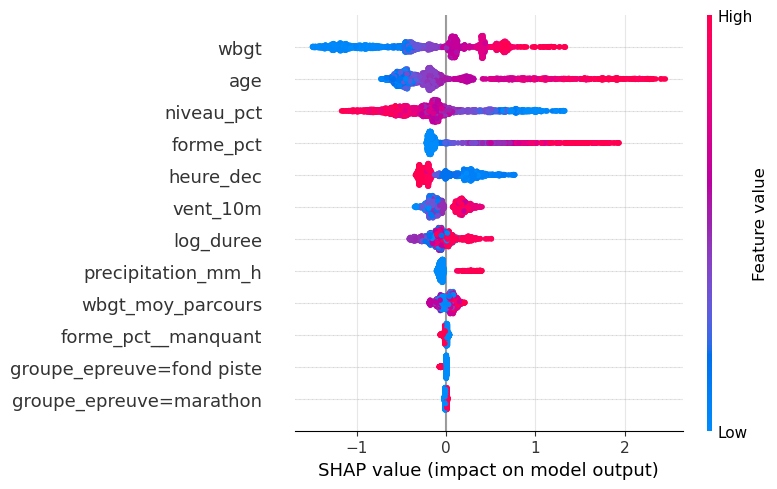

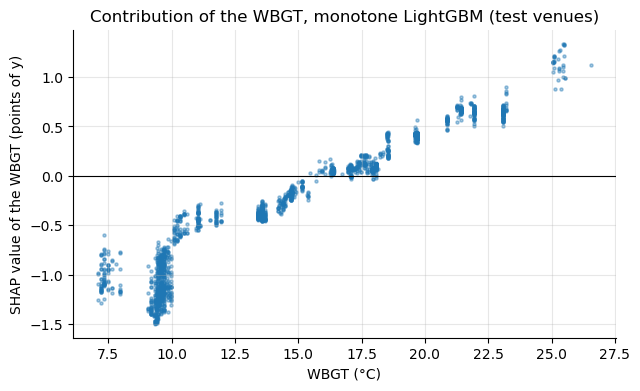

In [73]:
import shap
mod_lgbm = MODELES_2325["monotone LightGBM"]
X_test_lgbm = mod_lgbm.pre_.transform(df_test)
expl = shap.TreeExplainer(mod_lgbm.booster_)
sv = expl.shap_values(X_test_lgbm)
imp = pd.Series(np.abs(sv).mean(axis=0), index=mod_lgbm.pre_.noms_).sort_values(ascending=False)
print("Mean |SHAP| importance (points of y):"); print(imp.head(12).round(4).to_string())
shap.summary_plot(sv, X_test_lgbm, feature_names=mod_lgbm.pre_.noms_, max_display=12, show=False)
plt.gcf().set_size_inches(8, 5); plt.tight_layout(); plt.show()
j = mod_lgbm.pre_.noms_.index("wbgt")
plt.figure(figsize=(7, 4))
plt.scatter(X_test_lgbm[:, j], sv[:, j], s=5, alpha=0.4)
plt.axhline(0, color="k", lw=0.8); plt.xlabel("WBGT (°C)"); plt.ylabel("SHAP value of the WBGT (points of y)")
plt.title("Contribution of the WBGT, monotone LightGBM (test venues)"); plt.show()

**Analysis.**

| variable | mean importance $\lvert\phi_j\rvert$ (points of $y$) | | variable | importance |
|---|---|---|---|---|
| WBGT | **0.549** | | wind | 0.159 |
| age | 0.502 | | expected duration (log) | 0.128 |
| level | 0.390 | | rain | 0.072 |
| form | 0.294 | | mean WBGT of the course | 0.068 |
| time | 0.240 | | missing form, event groups | 0.009 to 0.014 |

**The WBGT is the most important variable of the model.** On the test venues, its contribution is on average
0.55 point of $y$, ahead of age (0.50), level (0.39) and form (0.29). The dependence plot shows an
increasing contribution, in steps, from $-1.4$ points around 9.5 °C to $+1.2$ points around 25 °C. The points form
vertical bands: each band corresponds to a race, whose runners all share the same WBGT. The
contributions are measured relative to the mean prediction $\phi_0$, and not relative to the reference WBGT:
they are negative for races cooler than the average of the training data.

**An apparent paradox with part 5.4.** Removing all the weather variables did not worsen the RMSE
(part 5.4), and yet the WBGT receives the largest contribution here. The two results are compatible. The WBGT
is strongly linked to the event group and to the time (hot track in the evening, cool marathon in the morning): when
it is present, part of the information it carries could also be carried by these variables, and the Shapley value
gives it the credit; when it is absent, time, duration and group take over. The event group
indicators moreover receive almost zero contributions, a sign that their information is already
captured by the WBGT, the time and the duration. **A high SHAP value means neither that a variable is indispensable to
the prediction, nor that it has a causal effect.**

**The direction of the effects** (summary plot, red = high value of the variable):

* **high WBGT, high age, high form** (season's best far from the personal best), **strong wind, rain,
  long duration**: positive contributions, that is, a slower performance relative to the personal best, as
  expected;
* **late time**: negative contributions. Evening track meetings gather athletes who run close
  to their personal best (fast tracks, pacemakers);
* **high level** (athlete slower than the median of their event): negative contributions. The least
  fast athletes run closer to their personal best. Several explanations are possible, such as a less exceptional personal best
  or the selection by the truncation margin, and the model does not allow us to separate them.

### 8.2 Partial dependence and degradation curve

#### Partial dependence

The **partial dependence** of a model $f$ on a variable $v$ (Friedman, 2001) is the function

$$\text{PD}_v(\xi) = \frac1n\sum_{i=1}^n f\big(x_i \text{ with } x_{i,v} = \xi\big):$$

for each value $\xi$, we **impose** $x_{i,v} = \xi$ on all the performances $i$, the other variables keeping
their observed values, and average the predictions. It is the answer to the question: "what would the
model predict, on average over our athletes and races, if variable $v$ were equal to $\xi$ for everyone?".
Unlike the mean of $y$ by WBGT class (part 1.3), which compares different races, the
partial dependence compares the **same** performances under two values of the variable: the composition of the
events, age and level are identical from one value to the other, which neutralizes Simpson's paradox
**within the model**.

#### ICE curves

Before the mean, each performance $i$ has its own curve $\xi \mapsto f(x_i \text{ with } x_{i,v} = \xi)$: it is
an **ICE** curve (*individual conditional expectation*, Goldstein *et al.*, 2015). The partial dependence is the
mean of the ICE curves. Their dispersion is informative about **interactions**: if all ICE curves are
parallel (identical up to a constant), the effect of $v$ is the same for all performances; if they
diverge, the effect of $v$ depends on the other variables. To compare shapes, each curve is centered on its
value at the reference.

#### The degradation curve

The degradation curve is the partial dependence on the WBGT, centered on the reference WBGT:

$$\Delta(W) = \text{PD}_{\text{WBGT}}(W) - \text{PD}_{\text{WBGT}}(W_{\text{ref}}) \qquad (\text{in points of } y \approx \text{ % of speed}).$$

This is exactly the quantity the tool needs (part 0.4): the mean degradation of performance
when the WBGT goes from 15 °C to $W$, for an unchanged athlete profile. For a linear model of degree 1 in WBGT, without
interaction, all ICE curves are parallel straight lines and $\Delta(W) = \beta_W\,(W - W_{\text{ref}})$: the
curve is a line with slope $\beta_W$, and its value at 25 °C is the +10 °C effect of part 3.4 (the test
below checks it). If the model contains the Mundlak term $\bar W_g$, it is **not** modified: we measure
the effect of a change of WBGT on a given course, that is, the within-course effect (part 4.2).

**Implementation.** For a grid of $n_\xi$ values, $n_\xi$ copies of the table are stacked, each with an
imposed value, and the whole is predicted in a single call: this is much faster than $n_\xi$ successive calls. The
reference value is added to the grid for the centering.

#### Two reading precautions

* **Extrapolation.** At the ends of the grid, few performances were observed: the curve rests there on
  very few races, or simply extends the shape of the model. The figures shade the extreme 2.5% of the data
  on each side.
* **Correlated variables.** Imposing a WBGT of 27 °C on a winter cross-country performance, or on a race
  run at 11 p.m., creates combinations that do not exist in the data. Partial dependence then evaluates the
  model where it learned nothing. It remains a description of the model; its interpretation as a causal effect
  rests on the controls included and on the absence of an omitted confounding factor (parts 1.4 and 4.2).

The figure compares the degradation curves of six models of part 7, and shows the ICE curves of the
monotone LightGBM for 60 performances drawn at random.

In [74]:
def dependance_partielle(modele, df, variable, grille, retour_ice=False):
    '''PD of modele.predict in `variable` over `grille`. Output: (G,); if retour_ice, also (n, G).'''
    grille = np.asarray(grille, dtype=float)
    bloc = pd.concat([df] * len(grille), ignore_index=True)
    bloc[variable] = np.repeat(grille, len(df))
    p = np.asarray(modele.predict(bloc), dtype=float).reshape(len(grille), len(df))
    return (p.mean(axis=1), p.T) if retour_ice else p.mean(axis=1)


def courbe_degradation(modele, df, grille, ref=WBGT_REF, variable="wbgt"):
    '''Delta(w) = PD(w) - PD(ref), in points of y. Output: (G,).'''
    pd_g = dependance_partielle(modele, df, variable, np.append(grille, ref))
    return pd_g[:-1] - pd_g[-1]

In [75]:
#test
_m = PipelineLineaire(RegressionMC(), degre=1).fit(df_train)
_g = np.array([10.0, 20.0, 30.0])
_pdp, _ice = dependance_partielle(_m, df_train.head(30), "wbgt", _g, retour_ice=True)
assert _ice.shape == (30, 3) and np.allclose(_ice.mean(axis=0), _pdp)
_d = courbe_degradation(_m, df_train.head(30), _g)
assert np.allclose(_d, effet_wbgt(_m, df_train.head(30), WBGT_REF, WBGT_REF + 10) * (_g - WBGT_REF) / 10)
assert np.isclose(courbe_degradation(_m, df_train.head(30), [WBGT_REF])[0], 0)
print("partial dependence: OK")

partial dependence: OK


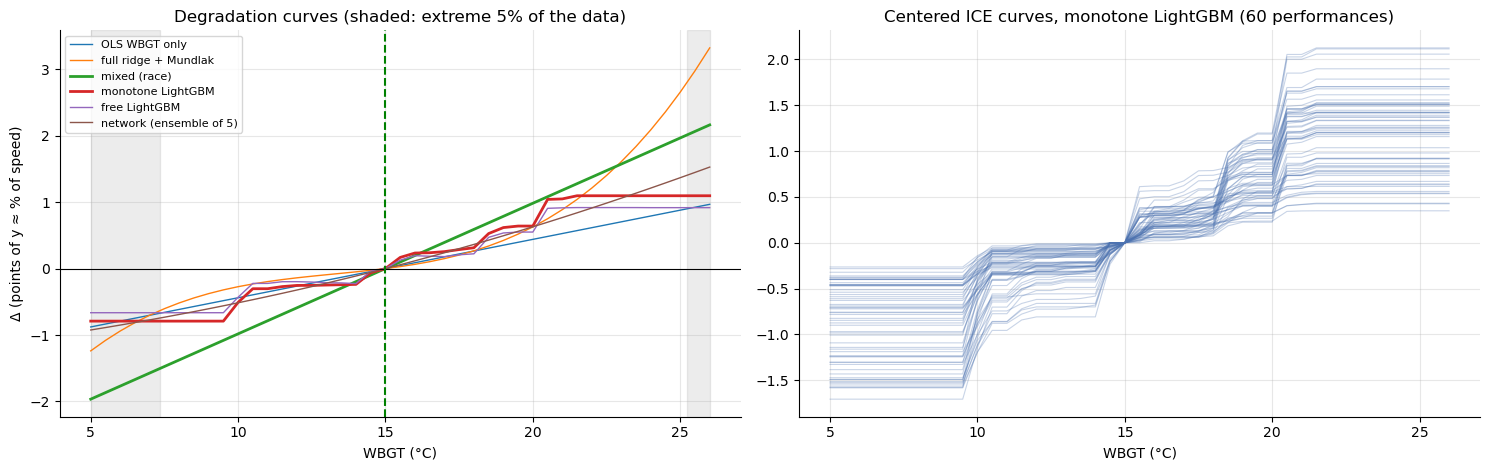

In [76]:
GRILLE = np.arange(np.floor(df["wbgt"].quantile(0.005)), np.ceil(df["wbgt"].quantile(0.995)) + 0.5, 0.5)
q_lo, q_hi = df["wbgt"].quantile([0.025, 0.975])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for nom in ["OLS WBGT only", "full ridge + Mundlak", "mixed (race)", "monotone LightGBM", "free LightGBM",
            "network (ensemble of 5)"]:
    axes[0].plot(GRILLE, courbe_degradation(MODELES_2325[nom], df_train, GRILLE), label=nom, lw=2 if "mixed" in nom or "monotone" in nom else 1)
axes[0].axvspan(GRILLE[0], q_lo, color="gray", alpha=0.15); axes[0].axvspan(q_hi, GRILLE[-1], color="gray", alpha=0.15)
axes[0].axhline(0, color="k", lw=0.8); axes[0].axvline(WBGT_REF, color="g", ls="--")
axes[0].set_xlabel("WBGT (°C)"); axes[0].set_ylabel("Δ (points of y ≈ % of speed)"); axes[0].legend(fontsize=8)
axes[0].set_title("Degradation curves (shaded: extreme 5% of the data)")
_, ice = dependance_partielle(MODELES_2325["monotone LightGBM"], df_train.sample(60, random_state=SEED), "wbgt", GRILLE, retour_ice=True)
axes[1].plot(GRILLE, (ice - ice[:, [np.argmin(np.abs(GRILLE - WBGT_REF))]]).T, color="#4C72B0", alpha=0.3, lw=0.8)
axes[1].set_xlabel("WBGT (°C)"); axes[1].set_title("Centered ICE curves, monotone LightGBM (60 performances)")
plt.tight_layout(); plt.show()

**Analysis.** The degradation curves of the six models (means over the training performances,
all events together) all have the same direction: **hotter, slower**. Their amplitude and shape differ
markedly beyond 20 °C. The following values are read from the figure:

| model | $\Delta$ at 25 °C (about) | shape of the curve |
|---|---|---|
| OLS WBGT only | +0.9 | straight line, without control of confounding factors |
| monotone and free LightGBM | +1.1 | stepwise, **constant** beyond about 21 °C |
| network (ensemble of 5) | +1.4 | smooth, almost linear |
| mixed model (race) | +1.9 | straight line (degree 1) |
| full ridge + Mundlak | +2.6 | convex curve (degree 3 with interactions) |

* **Trees level off.** Beyond the last threshold learned on the WBGT (around 21 °C), LightGBM predicts the same
  thing whatever the WBGT: for lack of enough hot races, it has nothing to split on higher up. It
  cannot extrapolate (part 5.1).
* **The degree-3 polynomial shoots up.** The curvature of ridge is carried by the few hottest races. It
  exceeds 3 points in the shaded area, where data are missing: this is the extrapolation risk flagged in parts 3
  and 4.3.
* **The mixed model and the network** give regular curves, between these two extremes.
* **On the cool side**, all models predict a faster performance than at 15 °C. The gap between them (from $-0.8$ to
  $-1.9$ points at 5 °C) widens in the shaded area: below 7.5 °C, data are scarce.

These curves mix all events: the model of the tool (part 8.4) separates them.

**The ICE curves** of the monotone LightGBM are far from parallel: at 25 °C, the degradation ranges from about +0.4 to
+2.1 points depending on the performance. The effect of heat therefore depends on the other variables (event, duration, time):
the model learned **interactions**, which justifies estimating one effect per event group. The steps,
located around 10, 14.5, 18.5 and 20.5 °C, are the split thresholds of the trees, shared by all performances.

### 8.3 Uncertainty on the curve: venue bootstrap

#### Why retrain on all venues

For the tool, the models are now retrained on **all the venues**, training and test together. The
test set has already served for the evaluation (part 7), and there is no longer any choice to make by looking at it: using it to estimate the
effect creates no leakage, and 21 more venues improve precision.

#### Where the uncertainty comes from

The uncertainty on $\Delta(W)$ comes mainly from the **small number of venues and races**: each race only
brings one weather situation (part 1.2), and hot races are rare. As in part 7.2, we estimate it
with a **cluster bootstrap** of the venues, but this time **retraining** the model on each replicate:

1. draw, with replacement, as many venues as there are in the data;
2. pool all the performances of the venues drawn, and retrain the model on this sample;
3. compute the degradation curve of the retrained model on a fixed reference population;
4. repeat $B$ times, then take, **point by point** on the grid, the 2.5% and 97.5% quantiles of the $B$ curves.

This gives a **pointwise** 95% confidence band: for each WBGT value, the interval contains the
value of the true curve with a probability of about 95%. It is not a **simultaneous** band: the probability
that the whole curve stays within the band is lower. This bootstrap measures the uncertainty due to the sample
of venues, including the variability of the estimate of all the coefficients, but not that due to a wrong choice
of model shape.

#### Two precautions

* **A fixed reference population.** The curve is always computed on the same set of performances
  (`df_ref`), and not on the bootstrap sample, whose composition changes at each replicate: otherwise, the
  measured variability would mix that of the model and that of the population over which we average.
* **Renaming the copies of a venue drawn several times.** If a venue is drawn twice, its rows appear
  twice. Without renaming, its races would become races of double size, made of pairs of
  identical rows. A mixed model would see an artificially small within-race variance and could estimate
  $\gamma \to \infty$, with aberrant effects. Each copy therefore receives race, meeting,
  course and venue identifiers suffixed by its number (`#k`): it becomes a distinct venue, which it is in the logic
  of the bootstrap, where each draw represents a new venue of the population.

The test checks that the curve is 0 at the reference in all replicates, that it varies from one replicate to
another, and, with a "spy" model, that each copy did receive distinct identifiers.

In [77]:
IDENTIFIANTS = ["id_course", "id_meeting", "id_parcours", "id_lieu"]


def bootstrap_courbes(fabrique, df, df_ref, grille, B=100, groupe="id_lieu", seed=SEED, garder_modeles=False):
    '''Cluster bootstrap of the degradation curve. Output: curves (B, G) [, list of models].'''
    rng = np.random.default_rng(seed)
    uniques = df[groupe].unique()
    positions = df.groupby(groupe).indices
    courbes, modeles = [], []
    for _ in range(B):
        tirage = rng.choice(uniques, size=len(uniques), replace=True)
        blocs = [positions[g] for g in tirage]
        df_b = df.iloc[np.concatenate(blocs)].copy()
        copie = np.repeat(np.arange(len(blocs)), [len(i) for i in blocs]).astype(str)
        for col in IDENTIFIANTS:
            df_b[col] = df_b[col].astype(str).to_numpy() + "#" + copie
        m = fabrique().fit(df_b)
        courbes.append(courbe_degradation(m, df_ref, grille))
        if garder_modeles:
            modeles.append(m)
    courbes = np.array(courbes)
    return (courbes, modeles) if garder_modeles else courbes

In [78]:
#test
_c = bootstrap_courbes(lambda: PipelineLineaire(RegressionMC(), degre=1), df_train, df_train.head(50), np.array([WBGT_REF, 22.0]), B=5)
assert _c.shape == (5, 2) and np.allclose(_c[:, 0], 0) and np.std(_c[:, 1]) > 0
class _Espion:                       # checks the renaming of the copies
    def fit(self, d):
        assert d["id_course"].str.contains("#").all() and d.groupby("id_course")["id_lieu"].nunique().max() == 1
        return self
    def predict(self, d):
        return np.zeros(len(d))
_ = bootstrap_courbes(_Espion, df_train.head(400), df_train.head(10), np.array([WBGT_REF]), B=2)
print("bootstrap_courbes: OK")

bootstrap_courbes: OK


### 8.4 The model retained for the tool

#### The requirements

For the tool, what matters is the **effect** of the conditions: estimated with as little bias as possible, with an
honest uncertainty, readable by event, and without fanciful extrapolation. Since part 7 showed that the
families of models are on a par in prediction, the choice is made on these criteria.

#### The model

We retain a linear model with a **random race intercept** (part 4), whose terms are chosen
*a priori* from physiology and the literature. For performance $j$ of race $g$:

$$y_{gj} = u_g + \sum_e \mathbb 1_e\,P_e(W_{gj}) + \beta_{W,\text{lev}}\,\frac{\text{level}_{gj}}{10}\,(W_{gj} - W_{\text{ref}})
  + \sum_e \mathbb 1_e\,\beta_{\text{alt},e}\,\text{alt}_g + \beta_{\text{wind}}\,\text{wind}_{gj} + \beta_{\text{rain}}\,\text{rain}_{gj}
  + x_{gj}^\top\beta + \varepsilon_{gj} .$$

* $u_g \sim \mathcal N(0, \tau^2)$ is the random effect of race $g$, $\varepsilon_{gj} \sim \mathcal N(0, \sigma^2)$
  the individual error (part 4.1).
* $P_e$ is a **polynomial of the WBGT specific to each event group** $e$, and $\mathbb 1_e$ equals 1 for the
  performances of group $e$: the effect of heat can grow with the duration of the effort (part 0.2). The
  polynomials are written in the basis $\psi(W)$ of part 3.3, which vanishes at $W_{\text{ref}}$. Their degree $D$ is chosen
  by cross-validation by venue, among 1, 2 and 3.
* The term $\beta_{W,\text{lev}}$ multiplies the WBGT gap to the reference by the athlete's level (in tens of
  points of `niveau_pct`): it tests the finding of Ely *et al.* (2007) that slower runners are more
  affected by heat. If it is positive, a runner slower than the median (positive level) loses more.
* $\text{alt}_g$ is the altitude above 500 m (`alt_km`, part 2.3), with a slope $\beta_{\text{alt},e}$ specific to
  each group (hypoxia). The tracks of the data set are all below 300 m: for track middle and long
  distance, the column is identically zero and so is its coefficient (minimum-norm solution, part 3.2).
  The tool will therefore refuse any altitude higher than the one observed for the group.
* $x_{gj}^\top\beta$ gathers the controls: age, form, time, expected duration, level, sex, event group.

The Mundlak term is not included (`MUNDLAK_OUTIL = False`): with an effect specific to each group, a
course mean per group would be needed, and part 4.2 showed that the within-course effect is not weaker than the
effect estimated without distinction. The reference conditions of the tool include a wind of 2 m/s at 10 m
(`VENT_REF`), a light breeze.

#### The estimation steps

1. **Choice of the degree** $D$ by the cross-validated RMSE by venue, on the training data.
2. **Estimation on all venues**, and computation of the profile of the REML likelihood in $\ln\gamma$ (see below).
3. **Venue bootstrap**: 300 replicates for the mixed model, and 50 for the monotone LightGBM, kept as a point
   of comparison (each replicate of the boosting is more expensive).
4. **Effects by event group**: the degradation $\Delta(W)$ is computed separately on the reference
   performances of each group (up to 250 per group), at 20 °C and at 25 °C, with the bootstrap interval. The computation
   flags the values located beyond the 99th percentile of the WBGT observed for the group, which are extrapolations.
5. **Other effects**: wind (+2 m/s), rain (1 mm/h), gap between slow and fast runners in the marathon (level
   $+10$ against $-10$), altitude (1,500 m), each with its bootstrap interval.

#### A technical point: the REML likelihood can be bimodal

The profile restricted log-likelihood $\ell_R(\gamma)$ (part 4.1) does not always have a single maximum. Besides the
interior maximum, it can rise again toward the boundary $\gamma \to \infty$, which corresponds to race fixed effects.
The main cause is **heteroscedasticity**: the standard deviation of $y$ within a race is about 1.9 points
in middle distance and 3.6 in the marathon, whereas the model assumes a common $\sigma^2$. By treating each race as
a fixed effect, the model absorbs part of this heterogeneity into the race means, which the
likelihood may reward. If, in a bootstrap replicate, the boundary wins, the race-level variables
(WBGT, altitude, event group) are only identified by the tiny variation that remains within
races, and their effects become aberrant.

**The fix: fixing $\gamma$.** We fix $\gamma$ at its value estimated on the full sample, $\hat\gamma$, in
all the replicates. Each replicate then computes a generalized least squares estimator with a **working**
covariance matrix $V(\hat\gamma)$ fixed:

$$\hat\beta = (X^\top V^{-1} X)^{-1} X^\top V^{-1} y .$$

This estimator remains **unbiased** even if $V(\hat\gamma)$ is not the true covariance: since
$\mathbb{E}[y] = X\beta$, we have $\mathbb{E}[\hat\beta] = (X^\top V^{-1} X)^{-1} X^\top V^{-1} X\beta = \beta$ whatever
the matrix $V$ used. An imperfect matrix only costs **precision**. Its variance, on the other hand, is
no longer the one given by the model formula; if the true covariance is $\Sigma$, it is

$$\text{Var}(\hat\beta) = (X^\top V^{-1} X)^{-1}\,X^\top V^{-1}\,\Sigma\,V^{-1} X\,(X^\top V^{-1} X)^{-1},$$

the so-called "**sandwich**" variance, used by generalized estimating equations (GEE). The venue bootstrap
estimates this variance without having to know $\Sigma$: it is an uncertainty that is **robust** to a misspecified
covariance. A more complete alternative would have been a $\sigma^2$ specific to each event group. The
likelihood profile plotted below makes it possible to check that, on the full sample, the interior maximum wins
clearly.

#### Why not the monotone boosting or the network?

Their predictive performances are of the same order (part 7), but their heat curves are poorly suited to
the tool:

* the curve of the **monotone boosting** is **constrained** to be increasing: if the true effect is zero, it is biased
  upward, and its bootstrap interval cannot contain negative values above the reference. It
  is also stepwise, and **levels off** beyond the last learned thresholds, for lack of hot races;
* the curve of the **network** is smooth, but it does not decompose by event, and its uncertainty would require
  retraining ensembles of networks hundreds of times;
* the **mixed linear model** gives a smooth curve, specific to each event, each term of which has an
  interpretation and a confidence interval.

In [79]:
MUNDLAK_OUTIL = False
VENT_REF = 2.0     # m/s at 10 m: light breeze, reference conditions for the tool


class PipelineOutil(PipelineMixte):
    '''Mixed model (random race intercept): WBGT polynomial by event group,
    WBGT x level, altitude x group, wind, rain, controls.'''

    def __init__(self, degre=None, mundlak=MUNDLAK_OUTIL, log_gamma=None):
        degre = DEGRE_OUTIL if degre is None else degre               # DEGRE_OUTIL: chosen below
        bornes = (-10.0, 6.0) if log_gamma is None else (log_gamma - 1e-9, log_gamma + 1e-9)   # gamma fixed if given
        super().__init__(degre=degre, interactions=False, num=["age", "forme_pct", "heure_dec", "log_duree",
                                                               "niveau_pct", "vent_10m", "precipitation_mm_h"],
                         cat=CAT_CONTEXTE, mundlak=mundlak, groupe="id_course", bornes_log_gamma=bornes)

    def _design(self, df):
        d = super()._design(df)
        B = base_polynomiale(df["wbgt"], self.degre)
        for g in GROUPES:
            ind = (df["groupe_epreuve"] == g).to_numpy()
            if g != GROUPES[0]:
                for k in range(self.degre):
                    d[f"wbgt_p{k + 1}_x_{g}"] = B[:, k] * ind
            d[f"alt_x_{g}"] = df["alt_km"].to_numpy() * ind     # one altitude slope per group
        d["wbgt_x_niveau"] = (df["wbgt"].to_numpy() - WBGT_REF) * df["niveau_pct"].to_numpy() / 10.0
        return d

CV RMSE (venue folds) of the tool's model by degree: {1: np.float64(3.024), 2: np.float64(3.0282), 3: np.float64(3.0422)} -> DEGRE_OUTIL = 1 (2 s)


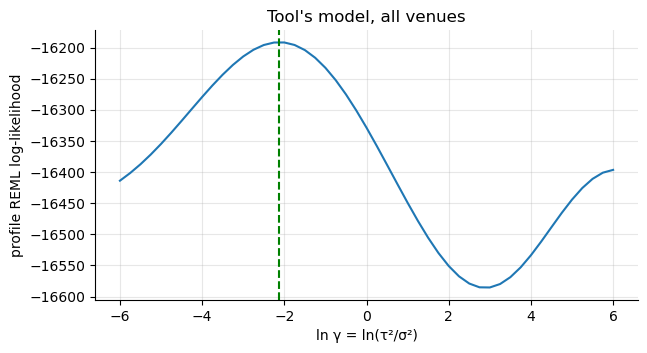

estimated ln gamma = -2.12 (tau²/sigma² = 0.120); log-likelihood: -16191.8 at the interior maximum, -16396.4 at ln gamma = 6


mixed model (tool): 300 replicates (42 s)


monotone LightGBM: 50 replicates (62 s)


Mixed model (all venues): race tau² = 0.945, sigma² = 7.873

Effect of a WBGT increase from 15 °C (points of y), 95% CI from the venue bootstrap:


 WBGT = 20 °C
  track middle distance +0.018  [-0.430, +0.346]
  track long distance   +0.411  [-0.010, +1.083]
  short road            +0.761  [+0.239, +1.254]
  half marathon         +0.887  [+0.465, +1.339]
  marathon              +1.572  [+1.162, +2.062]


 WBGT = 25 °C
  track middle distance +0.035  [-0.860, +0.693]
  track long distance   +0.823  [-0.020, +2.166]
  short road            +1.522  [+0.477, +2.507]
  half marathon         +1.775  [+0.930, +2.678]   (outside the group's range: extrapolation)
  marathon              +3.144  [+2.324, +4.124]


In [80]:
t0 = time.time()
cv_outil = {D: cv_rmse(lambda D=D: PipelineOutil(degre=D))[0] for D in [1, 2, 3]}
DEGRE_OUTIL = min(cv_outil, key=cv_outil.get)
print("CV RMSE (venue folds) of the tool's model by degree:", {D: round(v, 4) for D, v in cv_outil.items()},
      f"-> DEGRE_OUTIL = {DEGRE_OUTIL} ({time.time() - t0:.0f} s)")

df_tout = df.copy()                      # all venues, for the final models
MODELE_COMPLET = PipelineOutil().fit(df_tout)
LOG_GAMMA = float(np.log(MODELE_COMPLET.mm_.gamma_))
# profile of the REML log-likelihood in ln(gamma)
_d = MODELE_COMPLET._design(df_tout)
_X = np.column_stack([np.ones(len(_d)), MODELE_COMPLET.pre_.transform(_d)])[:, MODELE_COMPLET.mm_.garde_]
_u, _codes = np.unique(df_tout["id_course"].to_numpy(), return_inverse=True)
_n = np.bincount(_codes).astype(float)
grille_lg = np.linspace(-6, 6, 49)
profil = [MODELE_COMPLET.mm_.log_vraisemblance(np.exp(t), _X, df_tout[CIBLE].to_numpy(), _codes, _n)[0] for t in grille_lg]
plt.figure(figsize=(7, 3.5)); plt.plot(grille_lg, profil); plt.axvline(LOG_GAMMA, color="g", ls="--")
plt.xlabel("ln γ = ln(τ²/σ²)"); plt.ylabel("profile REML log-likelihood"); plt.title("Tool's model, all venues")
plt.show()
print(f"estimated ln gamma = {LOG_GAMMA:.2f} (tau²/sigma² = {np.exp(LOG_GAMMA):.3f}); "
      f"log-likelihood: {max(profil):.1f} at the interior maximum, {profil[-1]:.1f} at ln gamma = 6")

t0 = time.time()
FAB_FINAL = {"mixed model (tool)": lambda: PipelineOutil(log_gamma=LOG_GAMMA),
             "monotone LightGBM": FABRIQUES["monotone LightGBM"]}
B_FINAL = {"mixed model (tool)": 300, "monotone LightGBM": 50}
df_ref_courbe = pd.concat([g.sample(min(250, len(g)), random_state=SEED) for _, g in df_tout.groupby("groupe_epreuve")])
BOOT = {}
for nom, fab in FAB_FINAL.items():
    BOOT[nom] = bootstrap_courbes(fab, df_tout, df_ref_courbe, GRILLE, B=B_FINAL[nom], groupe="id_lieu", garder_modeles=True)
    print(f"{nom}: {B_FINAL[nom]} replicates ({time.time() - t0:.0f} s)")
MODELES_FINAUX = {nom: fab().fit(df_tout) for nom, fab in FAB_FINAL.items()}
mm = MODELES_FINAUX["mixed model (tool)"].mm_
print(f"Mixed model (all venues): race tau² = {mm.tau2_:.3f}, sigma² = {mm.sigma2_:.3f}")

def effet_par_groupe(modele, w=WBGT_REF + 10):
    return {g: courbe_degradation(modele, df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g], [w])[0] for g in GROUPES}

PLAGE_GROUPE = df_tout.groupby("groupe_epreuve")["wbgt"].quantile([0.01, 0.99]).unstack()
print(f"\nEffect of a WBGT increase from {WBGT_REF:g} °C (points of y), 95% CI from the venue bootstrap:")
for w in [WBGT_REF + 5, WBGT_REF + 10]:
    est = effet_par_groupe(MODELES_FINAUX["mixed model (tool)"], w)
    reps = pd.DataFrame([effet_par_groupe(m, w) for m in BOOT["mixed model (tool)"][1]])
    print(f" WBGT = {w:g} °C")
    for g in GROUPES:
        hors = "   (outside the group's range: extrapolation)" if w > PLAGE_GROUPE.loc[g, 0.99] else ""
        print(f"  {NOMS_EN[g]:21s} {est[g]:+.3f}  [{reps[g].quantile(0.025):+.3f}, {reps[g].quantile(0.975):+.3f}]{hors}")

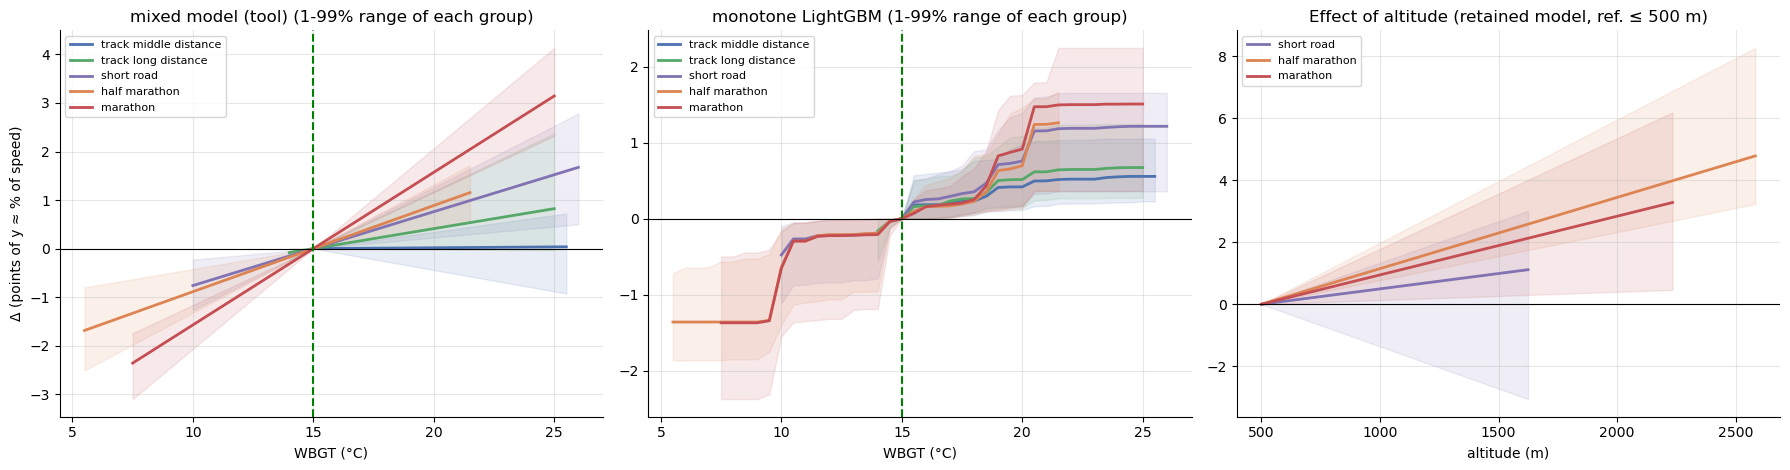

Other effects of the retained model (points of y, 95% CI from the venue bootstrap):


  wind +2 m/s (2 -> 4 m/s at 10 m)     : +0.356  [+0.082, +0.629]


  rain 1 mm/h                           : +0.340  [-0.529, +2.003]


  marathon, +10 °C: slow - fast         : -0.174  [-1.240, +0.855]


  altitude 1,500 m, short road           : +0.990  [-2.952, +2.798]


  altitude 1,500 m, half marathon        : +2.297  [+1.552, +4.480]


  altitude 1,500 m, marathon             : +1.893  [+0.045, +3.652]


In [81]:
couleurs = dict(zip(GROUPES, ["#4C72B0", "#55A868", "#8172B2", "#DD8452", "#C44E52"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, nom in zip(axes[:2], FAB_FINAL):
    courbes_b, modeles_b = BOOT[nom]
    for g in GROUPES:
        sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
        gg = GRILLE[(GRILLE >= min(PLAGE_GROUPE.loc[g, 0.01], WBGT_REF)) & (GRILLE <= PLAGE_GROUPE.loc[g, 0.99])]
        cb = np.array([courbe_degradation(m, sous, gg) for m in modeles_b[:200]])
        ax.plot(gg, courbe_degradation(MODELES_FINAUX[nom], sous, gg), color=couleurs[g], lw=2, label=NOMS_EN[g])
        ax.fill_between(gg, np.quantile(cb, 0.025, axis=0), np.quantile(cb, 0.975, axis=0), color=couleurs[g], alpha=0.12)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(WBGT_REF, color="g", ls="--"); ax.set_title(nom + " (1-99% range of each group)")
    ax.legend(fontsize=8); ax.set_xlabel("WBGT (°C)")
axes[0].set_ylabel("Δ (points of y ≈ % of speed)")
mod_o = MODELES_FINAUX["mixed model (tool)"]
for g in ["route courte", "semi-marathon", "marathon"]:      # the tracks are all below 300 m
    sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
    ga = np.linspace(0, df_tout.loc[df_tout["groupe_epreuve"] == g, "alt_km"].max(), 20)
    ca = np.array([courbe_degradation(m, sous, ga, ref=0.0, variable="alt_km") for m in BOOT["mixed model (tool)"][1][:200]])
    axes[2].plot(500 + 1000 * ga, courbe_degradation(mod_o, sous, ga, ref=0.0, variable="alt_km"), color=couleurs[g], lw=2, label=NOMS_EN[g])
    axes[2].fill_between(500 + 1000 * ga, np.quantile(ca, 0.025, axis=0), np.quantile(ca, 0.975, axis=0), color=couleurs[g], alpha=0.12)
axes[2].axhline(0, color="k", lw=0.8); axes[2].set_xlabel("altitude (m)"); axes[2].legend(fontsize=8)
axes[2].set_title("Effect of altitude (retained model, ref. ≤ 500 m)")
plt.tight_layout(); plt.show()
def resume(fonction):
    e = fonction(MODELES_FINAUX["mixed model (tool)"])
    b = np.array([fonction(m) for m in BOOT["mixed model (tool)"][1]])
    return f"{e:+.3f}  [{np.quantile(b, 0.025):+.3f}, {np.quantile(b, 0.975):+.3f}]"

print("Other effects of the retained model (points of y, 95% CI from the venue bootstrap):")
print("  wind +2 m/s (2 -> 4 m/s at 10 m)     :", resume(lambda m: courbe_degradation(m, df_ref_courbe, [VENT_REF + 2], ref=VENT_REF, variable="vent_10m")[0]))
print("  rain 1 mm/h                           :", resume(lambda m: courbe_degradation(m, df_ref_courbe, [1.0], ref=0.0, variable="precipitation_mm_h")[0]))
mara = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == "marathon"]
def ecart_niveau(m):   # Ely et al.: effect of +10 °C for a runner 10% slower minus for a runner 10% faster
    lent, rapide = mara.assign(niveau_pct=10.0), mara.assign(niveau_pct=-10.0)
    return courbe_degradation(m, lent, [WBGT_REF + 10])[0] - courbe_degradation(m, rapide, [WBGT_REF + 10])[0]
print("  marathon, +10 °C: slow - fast         :", resume(ecart_niveau))
for g in ["route courte", "semi-marathon", "marathon"]:
    sous = df_ref_courbe[df_ref_courbe["groupe_epreuve"] == g]
    print(f"  altitude 1,500 m, {NOMS_EN[g]:14s}       :", resume(lambda m: courbe_degradation(m, sous, [1.0], ref=0.0, variable="alt_km")[0]))

**Analysis.**

**Choice of the degree.** Cross-validation by venue gives an RMSE of 3.024 for a linear effect of the WBGT in each
group, 3.028 with degree 2 and 3.042 with degree 3. Degree 1 is retained: the data do not allow a
curvature specific to each event group to be estimated. Since the gaps are much smaller than the standard error across folds (part 2.5),
the one-standard-error rule would have made the same choice.

**The likelihood profile confirms the bimodality.** The interior maximum is reached at $\ln\hat\gamma = -2.12$,
that is, $\hat\gamma = 0.120$, with $\hat\tau^2 = 0.945$ and $\hat\sigma^2 = 7.873$: the race explains 11% of the
residual variance, as in part 4.2. The likelihood then decreases to about $-16{,}585$ around
$\ln\gamma \approx 2.8$, then **rises again** to $-16{,}396$ at the boundary $\ln\gamma = 6$: this is the second mode, on the
side of race fixed effects. On the full sample, the interior maximum ($-16{,}192$) wins by more than 200
log-likelihood units: fixing $\gamma$ at this value in the bootstrap is unambiguous.

**Orders of magnitude.** Degradation $\Delta$ from a WBGT of 15 °C, in points of $y$ (≈ % of speed), with the 95% CI
from the venue bootstrap (300 replicates):

| event group | WBGT 20 °C | WBGT 25 °C |
|---|---|---|
| track middle distance | $+0.02$ [$-0.43$, $+0.35$] | $+0.04$ [$-0.86$, $+0.69$] |
| track long distance | $+0.41$ [$-0.01$, $+1.08$] | $+0.82$ [$-0.02$, $+2.17$] |
| short road | $+0.76$ [$+0.24$, $+1.25$] | $+1.52$ [$+0.48$, $+2.51$] |
| half marathon | $+0.89$ [$+0.47$, $+1.34$] | $+1.78$ [$+0.93$, $+2.68$] (extrapolated) |
| marathon | $+1.57$ [$+1.16$, $+2.06$] | $+3.14$ [$+2.32$, $+4.12$] |

**The effect grows with the duration of the effort**, as physiology predicts: the stored heat accumulates and
cardiovascular drift sets in as the effort goes on (part 0.2).

* It is **zero in middle distance**: an 800 m or a 1,500 m is too short for thermoregulation to limit
  performance. The interval, centered on 0, rules out an effect larger than 0.7 point at 25 °C.
* It is about **0.8 point in track long distance**, with an interval that touches 0, then about **1.5 points on short
  road races** (5 and 10 km).
* It reaches about **3 points in the marathon** between 15 and 25 °C, that is, about 4 min 45 s over 2:30. This is the order of
  magnitude of Ely *et al.* (2007).
* The half marathon at 25 °C is an **extrapolation**: no race was observed above 22 °C.

The effects being linear, the effect at 25 °C is twice that at 20 °C. The class means of part 1.3
suggested an acceleration beyond 20 °C in the marathon: the linear model may slightly underestimate the effect around
25 °C and overestimate it around 18-20 °C. Weighted by the sizes of the groups, the +10 °C effect is about 1.7 points
($\frac{1}{10{,}398}\sum_e n_e\,\Delta_e(25)$, with the sizes of part 1.1). This is slightly less than the estimates of
part 4.2 (1.9 to 2.4 points with random effects, the Mundlak term and fixed effects), obtained on the
training venues only and with an effect common to all events, but of the same order of magnitude.

**The other terms.**

| effect | estimate [95% CI] (points of $y$) |
|---|---|
| wind +2 m/s (from 2 to 4 m/s at 10 m), at equal WBGT | $+0.36$ [$+0.08$, $+0.63$] |
| rain 1 mm/h | $+0.34$ [$-0.53$, $+2.00$] |
| marathon, +10 °C: slow runner (level $+10$) minus fast runner ($-10$) | $-0.17$ [$-1.24$, $+0.86$] |
| altitude 1,500 m, short road | $+0.99$ [$-2.95$, $+2.80$] |
| altitude 1,500 m, half marathon | $+2.30$ [$+1.55$, $+4.48$] |
| altitude 1,500 m, marathon | $+1.89$ [$+0.05$, $+3.65$] |

* **Wind** costs 0.36 point for +2 m/s, at equal WBGT. Its cooling effect already goes through the WBGT; what
  remains is the mechanical effect, the headwind not being compensated by the tailwind.
* **Rain** is too rare (part 1.2) to conclude.
* The gap between slow and fast runners in the marathon predicted by Ely *et al.* is **not detected**: the data
  set only contains good runners, over a narrow range of levels.
* **Altitude** costs, at 1,500 m, about 1.9 points in the marathon and 2.3 in the half marathon; on short road races it
  remains undetermined. These effects rest on 3 to 6 venues per group, hence the width of the intervals, and may
  also reflect the specific courses of these cities. The figure shows that altitude, observed up to about 2,600 m,
  is only estimated on the road.

**Comparison with the monotone LightGBM.** Boosting gives the same ranking of events and close values
up to 20 °C, but it **levels off** beyond: about +1.5 points in the marathon at 25 °C, against 3.1 for the mixed model.
Its trees are constant beyond the last learned thresholds, for lack of hot races. The monotonicity constraint has
another effect, visible in **middle distance**: its curve cannot fall below 0 above 15 °C, and it rises to
about +0.5 point with an interval that excludes 0, whereas the mixed model finds a zero effect. This is the upward
bias described above: when the true effect is zero, a curve constrained to rise can only overestimate it. The two
models agree on the cool side: in the marathon, running at 7-8 °C rather than at 15 °C saves 1.4 to 2.4 points.

## Part 9 — Quantifying prediction uncertainty

#### Two uncertainties not to be confused

* The **confidence interval** (CI) concerns a **parameter** or a mean effect, here the degradation curve
  $\Delta(W)$ (part 8). It reflects the imprecision due to the finite size of the sample: with more venues and
  races, it would shrink to zero.
* The **prediction interval** (PI) $\hat I(x) = [\hat q_{\text{low}}(x),\ \hat q_{\text{high}}(x)]$ concerns a
  **future observation**: it must contain an athlete's performance $y$ with probability $1 - \alpha$. Even with
  a perfect model, known without error, it remains as wide as the individual noise (form on the day, tactics,
  age of the personal best): it does not shrink with more data.

This part builds prediction intervals, with $\alpha = 0.1$ (target coverage: 90%).

### 9.1 Quantile regression and *pinball* loss

#### The quantile as a minimizer

The mean minimizes the squared loss, the median the absolute loss (part 2.2). More generally, the quantile
of order $\alpha$ of a variable $Y$ (the value $q$ such that $\mathbb{P}(Y \leq q) = \alpha$) minimizes the expectation of
the ***pinball* loss**:

$$\rho_\alpha(y, q) = \max\big(\alpha\,(y - q),\ (\alpha - 1)(y - q)\big) =
\begin{cases} \alpha\,(y - q) & \text{if } y \geq q \ \ (\text{prediction too low}), \\ (1 - \alpha)\,(q - y) & \text{if } y < q \ \ (\text{prediction too high}). \end{cases}$$

**Proof.** For a variable $Y$ with continuous cumulative distribution function $F$,

$$\mathbb{E}[\rho_\alpha(Y, q)] = \alpha\int_{q}^{+\infty}(y - q)\,dF(y) + (1 - \alpha)\int_{-\infty}^{q}(q - y)\,dF(y),$$

whose derivative with respect to $q$ is $-\alpha\,\big(1 - F(q)\big) + (1 - \alpha)\,F(q) = F(q) - \alpha$. It vanishes when
$F(q) = \alpha$, and the function is convex: the minimum is reached at the quantile of order $\alpha$.

**Intuition.** A prediction that is too low costs $\alpha$ per unit, one that is too high $1 - \alpha$. For
$\alpha = 0.95$, being too low costs 19 times more than being too high: $q$ is placed high, so that 95% of the
observations are below it. For $\alpha = 0.5$, we recover the absolute loss and the median.

#### Quantile regression

By minimizing the mean *pinball* loss on the data instead of the squared error, a model estimates a
**conditional quantile** $\hat q_\alpha(x)$: the value below which a proportion $\alpha$ of the
performances with profile $x$ is expected. LightGBM does it with `objective="quantile"`. Two models, for $\alpha/2 = 0.05$ and
$1 - \alpha/2 = 0.95$, give a "raw" 90% prediction interval, whose width adapts to $x$.

**The flaw of raw quantiles.** Nothing guarantees their coverage. Learned on the training data, they
ignore the estimation error of the model itself, and the difference between the training venues and a new
venue: they tend to be too narrow.

### 9.2 Conformal prediction and CQR

#### The principle

**Conformal prediction** corrects this flaw by calibrating the interval on a **separate** set of $n$ observations,
not used for training. On this set, a **nonconformity score** $s_i$ is computed, all the
larger as observation $i$ is poorly predicted, then the threshold

$$\hat q = \text{the } \lceil (n+1)(1-\alpha)\rceil\text{-th smallest value of the scores}
  \quad(+\infty \text{ if this index exceeds } n),$$

and the prediction interval retained is the set of values $y$ whose score would be less than $\hat q$.

#### The coverage guarantee

**Assumption.** The scores of the $n$ calibration observations and that of a new observation are
**exchangeable**: their joint distribution is unchanged when they are permuted. This is the case if they are independent and
identically distributed, but the assumption is weaker.

**Result.** Under this assumption, the rank of the new score among the $n + 1$ scores is uniform on
$\{1, \dots, n + 1\}$ (in the absence of ties): each position is equally likely. The new score is therefore
less than or equal to the $k$-th smallest calibration value with probability at least $k/(n + 1)$. With
$k = \lceil (n+1)(1-\alpha)\rceil$, we obtain

$$\mathbb{P}\big(y \in \hat I(x)\big) \geq \frac{\lceil (n+1)(1-\alpha)\rceil}{n + 1} \geq 1 - \alpha .$$

The guarantee holds **in finite samples**, whatever the quality of the model and without any assumption on the distribution
of the data. A poor model gives wide intervals, but always well calibrated ones. The $(n + 1)$ correction
matters: the ordinary empirical quantile, of index $\lceil n(1-\alpha)\rceil$, would slightly undercover, especially
for a small calibration set.

#### Two scores

* **Simple conformal**: $s_i = |y_i - \hat y(x_i)|$, the absolute error of a model of the mean. The interval is
  $\hat y(x) \pm \hat q$, of **constant width**: it is as wide for an 800 m as for a marathon.
* **CQR** (*conformalized quantile regression*, Romano *et al.*, 2019): from the raw quantiles,
  $s_i = \max\big(\hat q_{\text{low}}(x_i) - y_i,\ y_i - \hat q_{\text{high}}(x_i)\big)$, which measures by how much $y_i$
  exceeds the raw interval (it is negative if $y_i$ is inside). The interval is
  $[\hat q_{\text{low}}(x) - \hat q,\ \hat q_{\text{high}}(x) + \hat q]$: it keeps the **adaptive width** of the
  raw quantiles, widened (or narrowed, if $\hat q < 0$) just enough to reach the desired coverage.

#### Marginal and conditional coverage

The guarantee is **marginal**: it concerns the proportion of performances covered on average over all
performances. It does not guarantee coverage **conditional** on a subgroup, for example marathons:
some groups can be over-covered and others under-covered, the average remaining correct. We therefore also measure
the coverage by event group.

#### The protocol

Three LightGBM models are trained (the mean with the monotonicity constraint, the quantiles 0.05 and 0.95) on four folds of
venues, **calibrated on the fifth fold**, and evaluated on the test venues. Calibrating on venues the model
has not seen reproduces the situation of a new venue. Exchangeability is only approximate: calibration and test
concern different venues, and the performances of the same race are correlated. The lower bound is not
truncated at 0: $y < 0$ (new personal best) is frequent.

The test checks the *pinball* loss on two simple cases, the index of the conformal quantile (the 18th value out of 19 for
$\alpha = 0.1$, infinity for 3 values), and the guarantee itself by simulation: over 300 draws, the
empirical coverage of an 80% interval remains close to 80%.

In [82]:
def perte_pinball(y, q, alpha):
    '''Mean pinball loss for the quantile of order alpha.'''
    e = np.asarray(y, float) - np.asarray(q, float)
    return float(np.mean(np.maximum(alpha * e, (alpha - 1) * e)))


def quantile_conforme(scores, alpha):
    '''Corrected conformal quantile: ceil((n+1)(1-alpha))-th smallest value (inf if out of bounds).'''
    s = np.sort(np.asarray(scores, float))
    k = int(np.ceil((len(s) + 1) * (1 - alpha)))
    return float(s[k - 1]) if k <= len(s) else np.inf


def couverture_largeur(y, bas, haut):
    '''(empirical coverage, mean width).'''
    y, bas, haut = (np.asarray(a, float) for a in (y, bas, haut))
    return float(np.mean((y >= bas) & (y <= haut))), float(np.mean(haut - bas))

In [83]:
#test
assert np.isclose(perte_pinball([1.0], [0.0], 0.9), 0.9) and np.isclose(perte_pinball([0.0], [1.0], 0.9), 0.1)
assert quantile_conforme(np.arange(1, 20), 0.1) == 18 and quantile_conforme([1, 2, 3], 0.1) == np.inf
_rng = np.random.default_rng(8); _cov = []
for _ in range(300):
    _s = np.abs(_rng.normal(size=51)); _q = quantile_conforme(_s[:50], 0.2); _cov.append(_s[50] <= _q)
assert 0.74 < np.mean(_cov) < 0.9
assert np.allclose(couverture_largeur([1, 2, 3], [0, 0, 0], [2.5, 2.5, 2.5]), (2 / 3, 2.5))
print("conformal: OK")

conformal: OK


In [84]:
t0 = time.time()
ALPHA = 0.1
d_fit, d_cal = df_train.iloc[PLIS[0][0]], df_train.iloc[PLIS[0][1]]
p_lgbm = {**PARAMS_LGBM_BASE, **MEILLEUR_LGBM}
m_moy = PipelineLGBM(p_lgbm, N_ARBRES_LGBM, NUM_GBM, CAT_GBM, monotone={"wbgt": 1}).fit(d_fit)
m_bas = PipelineLGBM({**p_lgbm, "objective": "quantile", "alpha": ALPHA / 2}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM).fit(d_fit)
m_haut = PipelineLGBM({**p_lgbm, "objective": "quantile", "alpha": 1 - ALPHA / 2}, N_ARBRES_LGBM, NUM_GBM, CAT_GBM).fit(d_fit)
y_cal, y_te = d_cal[CIBLE].to_numpy(), df_test[CIBLE].to_numpy()
# 1) simple conformal
q_abs = quantile_conforme(np.abs(y_cal - m_moy.predict(d_cal)), ALPHA)
p_te = m_moy.predict(df_test)
int_simple = (p_te - q_abs, p_te + q_abs)
# 2) raw quantiles, then CQR
qb_cal, qh_cal = m_bas.predict(d_cal), m_haut.predict(d_cal)
qb_te, qh_te = m_bas.predict(df_test), m_haut.predict(df_test)
q_cqr = quantile_conforme(np.maximum(qb_cal - y_cal, y_cal - qh_cal), ALPHA)
int_brut = (qb_te, qh_te)
int_cqr = (qb_te - q_cqr, qh_te + q_cqr)
lignes = []
for nom, (b, h) in [("raw LightGBM quantiles", int_brut), ("simple conformal", int_simple), ("CQR", int_cqr)]:
    cov, larg = couverture_largeur(y_te, b, h)
    lignes.append({"method": nom, "coverage": cov, "mean width": larg})
print(f"Conformal quantiles: simple {q_abs:.3f}, CQR {q_cqr:+.3f} (points of y)")
print(f"Target: coverage {1 - ALPHA:.0%} | test pinball q{ALPHA / 2:.2f} = {perte_pinball(y_te, qb_te, ALPHA / 2):.4f}, "
      f"q{1 - ALPHA / 2:.2f} = {perte_pinball(y_te, qh_te, 1 - ALPHA / 2):.4f}")
print(pd.DataFrame(lignes).round(3).to_string(index=False))
cond = pd.DataFrame({"group": df_test["groupe_epreuve"].map(NOMS_EN), "inside": (y_te >= int_cqr[0]) & (y_te <= int_cqr[1]),
                     "width": int_cqr[1] - int_cqr[0]}).groupby("group").agg(coverage=("inside", "mean"),
                                                                             width=("width", "mean"), n=("inside", "size"))
print("\nCQR, conditional coverage by event group:"); print(cond.round(3))
print(f"({time.time() - t0:.0f} s)")

Conformal quantiles: simple 3.655, CQR -0.211 (points of y)
Target: coverage 90% | test pinball q0.05 = 0.2420, q0.95 = 0.3551
                method  coverage  mean width
raw LightGBM quantiles     0.868       8.131
      simple conformal     0.834       7.310
                   CQR     0.842       7.708

CQR, conditional coverage by event group:
                       coverage   width    n
group                                       
half marathon             0.886   9.704  211
marathon                  0.858  10.360  663
short road                0.851   8.377  422
track long distance       0.868   6.289  333
track middle distance     0.796   4.968  726
(0 s)


**Analysis.**

| method | coverage (target: 90%) | mean width (points of $y$) |
|---|---|---|
| raw LightGBM quantiles | 86.8% | 8.13 |
| simple conformal | 83.4% | 7.31 |
| CQR | 84.2% | 7.71 |

| CQR by event group | coverage | width | performances |
|---|---|---|---|
| track middle distance | 79.6% | 4.97 | 726 |
| track long distance | 86.8% | 6.29 | 333 |
| short road | 85.1% | 8.38 | 422 |
| half marathon | 88.6% | 9.70 | 211 |
| marathon | 85.8% | 10.36 | 663 |

(In the output of the code, the groups appear in alphabetical order of their English names.)

Conformal quantiles: $\hat q = 3.655$ (simple) and $\hat q = -0.211$ (CQR). *Pinball* loss on the test set: 0.242
for the 0.05 quantile and 0.355 for the 0.95 quantile.

**The conformal intervals undercover.** The two calibrated intervals cover only 83 to 84% of the test
performances, instead of the guaranteed 90%, and even do worse than the raw quantiles (86.8%). The guarantee of part
9.2 is not wrong: it is its **assumption** that is not satisfied. The calibration fold is fold 0, the most
"easy" of the five: the constant model obtained an RMSE of 2.65 there, against 3.19 on the test venues (parts 3.1
and 7.2). Its performances, less dispersed, give smaller scores than those of the test venues: the scores of
calibration and test are not **exchangeable**. The calibrated threshold $\hat q$ is therefore too small, and the interval
too narrow. The sign of the CQR threshold shows it: $\hat q = -0.211$ is negative, which means that, on the fold of
calibration, the raw quantiles seemed too wide, and CQR **narrowed** them, whereas they were already slightly
too narrow for the test venues.

**The lesson.** A conformal guarantee only holds if the calibration set is representative of the data
to which it is applied. With data grouped by venue, very heterogeneous from one venue to another, a fold of 14
venues is not enough to represent the variability between venues. Two remedies are possible: calibrating on several
folds, using the out-of-fold predictions of cross-validation (*cross-conformal*), or calibrating by event
group.

**The width adapts, the conditional coverage remains uneven.** CQR adapts the width to the event well:
5.0 points in middle distance, 10.4 in the marathon, which reflects the heteroscedasticity of part 1.2. Its coverage
nevertheless varies from 79.6% in middle distance to 88.6% in the half marathon: the guarantee, already approximate on average, does not hold group
by group.

**Prediction interval and confidence interval.** The prediction intervals (about $\pm 4$ points) are
much wider than the confidence interval of the degradation curve (from $\pm 0.4$ to $\pm 1$ point, part 8.4). The
former concerns the time of an individual performance: it includes form on the day, tactics and the age of the
personal best, a noise with a standard deviation close to 2.8 points (part 4) that does not decrease with the sample size. The
latter concerns the **mean** effect of the conditions, which becomes more precise with more data.

**To set a pace**, it is $\Delta$ and its confidence interval that matter: the question is "by how much should I slow
down to produce the same effort", not "what time will I run". The upper bound of the CI gives a cautious
pace. The prediction interval, for its part, is a reminder that an individual race time remains very uncertain, whatever
the conditions.

## Part 10 — Final tool: the "equal-effort" speed

### 10.1 From the model to the equivalent speed

**Inputs**: the speed $Y$ (m/s) in reference conditions; the conditions of the day $\mathcal{C}$ (temperature,
humidity, wind at 10 m, global radiation, rain, altitude; date, time and place for the position of the sun);
the event and the sex. **Reference conditions** $\mathcal{C}_{\text{ref}}$: WBGT of 15 °C, wind of 2 m/s at 10 m,
no rain, altitude less than or equal to 500 m. The computation is done in five steps.

1. **The WBGT of the day**, with the Liljegren model (part 0.3, `wbgt_liljegren.py`). Pressure is derived from
   the altitude $z$ (in m) with the barometric formula of the standard atmosphere:

   $$p(z) = 1013.25\,\big(1 - 2.2557\cdot 10^{-5}\,z\big)^{5.2559}\ \text{hPa}.$$

   It follows from the hydrostatic equilibrium of an atmosphere whose temperature decreases linearly with
   altitude: $2.2557\cdot10^{-5} = L/T_0$, with a lapse rate $L = 0.0065$ K/m and a ground temperature
   $T_0 = 288.15$ K, and $5.2559 = g_0 M/(R L)$, where $g_0$ is the gravitational acceleration, $M$ the molar mass
   of air and $R$ the ideal gas constant. At 1,000 m, the pressure is 11% lower than at sea level.
2. **The athlete's implicit profile.** Their speed $Y$ corresponds, over the distance $d$, to a time $t_Y = d/Y$, which
   is treated as their personal best: `niveau_pct` $= 100\ln(t_Y/t^{\text{PB}}_{\text{med}})$, where $t^{\text{PB}}_{\text{med}}$ is the
   median personal best for the sex and event (part 1.1), and `log_duree` $= \ln(t_Y/60)$.
3. **The degradation** $\Delta = f(\mathcal{C}) - f(\mathcal{C}_{\text{ref}})$. We take up to 200 performances of the
   same event and the same sex, give them the athlete's profile, impose the conditions $\mathcal{C}$, then the
   reference conditions (WBGT, wind, rain **and** altitude), and average the difference of the predictions. It is a
   mean of ICE curves (part 8.2), which integrates over the other variables (age, form, time) observed for this type
   of race.
4. **The equivalent speed** $X = Y\,e^{-\Delta/100}$ (part 0.4). The confidence interval comes from the 300
   bootstrap models of part 8.4. With $\Delta_{2.5\%}$ and $\Delta_{97.5\%}$ the quantiles of the bootstrap degradations,
   $X_{\text{low}} = Y\,e^{-\Delta_{97.5\%}/100}$ and $X_{\text{high}} = Y\,e^{-\Delta_{2.5\%}/100}$: the function
   $\Delta \mapsto Y e^{-\Delta/100}$ being decreasing, the lower bound of the speed corresponds to the upper bound of the
   degradation.
5. **No silent extrapolation.** If the WBGT of the day falls outside the range observed for this event group
   (percentiles 1 and 99), or if the altitude exceeds that observed for this group, the tool returns a missing value,
   unless explicitly requested (`extrapoler=True`). A linear model would obediently extend its line beyond the data;
   better not to answer than to answer wrongly.

The next cell prepares these elements: computation of the WBGT, median personal bests, distances, groups and ranges of WBGT and
altitude observed by group.

In [85]:
from datetime import datetime
from zoneinfo import ZoneInfo
sys.path.insert(0, os.getcwd())
from wbgt_liljegren import wbgt_liljegren

def pression_altitude(z):
    '''Standard pressure (hPa) at altitude z (m).'''
    return 1013.25 * (1 - 2.2557e-5 * z) ** 5.2559

def calculer_wbgt(T, HR, vent=VENT_REF, rayonnement=0.0, altitude=0.0, date="2025-06-21", heure_locale=9.0,
                  lat=48.85, lon=2.35, fuseau="Europe/Paris"):
    '''WBGT (°C) by Liljegren. vent: m/s at 10 m; rayonnement: global horizontal W/m².'''
    d = datetime.fromisoformat(date)
    h, mn = int(heure_locale), int(round((heure_locale % 1) * 60)) % 60
    loc = datetime(d.year, d.month, d.day, h, mn, tzinfo=ZoneInfo(fuseau)).astimezone(ZoneInfo("UTC"))
    return wbgt_liljegren(loc.year, loc.month, loc.day, loc.hour, loc.minute, lat, lon, rayonnement,
                          pression_altitude(altitude), T, HR, vent, zspeed=10.0, dT=-1.0, urban=True)["wbgt"]

print(f"20 °C, 50%, shade: WBGT = {calculer_wbgt(20, 50):.1f} °C | 30 °C, 70%, sun 600 W/m²: "
      f"WBGT = {calculer_wbgt(30, 70, rayonnement=600):.1f} °C")
RP_MEDIAN = df_tout.groupby(["sexe", "epreuve_norm"])["rp_s"].median()
DISTANCE = df_tout.groupby("epreuve_norm")["distance_m"].first()
GROUPE_DE = df_tout.groupby("epreuve_norm")["groupe_epreuve"].first()
PLAGE_WBGT = df_tout.groupby("groupe_epreuve")["wbgt"].quantile([0.01, 0.99]).unstack()
ALT_MAX = df_tout.groupby("groupe_epreuve")["altitude_m"].max()      # maximum altitude observed per group
MODELE_OUTIL = "mixed model (tool)"
print("WBGT range covered by group (percentiles 1-99):"); print(PLAGE_WBGT.rename(index=NOMS_EN).round(1))

20 °C, 50%, shade: WBGT = 15.2 °C | 30 °C, 70%, sun 600 W/m²: WBGT = 31.0 °C
WBGT range covered by group (percentiles 1-99):
                       0.01  0.99
groupe_epreuve                   
track middle distance  16.0  25.6
track long distance    13.5  25.2
marathon                7.3  25.1
short road              9.8  27.4
half marathon           5.2  21.8


#### Inversion: from the speed run to the reference speed

The inverse problem is: "I ran at speed $X$ in conditions $\mathcal{C}$; what speed is it worth
in reference conditions?". One must find $Y$ such that

$$r(Y) = Y\,e^{-\Delta(\mathcal{C};\,Y)/100} - X = 0 .$$

Since $\Delta$ depends on $Y$, through the athlete's level and expected duration, there is no closed form: we
solve numerically.

**Brent's method.** The root is first bracketed: $r(0.8\,X) < 0 < r(1.25\,X)$, since the degradation remains
of a few percent. **Bisection** then guarantees convergence: the interval is cut in two, the half where
$r$ changes sign is kept, and the width is halved at each iteration (a precision of $10^{-7}$ is
reached in about thirty iterations). Brent's method combines this safety with two faster methods,
the **secant** (which replaces $r$ by the line through two points) and **inverse quadratic interpolation** (by
a parabola through three points). It uses the fast method when it makes progress, and falls back on
bisection otherwise: convergence is guaranteed as soon as $r(a)\,r(b) < 0$, and fast when $r$ is smooth.

**Two mistakes to avoid.** $\Delta$ is in points of $y$, that is, in **logarithmic** percent:
$X = Y(1 - \Delta/100)$ is only a first-order approximation, all the worse as $\Delta$ is large. And the
reference conditions must fix **all** the weather variables (WBGT, wind, rain, altitude): otherwise
$\Delta$ mixes the effect of the conditions of the day and that of the conditions observed in the reference population.

The test checks that the tool returns an ordered interval ($X_{\text{low}} \leq X \leq X_{\text{high}}$), that the
degradation is zero in reference conditions, that wind matters, that the tool refuses an extreme heat
(45 °C, 95%) and a 1,500 m at altitude (never observed), and that the inversion recovers the starting speed.

In [86]:
from scipy.optimize import brentq


def degradation(modele, wbgt, epreuve, sexe, Y, vent=VENT_REF, pluie=0.0, altitude=0.0, df_ref=None):
    '''Delta (points of y) between the conditions (wbgt, vent, pluie, altitude) and the reference.

    The reference performances (same event and same sex) receive the profile (level, duration) of an athlete
    running at Y m/s in reference conditions.
    '''
    base = df_ref if df_ref is not None else df_tout
    base = base[(base["epreuve_norm"] == epreuve) & (base["sexe"] == sexe)]
    if len(base) > 200:
        base = base.sample(200, random_state=SEED)
    t_y = DISTANCE[epreuve] / Y
    base = base.assign(niveau_pct=100 * np.log(t_y / RP_MEDIAN[(sexe, epreuve)]), log_duree=np.log(t_y / 60.0))
    d1 = base.assign(wbgt=wbgt, vent_10m=vent, precipitation_mm_h=pluie, alt_km=max(0.0, altitude - 500) / 1000)
    d0 = base.assign(wbgt=WBGT_REF, vent_10m=VENT_REF, precipitation_mm_h=0.0, alt_km=0.0)
    return float(np.mean(modele.predict(d1) - modele.predict(d0)))


def vitesse_equivalente(Y, T, HR, epreuve="marathon", sexe="M", vent=VENT_REF, rayonnement=0.0, altitude=0.0,
                        pluie=0.0, nom_modele=None, niveau_ic=0.95, avec_ic=True, extrapoler=False, **kw_soleil):
    '''Speed X (m/s) at equal effort to Y (m/s in reference conditions).

    Output: dict WBGT, delta_pct, X, X_bas, X_haut, hors_plage (X = NaN out of range unless extrapoler=True).
    '''
    nom_modele = nom_modele or MODELE_OUTIL
    w = calculer_wbgt(T, HR, vent, rayonnement, altitude, **kw_soleil)
    lo, hi = PLAGE_WBGT.loc[GROUPE_DE[epreuve]]
    hors = not (lo <= w <= hi) or altitude > max(500.0, ALT_MAX[GROUPE_DE[epreuve]])
    if hors and not extrapoler:
        return {"WBGT": w, "delta_pct": np.nan, "X": np.nan, "X_bas": np.nan, "X_haut": np.nan, "hors_plage": True}
    delta = degradation(MODELES_FINAUX[nom_modele], w, epreuve, sexe, Y, vent, pluie, altitude)
    d_bas = d_haut = delta
    if avec_ic:
        deltas_b = np.array([degradation(m, w, epreuve, sexe, Y, vent, pluie, altitude) for m in BOOT[nom_modele][1]])
        a = (1 - niveau_ic) / 2
        d_bas, d_haut = np.quantile(deltas_b, [a, 1 - a])
    return {"WBGT": w, "delta_pct": delta, "X": Y * np.exp(-delta / 100),
            "X_bas": Y * np.exp(-d_haut / 100), "X_haut": Y * np.exp(-d_bas / 100), "hors_plage": hors}


def vitesse_reference(X, T, HR, **kw):
    '''Inverse: speed Y in reference conditions equivalent to X run in the given conditions.'''
    f = lambda Y: vitesse_equivalente(Y, T, HR, avec_ic=False, **kw)["X"] - X
    return brentq(f, 0.8 * X, 1.25 * X, xtol=1e-7)

In [87]:
#test
_Tok = 22.0
_r = vitesse_equivalente(4.8, _Tok, 60.0, epreuve="marathon", sexe="M")
assert set(_r) >= {"WBGT", "delta_pct", "X", "X_bas", "X_haut", "hors_plage"} and not _r["hors_plage"]
assert _r["X_bas"] <= _r["X"] <= _r["X_haut"]
assert np.isclose(degradation(MODELES_FINAUX[MODELE_OUTIL], WBGT_REF, "marathon", "M", 4.8), 0.0)
assert degradation(MODELES_FINAUX[MODELE_OUTIL], WBGT_REF, "marathon", "M", 4.8, vent=6.0) != 0.0     # wind matters
assert np.isnan(vitesse_equivalente(4.8, 45.0, 95.0, epreuve="marathon")["X"])                        # out of range
assert np.isnan(vitesse_equivalente(6.5, 25.0, 50.0, epreuve="1500m", altitude=1500.0)["X"])           # track at altitude: never observed
_Y = vitesse_reference(_r["X"], _Tok, 60.0, epreuve="marathon", sexe="M")
assert abs(_Y - 4.8) < 1e-5, _Y
print(f"Marathon, Y = 4.80 m/s, {_Tok:g} °C / 60% (WBGT {_r['WBGT']:.1f} °C): X = {_r['X']:.4f} m/s "
      f"[{_r['X_bas']:.4f}, {_r['X_haut']:.4f}], Δ = {_r['delta_pct']:+.2f}%; inversion: Y = {_Y:.5f} m/s")

Marathon, Y = 4.80 m/s, 22 °C / 60% (WBGT 18.1 °C): X = 4.7554 m/s [4.7365, 4.7734], Δ = +0.93%; inversion: Y = 4.80000 m/s


**Analysis.** The WBGT is first computed in two control situations: 20 °C and 50% humidity in the shade give
a WBGT of 15.2 °C, close to the reference; 30 °C, 70% and a sun of 600 W/m² give 31.0 °C, beyond the ACSM black
flag. The WBGT ranges over which the tool agrees to answer are those of the data:

| event group | 1st percentile | 99th percentile |
|---|---|---|
| track middle distance | 16.0 °C | 25.6 °C |
| track long distance | 13.5 °C | 25.2 °C |
| short road | 9.8 °C | 27.4 °C |
| half marathon | 5.2 °C | 21.8 °C |
| marathon | 7.3 °C | 25.1 °C |

**Control example.** A marathon runner who runs at $Y = 4.80$ m/s in reference conditions (2:26:30), at
22 °C and 60% humidity in the shade (WBGT of 18.1 °C), loses $\Delta = +0.93$ point: the tool advises
$X = 4.7554$ m/s, with a confidence interval from 4.7365 to 4.7734 m/s. The inversion recovers exactly the starting speed
($Y = 4.80000$ m/s), which validates the numerical solution.

In [88]:
def allure(v):
    if not np.isfinite(v):
        return "—"
    s = 1000 / v
    return f"{int(s // 60)}:{s % 60:04.1f}/km"

def chrono(v, d):
    if not np.isfinite(v):
        return "—"
    s = d / v
    return f"{int(s // 3600)}:{int(s % 3600 // 60):02d}:{int(s % 60):02d}" if s >= 3600 else f"{int(s // 60)}:{s % 60:04.1f}"

# (event, sex, reference time in s, T, RH, wind, radiation, altitude)
exemples = [("marathon", "M", 2 * 3600 + 30 * 60, 15, 70, 2, 0, 0), ("marathon", "M", 2 * 3600 + 30 * 60, 22, 70, 2, 300, 0),
            ("marathon", "M", 2 * 3600 + 30 * 60, 27, 80, 2, 300, 0), ("marathon", "F", 2 * 3600 + 50 * 60, 22, 70, 2, 300, 0),
            ("marathon", "M", 2 * 3600 + 30 * 60, 15, 70, 2, 0, 1500), ("semi-marathon", "M", 3900, 20, 70, 2, 300, 0),
            ("10 km route", "F", 2100, 25, 75, 2, 300, 0), ("1500m", "M", 230, 28, 50, 2, 0, 0), ("800m", "F", 125, 28, 50, 2, 0, 0)]
lignes = []
for ep, sx, t_ref, T, HR, v, ray, alt in exemples:
    Y = DISTANCE[ep] / t_ref
    r = vitesse_equivalente(Y, T, HR, epreuve=ep, sexe=sx, vent=v, rayonnement=ray, altitude=alt)
    lignes.append({"event": ep, "sex": sx, "T": T, "RH": HR, "rad.": ray, "alt.": alt, "WBGT": round(r["WBGT"], 1),
                   "reference": chrono(Y, DISTANCE[ep]), "Δ (%)": round(r["delta_pct"], 2), "equivalent": chrono(r["X"], DISTANCE[ep]),
                   "95% CI": f"{chrono(r['X_haut'], DISTANCE[ep])} to {chrono(r['X_bas'], DISTANCE[ep])}" if np.isfinite(r["X"]) else "out of range"})
print(pd.DataFrame(lignes).to_string(index=False))

        event sex  T  RH  rad.  alt.  WBGT reference  Δ (%) equivalent             95% CI
     marathon   M 15  70     0     0  12.4   2:30:00  -0.79    2:28:49 2:28:17 to 2:29:20
     marathon   M 22  70   300     0  21.9   2:30:00   2.10    2:33:10 2:31:47 to 2:34:38
     marathon   M 27  80   300     0  27.5   2:30:00    NaN          —       out of range
     marathon   F 22  70   300     0  21.9   2:50:00   2.12    2:53:38 2:52:13 to 2:55:09
     marathon   M 15  70     0  1500  12.2   2:30:00   1.05    2:31:35 2:28:44 to 2:34:35
semi-marathon   M 20  70   300     0  20.1   1:05:00   0.90    1:05:35 1:05:17 to 1:05:55
  10 km route   F 25  75   300     0  25.2   35:00.0   1.48    35:31.4 35:04.1 to 35:54.8
        1500m   M 28  50     0     0  22.4    3:50.0  -0.00     3:50.0   3:48.2 to 3:51.3
         800m   F 28  50     0     0  22.4    2:05.0   0.02     2:05.0   2:04.2 to 2:05.6


**Analysis.**

| event | sex | $T$ (°C) | $RH$ (%) | sun (W/m²) | altitude (m) | WBGT (°C) | reference | $\Delta$ (%) | equivalent | 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|
| marathon | M | 15 | 70 | 0 | 0 | 12.4 | 2:30:00 | $-0.79$ | 2:28:49 | 2:28:17 to 2:29:20 |
| marathon | M | 22 | 70 | 300 | 0 | 21.9 | 2:30:00 | $+2.10$ | 2:33:10 | 2:31:47 to 2:34:38 |
| marathon | M | 27 | 80 | 300 | 0 | 27.5 | 2:30:00 | – | – | out of range |
| marathon | F | 22 | 70 | 300 | 0 | 21.9 | 2:50:00 | $+2.12$ | 2:53:38 | 2:52:13 to 2:55:09 |
| marathon | M | 15 | 70 | 0 | 1,500 | 12.2 | 2:30:00 | $+1.05$ | 2:31:35 | 2:28:44 to 2:34:35 |
| half marathon | M | 20 | 70 | 300 | 0 | 20.1 | 1:05:00 | $+0.90$ | 1:05:35 | 1:05:17 to 1:05:55 |
| 10 km road | F | 25 | 75 | 300 | 0 | 25.2 | 35:00.0 | $+1.48$ | 35:31.4 | 35:04.1 to 35:54.8 |
| 1,500 m | M | 28 | 50 | 0 | 0 | 22.4 | 3:50.0 | $0.00$ | 3:50.0 | 3:48.2 to 3:51.3 |
| 800 m | F | 28 | 50 | 0 | 0 | 22.4 | 2:05.0 | $+0.02$ | 2:05.0 | 2:04.2 to 2:05.6 |

* **In cool weather** (15 °C in the shade, WBGT of 12.4 °C, below the reference), the tool advises running **faster**
  than in reference conditions: 2:28:49 instead of 2:30:00.
* **At 22 °C in the sun** (WBGT of 21.9 °C), a 2:30 marathon in reference conditions is worth 2:33:10; the interval goes from
  2:31:47 to 2:34:38. The effect is almost identical for a woman at 2:50 (+2.12%): the model does not distinguish
  the sexes in the effect of heat.
* **At 27 °C and 80% in the sun**, the WBGT (27.5 °C) exceeds the 99th percentile observed in the marathon (25.1 °C): the tool
  **refuses to answer**.
* **At an altitude of 1,500 m**, the marathon loses about 1% (2:31:35), but the interval (from 2:28:44 to 2:34:35)
  contains the reference: the effect of altitude remains very uncertain.
* **On the track**, even at 28 °C (WBGT of 22.4 °C), the pace does not change, and the interval does not exceed one or two
  seconds on either side.

### 10.2 Temperature × humidity chart

A runner reasons in temperature and humidity, not in WBGT. The **chart** translates the tool into these terms: for
an event, a sex, a reference speed, a wind and a radiation given, the WBGT is computed on a grid of
temperatures (5 to 40 °C) and humidities (10 to 100%), then the degradation $\Delta$ in each cell.

**An accelerated computation.** With wind, rain and altitude fixed, the model depends on the weather only through the
WBGT. We therefore evaluate $\Delta$ and its bootstrap quantiles on a grid of 30 WBGT values covering the range of the
group, then **interpolate linearly** for each cell: much faster than calling the model and its 300 replicates cell by
cell. A preliminary check ensures that this vectorized computation gives back exactly the degradation of part 10.1.

**Reading.** Each situation is represented by two panels: the central estimate of $\Delta$, and the **upper bound
of the 95% confidence interval**, that is, the strongest slowdown compatible with the data, the cautious bound
for setting a pace. The WBGT isolines 10, 18, 23 and 28 °C correspond to the ACSM thresholds
(part 0.3). The cells whose WBGT falls outside the range observed for the group remain white. We represent a
men's marathon (2:30 in reference conditions, sun of 300 W/m², start at 9 a.m.) and a men's 1,500 m (3:50, in the evening,
without sun), then a table of equivalent times for the marathon.

marathon M: Δ from -2.333 to +3.045; upper bound from -1.310 to +4.510; WBGT range 7.3-25.1 °C; 41% of the cells out of range


1500m M: Δ from -0.003 to -0.000; upper bound from +0.083 to +0.792; WBGT range 16.0-25.6 °C; 70% of the cells out of range


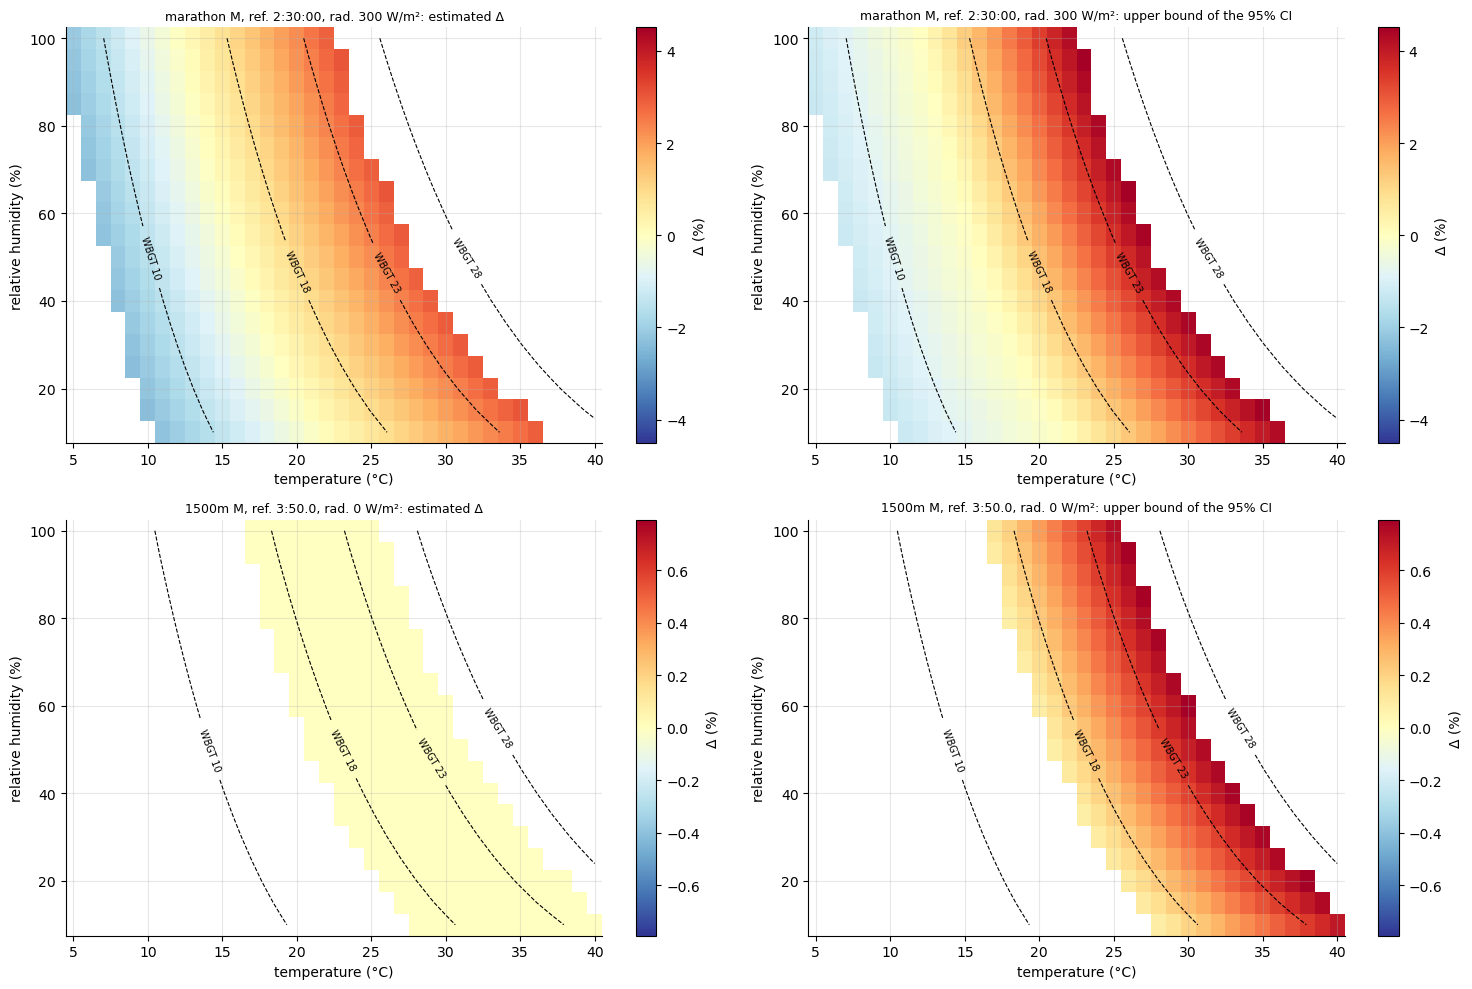

Men's marathon, 2:30:00 in reference conditions, radiation 300 W/m², wind 2 m/s:
estimated equivalent time / cautious time (bound of the 95% CI)
                    10 °C              15 °C              20 °C              25 °C              30 °C
RH 30%  2:27:03 / 2:28:20  2:28:48 / 2:29:20  2:30:34 / 2:30:51  2:32:21 / 2:33:30  2:34:09 / 2:36:11
RH 50%  2:27:40 / 2:28:41  2:29:34 / 2:29:45  2:31:30 / 2:32:14  2:33:27 / 2:35:09              — / —
RH 70%  2:28:14 / 2:29:00  2:30:16 / 2:30:24  2:32:20 / 2:33:28  2:34:27 / 2:36:38              — / —
RH 90%  2:28:46 / 2:29:18  2:30:55 / 2:31:21  2:33:06 / 2:34:37              — / —              — / —


In [89]:
def degradation_grille(modele, grille_w, epreuve, sexe, Y, vent=VENT_REF):
    '''Same computation as degradation (rain 0, altitude 0), vectorized over a WBGT grid: a single predict.'''
    base = df_tout[(df_tout["epreuve_norm"] == epreuve) & (df_tout["sexe"] == sexe)]
    if len(base) > 200:
        base = base.sample(200, random_state=SEED)
    t_y = DISTANCE[epreuve] / Y
    base = base.assign(niveau_pct=100 * np.log(t_y / RP_MEDIAN[(sexe, epreuve)]), log_duree=np.log(t_y / 60.0))
    p0 = modele.predict(base.assign(wbgt=WBGT_REF, vent_10m=VENT_REF, precipitation_mm_h=0.0, alt_km=0.0)).mean()
    d1 = pd.concat([base.assign(wbgt=w, vent_10m=vent, precipitation_mm_h=0.0, alt_km=0.0) for w in grille_w])
    return np.asarray(modele.predict(d1)).reshape(len(grille_w), len(base)).mean(axis=1) - p0

_gw = [WBGT_REF + 5.0, WBGT_REF + 12.0]
assert np.allclose(degradation_grille(MODELES_FINAUX[MODELE_OUTIL], _gw, "marathon", "M", 4.5),
                   [degradation(MODELES_FINAUX[MODELE_OUTIL], w, "marathon", "M", 4.5) for w in _gw], atol=1e-8)


def abaque(Y, epreuve, sexe, rayonnement=0.0, heure_locale=9.0, vent=VENT_REF, axes=None):
    T = np.arange(5, 41, 1.0); HR = np.arange(10, 101, 5.0)
    W = np.array([[calculer_wbgt(t, h, vent, rayonnement, heure_locale=heure_locale) for t in T] for h in HR])
    lo, hi = PLAGE_WBGT.loc[GROUPE_DE[epreuve]]
    gw = np.linspace(lo, hi, 30)
    dg = degradation_grille(MODELES_FINAUX[MODELE_OUTIL], gw, epreuve, sexe, Y, vent)
    db = np.array([degradation_grille(m, gw, epreuve, sexe, Y, vent) for m in BOOT[MODELE_OUTIL][1][:200]])
    hors = (W < lo) | (W > hi)
    D = np.where(hors, np.nan, np.interp(W, gw, dg))
    D_haut = np.where(hors, np.nan, np.interp(W, gw, np.quantile(db, 0.975, axis=0)))
    vmax = max(np.nanmax(np.abs(D_haut)), 0.5)
    for ax, Z, titre in zip(axes, [D, D_haut], ["estimated Δ", "upper bound of the 95% CI"]):
        im = ax.pcolormesh(T, HR, Z, cmap="RdYlBu_r", shading="nearest", vmin=-vmax, vmax=vmax)
        cs = ax.contour(T, HR, W, levels=[10, 18, 23, 28], colors="k", linewidths=0.8, linestyles="--")
        ax.clabel(cs, fmt="WBGT %g", fontsize=7)
        ax.set_xlabel("temperature (°C)"); ax.set_ylabel("relative humidity (%)")
        ax.set_title(f"{epreuve} {sexe}, ref. {chrono(Y, DISTANCE[epreuve])}, rad. {rayonnement:g} W/m²: {titre}", fontsize=9)
        plt.colorbar(im, ax=ax, label="Δ (%)")
    print(f"{epreuve} {sexe}: Δ from {np.nanmin(D):+.3f} to {np.nanmax(D):+.3f}; upper bound from {np.nanmin(D_haut):+.3f} to "
          f"{np.nanmax(D_haut):+.3f}; WBGT range {lo:.1f}-{hi:.1f} °C; {np.isnan(D).mean():.0%} of the cells out of range")
    return T, HR, W, D, D_haut

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
T_, HR_, W_, D_, Dh_ = abaque(DISTANCE["marathon"] / 9000, "marathon", "M", rayonnement=300.0, axes=axes[0])
_ = abaque(DISTANCE["1500m"] / 230, "1500m", "M", rayonnement=0.0, heure_locale=20.0, axes=axes[1])
plt.tight_layout(); plt.show()
Y_m = DISTANCE["marathon"] / 9000
sel_T, sel_H = [10, 15, 20, 25, 30], [30, 50, 70, 90]
tab = pd.DataFrame([[chrono(Y_m * np.exp(-D_[list(HR_).index(h), list(T_).index(t)] / 100), DISTANCE["marathon"]) + " / " +
                     chrono(Y_m * np.exp(-Dh_[list(HR_).index(h), list(T_).index(t)] / 100), DISTANCE["marathon"]) for t in sel_T] for h in sel_H],
                   index=[f"RH {h}%" for h in sel_H], columns=[f"{t} °C" for t in sel_T])
print("Men's marathon, 2:30:00 in reference conditions, radiation 300 W/m², wind 2 m/s:")
print("estimated equivalent time / cautious time (bound of the 95% CI)")
print(tab.to_string())

**Analysis.**

| men's marathon, 2:30 in reference conditions | 10 °C | 15 °C | 20 °C | 25 °C | 30 °C |
|---|---|---|---|---|---|
| $RH$ 30% | 2:27:03 / 2:28:20 | 2:28:48 / 2:29:20 | 2:30:34 / 2:30:51 | 2:32:21 / 2:33:30 | 2:34:09 / 2:36:11 |
| $RH$ 50% | 2:27:40 / 2:28:41 | 2:29:34 / 2:29:45 | 2:31:30 / 2:32:14 | 2:33:27 / 2:35:09 | – |
| $RH$ 70% | 2:28:14 / 2:29:00 | 2:30:16 / 2:30:24 | 2:32:20 / 2:33:28 | 2:34:27 / 2:36:38 | – |
| $RH$ 90% | 2:28:46 / 2:29:18 | 2:30:55 / 2:31:21 | 2:33:06 / 2:34:37 | – | – |

(estimated equivalent time / cautious time, that is, the bound of the 95% CI; sun of 300 W/m², wind of 2 m/s,
"–": outside the observed range)

**Marathon.** The WBGT isolines go down from left to right: at equal temperature, humidity increases the heat
load, and the sun alone adds several degrees of WBGT compared with the shade. $\Delta$ ranges from $-2.3$% (WBGT of 8
to 10 °C: one runs faster than in reference conditions) to $+3.0$% around 25 °C; the cautious bound ranges from $-1.3$ to $+4.5$%. At
22 °C, 70% and in the sun, the tool advises 2:33:10, that is, about 3:38 per kilometer instead of 3:33. **41% of
the cells are white**: humid heat (25 °C and 90%, or 30 °C above 30% humidity) and dry cold. The tool refuses
to answer there rather than extrapolate a straight line.

**1,500 m.** $\Delta$ is zero (less than 0.01 point in absolute value) over the whole covered range, from 16 to 25.6 °C; the
upper bound stays below 0.8%, less than 2 seconds over 3:50. **70% of the grid is white**: there is no cool track
meeting in the data, and the tool therefore says nothing about a 1,500 m in cool weather.

**Pacing advice.** Over 1,500 m, no adjustment. In the marathon, slow down by 1 to 1.5% per 5 °C of WBGT
above 15 °C, and aim for the cautious bound if you do not know your heat tolerance. These figures are
**averages** for good runners, acclimatized or not, without distinction; individual tolerance, acclimatization
and hydration can matter much more. Beyond 23 °C of WBGT (ACSM red flag), the issue
becomes **safety** more than the race time.

## Part 11 — Critical discussion

This last part examines the robustness of the results: sensitivity to the choice of the truncation margin, validity of
the target, possible biases and their direction, generalization, and avenues for improvement.

**Sensitivity to the truncation margin.** Part 1.5 studied the raw slope of $y$ on the WBGT as a function of the
minimum margin $M$. We repeat the exercise with the model of the tool: for each $M \in \{0, 3, 5, 8, 12\}$ %, the
model is re-estimated on the valid performances with a margin at least equal to $M$, and we compute the effect of an increase of the
WBGT from 15 to 25 °C in each event group. If truncation attenuates the effect of heat (part 1.5), this
effect must increase with $M$.

In [90]:
# A point for the discussion: sensitivity of the heat effect to the truncation margin M
df_c = ajouter_variables(df_complet)
lignes = []
for M in [0, 3, 5, 8, 12]:
    d_m = df_c[df_c["marge_troncature_pct"] >= M]
    m = PipelineOutil().fit(d_m)
    ref = pd.concat([g.sample(min(200, len(g)), random_state=SEED) for _, g in d_m.groupby("groupe_epreuve")])
    lignes.append({"M (%)": M, "n": len(d_m), **{NOMS_EN[g]: round(courbe_degradation(m, ref[ref["groupe_epreuve"] == g], [WBGT_REF + 10])[0], 3)
                                                  for g in GROUPES}})
print(f"Effect of a 10 °C WBGT increase (points of y) by minimum margin M:")
print(pd.DataFrame(lignes).to_string(index=False))

Effect of a 10 °C WBGT increase (points of y) by minimum margin M:
 M (%)     n  track middle distance  track long distance  short road  half marathon  marathon
     0 14221                 -0.060                0.502       1.083          1.736     3.356
     3 12275                  0.006                0.533       1.299          1.711     3.227
     5 10398                  0.036                0.824       1.522          1.776     3.142
     8  7637                 -0.016                0.787       1.619          1.878     3.160
    12  4514                 -0.336                1.861       1.716          1.443     3.020


**Analysis.**

| minimum margin $M$ | performances | track middle distance | track long distance | short road | half marathon | marathon |
|---|---|---|---|---|---|---|
| 0% | 14,221 | $-0.06$ | 0.50 | 1.08 | 1.74 | 3.36 |
| 3% | 12,275 | 0.01 | 0.53 | 1.30 | 1.71 | 3.23 |
| 5% | 10,398 | 0.04 | 0.82 | 1.52 | 1.78 | 3.14 |
| 8% | 7,637 | $-0.02$ | 0.79 | 1.62 | 1.88 | 3.16 |
| 12% | 4,514 | $-0.34$ | 1.86 | 1.72 | 1.44 | 3.02 |

(effect of a WBGT increase from 15 to 25 °C, in points of $y$)

**Truncation is bounded.** In the marathon, the effect stays between **3.0 and 3.4 points** when $M$ varies from 0 to 12%: the
main result is robust to the choice of the margin. On short road races, it goes from 1.1 to 1.7 points as $M$ increases,
which is in the direction of an attenuation by truncation (part 1.5). Middle distance stays close to 0 whatever
$M$. The values at $M = 12$% rest on samples reduced by half, and track long distance becomes unstable there.
In the marathon, the effect even decreases slightly as $M$ increases (from 3.36 to 3.02), unlike the raw slope of
part 1.5: once the controls are introduced, truncation no longer biases the effect there in a detectable way, and these gaps
remain within the margin of uncertainty of the estimates (part 8.4).

#### Validity of the target

$y = 100\ln(t/t^{\text{PB}})$ assumes a maximal effort and a personal best representative of the level of the day.

* The personal best may be **old**: $y$ increases strongly with age (part 1.4), and age, form and level only
  correct for it on average.
* The data set does not follow athletes: the comparison is made **between** similar runners, not within the same
  runner. A within-athlete design (the same runner in different conditions) would be more convincing.
* 6,222 performances without a published personal best (beginners over the distance, or missing data) are excluded:
  the sample overrepresents experienced runners.

#### Possible biases and their direction

* **Measurement error in the weather attenuates the effects.** The weather comes from a reanalysis with a 9-30 km resolution,
  without microclimate (urban heat island, stands); on the track, the time is that of the start of the meeting and not of the
  race. If we observe $W^{\text{obs}} = W + \epsilon_W$ instead of the true WBGT $W$, with an error $\epsilon_W$
  independent of $W$ and $y$, the estimated slope tends to

  $$\beta_W\,\frac{\text{Var}(W)}{\text{Var}(W) + \text{Var}(\epsilon_W)} < \beta_W:$$

  this is **attenuation bias** (or dilution). A random measurement error always pulls the effect toward 0, and
  all the more so as the useful variation of the WBGT is small, which is the case for within-course variation (part
  2.3).
* **Selection underestimates the effect.** In strong heat, dropouts are not listed, and some runners
  give up or "play it safe". The effect is underestimated for the maximal race time; it is nevertheless partly what a runner
  wants to know: by how much to slow down to finish.
* **Confounding between venues remains possible.** Heat is mostly observed **between** venues (100 venues, 396 races),
  with a within-course standard deviation of only about 1 °C. Country, field and course profile are only
  imperfectly controlled, even though fixed effects and the Mundlak term agree with random effects
  (part 4.2).
* **Heteroscedasticity is only worked around.** The within-race standard deviation of $y$ doubles between the track and the marathon
  (1.9 against 3.6 points). The mixed model with a common $\sigma^2$ has a bimodal likelihood, worked around by fixing
  $\gamma$ (part 8.4) but not corrected.
* **Prediction intervals depend on exchangeability.** Part 9 showed that an unrepresentative calibration
  fold makes the guaranteed coverage be lost.

#### Generalization

The data cover good-level runners, a WBGT of 5 to 28 °C, the track only between 13.5 and 26 °C in the
evening, and altitude only on the road (8 venues above 1,000 m). Nothing allows extrapolation to recreational runners
(more affected according to Ely *et al.*), to heatwaves, to championships in tropical climates or to middle distance in
cold weather. For **training** at submaximal pace, "same effort" refers rather to heart rate or to
perceived exertion: the tool does not transfer directly to it.

#### Avenues for improvement

* **Complete** lists (all finishers, dropouts included), hence without truncation, and athlete
  identifiers, for a within-athlete design.
* The actual start times, nearby weather stations and course profiles (elevation gain, turns).
* A **heteroscedastic** mixed model ($\sigma^2$ specific to each event group), crossed random effects
  athlete × race, or a hierarchical Bayesian model that shrinks the effect of heat of one event group toward
  that of the others and allows a common curvature.
* Conformal calibration on several folds, or by event group (part 9).
* A joint model of dropout and performance, to handle selection.
* Heart rate data, to transfer the tool to training.

#### Conclusion

At equal effort, when the WBGT goes from 15 to 25 °C, heat costs **nothing measurable over 800 m and 1,500 m**,
about **1.5% over 5 and 10 km** and about **3% in the marathon**. Wind costs about 0.2% per m/s at equal WBGT, and
altitude weighs on road races, with large uncertainty. In prediction, the four families of models are on a par, and
about one sixth of the variance of performances is predictable on a new venue; the rest is a matter of form on the
day. On the methodological side, four lessons emerge: validate by **groups** (venues) when the data are
structured, estimate uncertainty with a bootstrap of the **same** groups, distinguish **predicting** and **estimating an
effect**, and prefer a tool that gives an honest interval and refuses to extrapolate.

In [91]:
print(f"Total run time of the notebook: {(time.time() - t0_notebook) / 60:.1f} min")

Total run time of the notebook: 5.9 min


### References

* Aitken A. C. (1935). On least squares and linear combination of observations. *Proc. R. Soc. Edinburgh* 55, 42-48.
* Armstrong L. E. *et al.* (2007). American College of Sports Medicine position stand. Exertional heat illness during
  training and competition. *Med. Sci. Sports Exerc.* 39(3), 556-572.
* Bergstra J., Bengio Y. (2012). Random search for hyper-parameter optimization. *JMLR* 13, 281-305.
* Breiman L., Friedman J., Olshen R., Stone C. (1984). *Classification and Regression Trees*. Wadsworth.
* Brent R. P. (1973). *Algorithms for Minimization without Derivatives*. Prentice-Hall.
* Cybenko G. (1989). Approximation by superpositions of a sigmoidal function. *Math. Control Signals Syst.* 2(4),
  303-314.
* Efron B. (1979). Bootstrap methods: another look at the jackknife. *Ann. Stat.* 7(1), 1-26.
* Ely M. R., Cheuvront S. N., Roberts W. O., Montain S. J. (2007). Impact of weather on marathon-running performance.
  *Med. Sci. Sports Exerc.* 39(3), 487-493.
* Friedman J. H. (2001). Greedy function approximation: a gradient boosting machine. *Ann. Stat.* 29(5), 1189-1232.
* Goldstein A., Kapelner A., Bleich J., Pitkin E. (2015). Peeking inside the black box: visualizing statistical
  learning with plots of individual conditional expectation. *J. Comput. Graph. Stat.* 24(1), 44-65.
* Grinsztajn L., Oyallon E., Varoquaux G. (2022). Why do tree-based models still outperform deep learning on typical
  tabular data? *NeurIPS, Datasets and Benchmarks Track*.
* Hastie T., Tibshirani R., Friedman J. (2009). *The Elements of Statistical Learning*, 2nd ed. Springer.
* Hersbach H. *et al.* (2020). The ERA5 global reanalysis. *Q. J. R. Meteorol. Soc.* 146, 1999-2049.
* Hornik K. (1991). Approximation capabilities of multilayer feedforward networks. *Neural Networks* 4(2), 251-257.
* Ke G. *et al.* (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.
* Kingma D. P., Ba J. (2015). Adam: a method for stochastic optimization. *ICLR*.
* Kish L. (1965). *Survey Sampling*. Wiley.
* Leshno M., Lin V. Y., Pinkus A., Schocken S. (1993). Multilayer feedforward networks with a nonpolynomial activation
  function can approximate any function. *Neural Networks* 6(6), 861-867.
* Liljegren J. C., Carhart R. A., Lawday P., Tschopp S., Sharp R. (2008). Modeling the wet bulb globe temperature using
  standard meteorological measurements. *J. Occup. Environ. Hyg.* 5(10), 645-655.
* Lorenzo S., Halliwill J. R., Sawka M. N., Minson C. T. (2010). Heat acclimation improves exercise performance.
  *J. Appl. Physiol.* 109(4), 1140-1147.
* Loshchilov I., Hutter F. (2019). Decoupled weight decay regularization. *ICLR*.
* Lundberg S. M., Lee S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.
* Mantzios K. *et al.* (2022). Effects of weather parameters on endurance running performance: discipline-specific
  analysis of 1258 races. *Med. Sci. Sports Exerc.* 54(1), 153-161.
* Mundlak Y. (1978). On the pooling of time series and cross section data. *Econometrica* 46(1), 69-85.
* Patterson H. D., Thompson R. (1971). Recovery of inter-block information when block sizes are unequal.
  *Biometrika* 58(3), 545-554.
* Racinais S. *et al.* (2015). Consensus recommendations on training and competing in the heat. *Br. J. Sports Med.*
  49(18), 1164-1173.
* Romano Y., Patterson E., Candès E. (2019). Conformalized quantile regression. *NeurIPS*.
* Rønnestad B. R. *et al.* (2022). Heat suit training increases hemoglobin mass in elite cross-country skiers.
  *Scand. J. Med. Sci. Sports* 32(7), 1089-1098.
* Shapley L. S. (1953). A value for n-person games. *Contributions to the Theory of Games* II, 307-317.
* Srivastava N., Hinton G., Krizhevsky A., Sutskever I., Salakhutdinov R. (2014). Dropout: a simple way to prevent
  neural networks from overfitting. *JMLR* 15, 1929-1958.
* Telgarsky M. (2016). Benefits of depth in neural networks. *COLT*.
* Zippenfenig P. (2023). Open-Meteo.com Weather API. Zenodo, doi:10.5281/ZENODO.7970649.